# Tuberculosis Classification using Chest X-ray with CNNs, Lung Segmentation + LIME (0.99 accuracy)

# Outlines

1. Data Preprocessing
    - 1.1 Data Transforming
        - 1.1.1 Image Conversion
        - 1.1.2 Image Resizing
        - 1.1.3 Image Mode Consistency
        - 1.1.4 Image Cropping
            - 1.1.4.1 Distribution of Intensity Analysis  $X_{Normal}$ VS $X_{Tuberulosis}$
            - 1.1.4.2 Identify Abnormal Image
            - 1.1.4.3 Remove Background
                - 1.1.4.3.1 Type of Threshold
                - 1.1.4.3.2 Remove Blank Background
    - 1.2 Data Augmentation (Class imbalance problem - Oversamping) (Optional):
    - 1.3 Normalizing the pixel values
    - 1.4 Data Preparation
        - 1.4.1 Original (Class Imbalanced)
        - 1.4.2 Over-sampling (Class Balanced)
        - 1.4.3 Under-sampling (Class Balanced)
    - 1.5 Image Enhancement
        - 1.5.1 Contrast Stretching
        - 1.5.2 Histogram Equalization
        - 1.5.3 Adaptive Histogram Equalization
        - 1.5.4 Summary of each image enhancement
2. CNN:
    - 2.1 How CNNs Work
    - 2.2 Layers
        - 2.2.1 Convolutional Layers
        - 2.2.2 Pooling Layers
        - 2.2.3 Dropout Layer
        - 2.2.4 Flatten Layer
        - 2.2.5 Fully Connected (Dense) Layers
        - 2.2.6 Output Layers
    - 2.3 Hyperparameters in both convolutional and pooling layers
        - 2.3.1 Padding
        - 2.3.2 Kernel size
        - 2.3.3 Stride
    - 2.4 Activation Functions
        - 2.4.1 ReLU Activation function
        - 2.4.2 Sigmoid Activation function
    - 2.5 Adam Optimizer in Tensorflow
    - 2.6 CNN Classifier with GridSearchCV
3. Splitting the Dataset 80:10:10
4. Modeling
    - 4.1 Experimental Plan
        - 4.1.1. Experiment A - Baseline Performance
        - 4.1.2. Experiment B - Data Sampling Technique or Data Augmentation
        - 4.1.3. Experiment C - Image Size
        - 4.1.4. Experiment D - Image Mode: RGB vs. Grayscale
        - 4.1.5. Experiment E - Image Enhancement
        - 4.1.6. Model Benchmark/Model Comparison
    - 4.2 Train for Best Artifact
    - 4.3 Model Evaluation
        - 4.3.1 Confusion Matrix
        - 4.3.2 ROC Curve
        - 4.3.3 Cross-validation (Skipped, Because of Memory constraint)
    - 4.4 Hyperparameter Tuning (Skipped, Because of Memory constraint)
    - 4.5 Compare Actual X-ray Images with Model Predictions.
5. Lung segmentation
    - 5.1 Equalize the Image with CLAHE
    - 5.2 Create a Binary Threshold Mask
    - 5.3 Perform Morphological Operations
        - 5.3.1 Morphological: Closing
        - 5.3.2 Morphological: Dilation
    - 5.4 Label Image Regions
    - 5.5 Create Overlay Image
6. Explainability
    - 6.1 Lime Library
    - 6.2 Different segmentation methods on an image
        - Felzenszwalb
        - SLIC (Simple Linear Iterative Clustering)
        - Quickshift
        - Watershed
        - [Reference Lung Segmentation](https://www.kaggle.com/code/davidbroberts/lung-segmentation-without-cnn/notebook)
    - 6.3 Lime Image Explainer

# Problem Statment
Tuberculosis (TB) remains a significant global health issue, affecting millions of people worldwide. Timely and accurate diagnosis is crucial for effective management and control of the disease. Chest X-ray (CXR) imaging is a common diagnostic tool for TB, providing detailed insights into the condition of the lungs. Convolutional Neural Networks (CNNs) have demonstrated remarkable capabilities in image classification tasks, making them a promising technology for automated TB detection.

# Problem in dataset
The dataset consists of:
- Classes: 700 Tuberculosis images /  3500 normal images. (Class imbalance)
- File type: .PNG
- Image size: 512x512 
- Image Mode: 3 channel (RGB)

In [1]:
from PIL import Image
import seaborn as sns
import matplotlib.pyplot as plt

### View the variables 
<u>Read</u> 5 Training examples, And <u>check</u> the dimensions of raw data

In [2]:
dir_path = '../input/tuberculosis-tb-chest-xray-dataset/TB_Chest_Radiography_Database'

Subset: Normal
Index: 1
File name: Normal-1.png
Mode: RGB
Size: (512, 512)


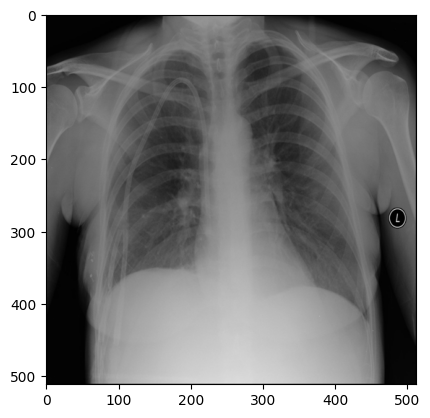

Index: 2
File name: Normal-2.png
Mode: RGB
Size: (512, 512)


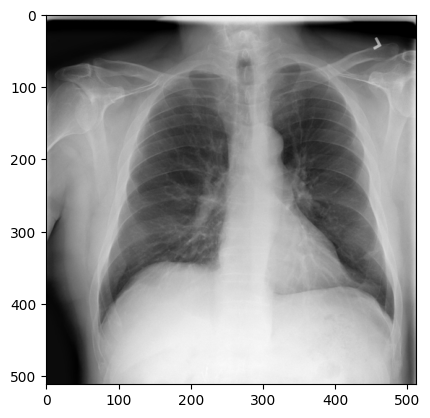

Index: 3
File name: Normal-3.png
Mode: RGB
Size: (512, 512)


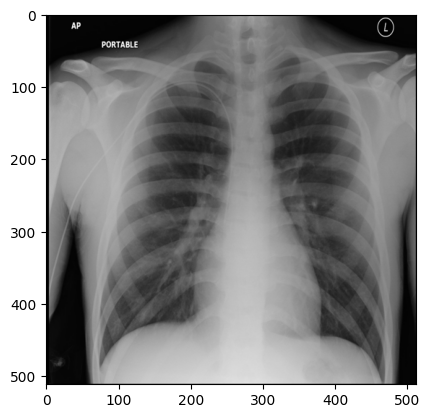

Index: 4
File name: Normal-4.png
Mode: RGB
Size: (512, 512)


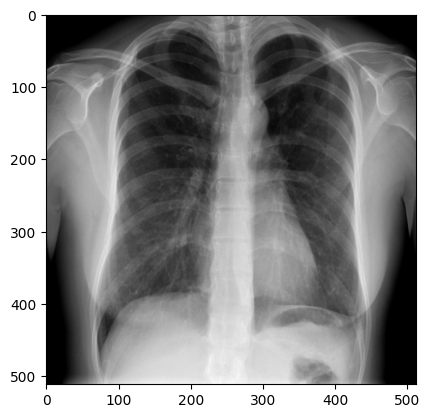

Subset: Tuberculosis
Index: 1
File name: Tuberculosis-1.png
Mode: RGB
Size: (512, 512)


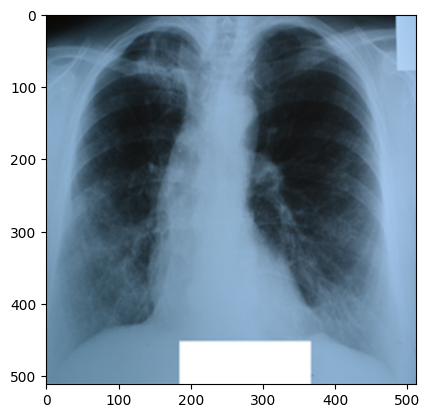

Index: 2
File name: Tuberculosis-2.png
Mode: RGB
Size: (512, 512)


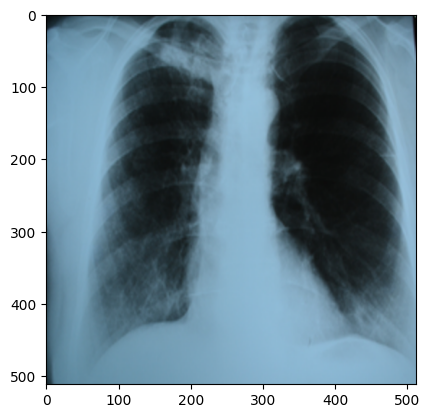

Index: 3
File name: Tuberculosis-3.png
Mode: RGB
Size: (512, 512)


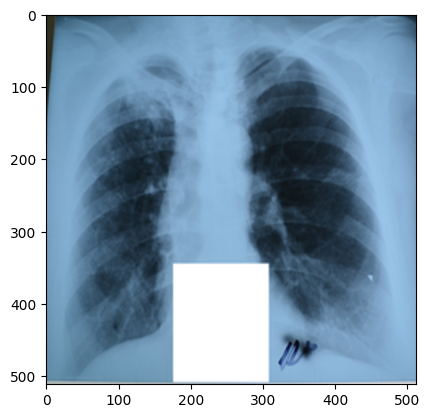

Index: 4
File name: Tuberculosis-4.png
Mode: L
Size: (512, 512)


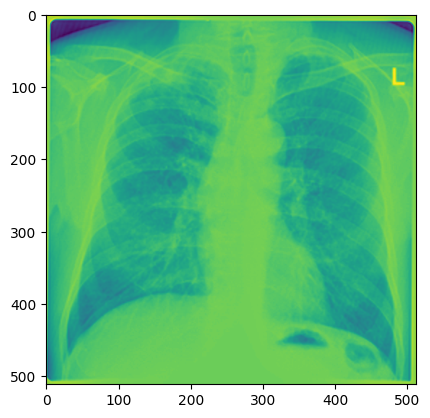

In [3]:
for subset in ['Normal','Tuberculosis']:
    
    
    prefix_bold = "\033[1m"
    suffix_bold = "\033[0m"
    print(f"{prefix_bold}Subset: {subset}{suffix_bold}")
    
    # range(start, stop, step)
    for i in range(1,5):
        
        image = Image.open(
            f"{dir_path}/{subset}/{subset}-{i}.png")
        print(f"Index: {i}")
        print(f"File name: {subset}-{i}.png")
        print(f"Mode: {image.mode}")
        print(f"Size: {image.size}")
        plt.imshow(image)
        plt.show()
        

In [4]:
import os
from tqdm import tqdm
import pandas as pd
import numpy as np

### Data Check-up
<u>explore</u> the dimensions and image information of raw data 

In [5]:
def Image_info_checker(subset, dir_path):
    image_dir = os.path.join(dir_path, subset)
    image_files = os.listdir(image_dir)
    image_count = len(image_files)
    
    data = []
    
    for i in tqdm(range(1, image_count + 1), desc='Checking...'):
        image_path = os.path.join(image_dir, f'{subset}-{i}.png')
        image = Image.open(image_path)
        
        img_name = f'{subset}-{i}.png'
        img_mode = image.mode
        img_size = image.size
        img_format = image.format
        img_channels = image.getbands()
        img_histogram = tuple(image.histogram()) # Convert to tuple for to use with "Plot", Because "image.histogram()"" will return as a list
        img_mean = np.mean(image)
        img_std = np.std(image)
        
        data.append({'image_name': img_name, 'mode': img_mode, 'size': img_size, 'format': img_format,
                     'channels': img_channels, 'histogram': img_histogram, 'mean': img_mean, 'std': img_std, 'image_path': image_path})
        
    # Convert data to DataFrame
    df = pd.DataFrame(data)
    def summary(df, subset, dir_path):
        print(f"{prefix_bold}Directory path{suffix_bold}: {dir_path}")
        print(f"{prefix_bold}Subset{suffix_bold}: {subset}")
        print(f"{prefix_bold}Size{suffix_bold}:\n")
        print(df['size'].value_counts().to_string(header=False))
        print(f"\n{prefix_bold}Format{suffix_bold}:\n")
        print(df['format'].value_counts().to_string(header=False))
        print(f"\n{prefix_bold}Mode{suffix_bold}:\n")
        print(df['mode'].value_counts().to_string(header=False))
        print(f"\n{prefix_bold}Mean{suffix_bold}: {df['mean'].mean()}")
        print(f"{prefix_bold}Std.{suffix_bold}: {df['std'].std()}")
    summary(df, subset, image_dir)
    return df

### Normal subset

In [6]:
normal_df = Image_info_checker(subset='Normal', dir_path=dir_path)

Checking...: 100%|██████████| 3500/3500 [01:15<00:00, 46.36it/s]

Directory path: ../input/tuberculosis-tb-chest-xray-dataset/TB_Chest_Radiography_Database/Normal
Subset: Normal
Size:

(512, 512)    3500

Format:

PNG    3500

Mode:

RGB    3500

Mean: 130.12328073120116
Std.: 9.90307293659762


In [7]:
normal_df

,image_name,mode,size,format,channels,histogram,mean,std,image_path
0,Normal-1.png,RGB,"(512, 512)",PNG,"(R, G, B)","(218, 143, 3758, 12477, 2452, 1582, 1221, 682,...",102.364891,53.606645,../input/tuberculosis-tb-chest-xray-dataset/TB...
1,Normal-2.png,RGB,"(512, 512)",PNG,"(R, G, B)","(3355, 434, 266, 283, 340, 265, 394, 711, 1381...",139.430801,65.014435,../input/tuberculosis-tb-chest-xray-dataset/TB...
2,Normal-3.png,RGB,"(512, 512)",PNG,"(R, G, B)","(1866, 176, 193, 1497, 6090, 5735, 2442, 1844,...",109.339588,55.383087,../input/tuberculosis-tb-chest-xray-dataset/TB...
3,Normal-4.png,RGB,"(512, 512)",PNG,"(R, G, B)","(15833, 422, 297, 216, 248, 219, 211, 231, 237...",109.818092,63.365622,../input/tuberculosis-tb-chest-xray-dataset/TB...
4,Normal-5.png,RGB,"(512, 512)",PNG,"(R, G, B)","(7261, 245, 87, 103, 166, 373, 909, 838, 790, ...",173.156345,55.115098,../input/tuberculosis-tb-chest-xray-dataset/TB...
...,...,...,...,...,...,...,...,...,...
3495,Normal-3496.png,RGB,"(512, 512)",PNG,"(R, G, B)","(8159, 2307, 1840, 1610, 833, 465, 336, 305, 3...",131.891762,66.806954,../input/tuberculosis-tb-chest-xray-dataset/TB...
3496,Normal-3497.png,RGB,"(512, 512)",PNG,"(R, G, B)","(15503, 6186, 1561, 1102, 927, 900, 973, 832, ...",114.717613,68.146951,../input/tuberculosis-tb-chest-xray-dataset/TB...
3497,Normal-3498.png,RGB,"(512, 512)",PNG,"(R, G, B)","(6949, 975, 903, 1083, 428, 367, 337, 237, 310...",118.028065,61.540312,../input/tuberculosis-tb-chest-xray-dataset/TB...
3498,Normal-3499.png,RGB,"(512, 512)",PNG,"(R, G, B)","(1160, 758, 1341, 2267, 3298, 7228, 28889, 371...",93.946030,70.984008,../input/tuberculosis-tb-chest-xray-dataset/TB...


### Tuberculosis subset

In [8]:
tb_df = Image_info_checker(subset='Tuberculosis', dir_path=dir_path)

Checking...: 100%|██████████| 700/700 [00:12<00:00, 56.93it/s]

Directory path: ../input/tuberculosis-tb-chest-xray-dataset/TB_Chest_Radiography_Database/Tuberculosis
Subset: Tuberculosis
Size:

(512, 512)    700

Format:

PNG    700

Mode:

RGB    392
L      308

Mean: 126.24992087227957
Std.: 15.026967536681612


In [9]:
tb_df

,image_name,mode,size,format,channels,histogram,mean,std,image_path
0,Tuberculosis-1.png,RGB,"(512, 512)",PNG,"(R, G, B)","(0, 0, 0, 0, 0, 0, 0, 0, 0, 12, 196, 314, 193,...",122.455050,61.344179,../input/tuberculosis-tb-chest-xray-dataset/TB...
1,Tuberculosis-2.png,RGB,"(512, 512)",PNG,"(R, G, B)","(0, 0, 0, 0, 4, 10, 3, 3, 5, 5, 283, 1473, 218...",111.781446,61.594115,../input/tuberculosis-tb-chest-xray-dataset/TB...
2,Tuberculosis-3.png,RGB,"(512, 512)",PNG,"(R, G, B)","(2, 1, 2, 5, 5, 5, 6, 4, 3, 6, 9, 13, 12, 16, ...",139.624195,63.129705,../input/tuberculosis-tb-chest-xray-dataset/TB...
3,Tuberculosis-4.png,L,"(512, 512)",PNG,"(L,)","(0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",202.507851,17.240465,../input/tuberculosis-tb-chest-xray-dataset/TB...
4,Tuberculosis-5.png,L,"(512, 512)",PNG,"(L,)","(6136, 1002, 739, 163, 149, 68, 179, 108, 92, ...",126.624260,39.589117,../input/tuberculosis-tb-chest-xray-dataset/TB...
...,...,...,...,...,...,...,...,...,...
695,Tuberculosis-696.png,RGB,"(512, 512)",PNG,"(R, G, B)","(12076, 3616, 3478, 3605, 3487, 2049, 1301, 10...",90.744830,60.534069,../input/tuberculosis-tb-chest-xray-dataset/TB...
696,Tuberculosis-697.png,RGB,"(512, 512)",PNG,"(R, G, B)","(33212, 8461, 3136, 1518, 883, 709, 695, 666, ...",98.036168,67.193748,../input/tuberculosis-tb-chest-xray-dataset/TB...
697,Tuberculosis-698.png,RGB,"(512, 512)",PNG,"(R, G, B)","(48, 162, 1376, 1047, 648, 420, 325, 268, 348,...",111.165043,56.632791,../input/tuberculosis-tb-chest-xray-dataset/TB...
698,Tuberculosis-699.png,RGB,"(512, 512)",PNG,"(R, G, B)","(313, 506, 432, 786, 1260, 1723, 2710, 2519, 2...",101.515010,53.325925,../input/tuberculosis-tb-chest-xray-dataset/TB...


### Image Distribution
<u>Explore</u> the image distribution

In [10]:
def plot_image_and_histogram(subset, index, title = 'Image and Histogram'):
    # Load the image
    image = Image.open(f"{dir_path}/{subset}/{subset}-{index}.png")
    
    # Check if the image is grayscale (mode 'L')
    if image.mode == 'L':
        # Create subplots with 1 row and 2 columns
        fig, axs = plt.subplots(1, 2, figsize=(12, 6))

        # Plot the image in the first column
        axs[0].imshow(image, cmap='gray')
        sub_title = f"""Image\n
        Index: {index},
        File name: {subset}-{index}.png,
        Mode: {image.mode},
        Size: {image.size}
        """
        axs[0].set_title(sub_title, loc='left')

        # Plot the histogram for the grayscale image in the second column
        axs[1].hist(image.getdata(), bins=256, color='gray', alpha=0.5, label='Gray', histtype='step')
        axs[1].set_xlabel('Intensity')
        axs[1].set_ylabel('Frequency')
        axs[1].set_title('Histogram of the Grayscale Image')
         # Add big title
        fig.suptitle(title, fontsize=16, fontweight='bold')
        # Adjust layout to prevent overlap
        plt.tight_layout()
        plt.show()
    else:
        # For RGB images, split channels and plot as before
        r, g, b = image.split()
        fig, axs = plt.subplots(1, 2, figsize=(15, 6))
        axs[0].imshow(image)
        sub_title = f"""Image\n
        Index: {index},
        File name: {subset}-{index}.png,
        Mode: {image.mode},
        Size: {image.size}
        """
        axs[0].set_title(sub_title, loc='left')
        axs[1].hist(r.getdata(), bins=256, color='red', alpha=0.5, label='Red', histtype='step')
        axs[1].hist(g.getdata(), bins=256, color='green', alpha=0.5, label='Green', histtype='step')
        axs[1].hist(b.getdata(), bins=256, color='blue', alpha=0.5, label='Blue', histtype='step')
        axs[1].set_xlabel('Intensity')
        axs[1].set_ylabel('Frequency')
        axs[1].set_title('Histogram of the Image Channels')
        axs[1].legend()
         # Add big title
        fig.suptitle(title, fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()

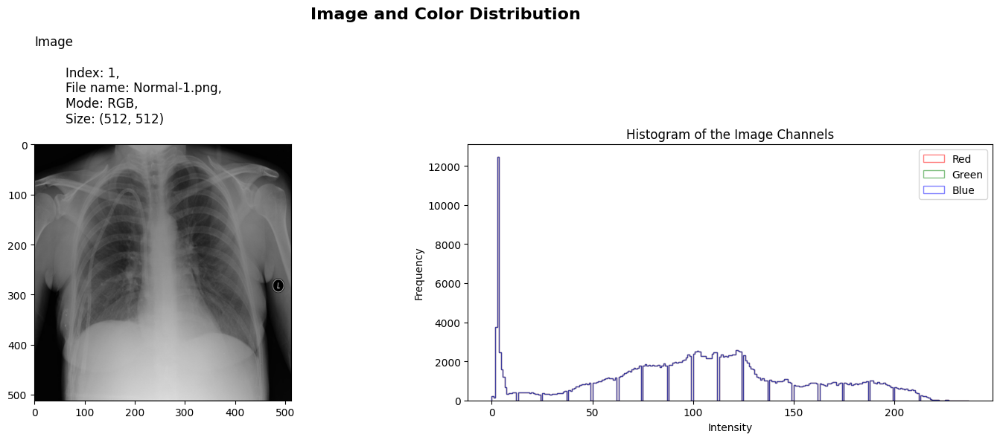

In [11]:
# Usage example:
plot_image_and_histogram(subset= 'Normal', 
                         index=1, 
                         title = "Image and Color Distribution")

**Explaination (1)**: `Image(Normal-1.png)`.Mode is `RGB`, <u>But</u>, as you can see, the histogram is displayed as a grayscale distribution. It appears that the distribution in each channel is equal.

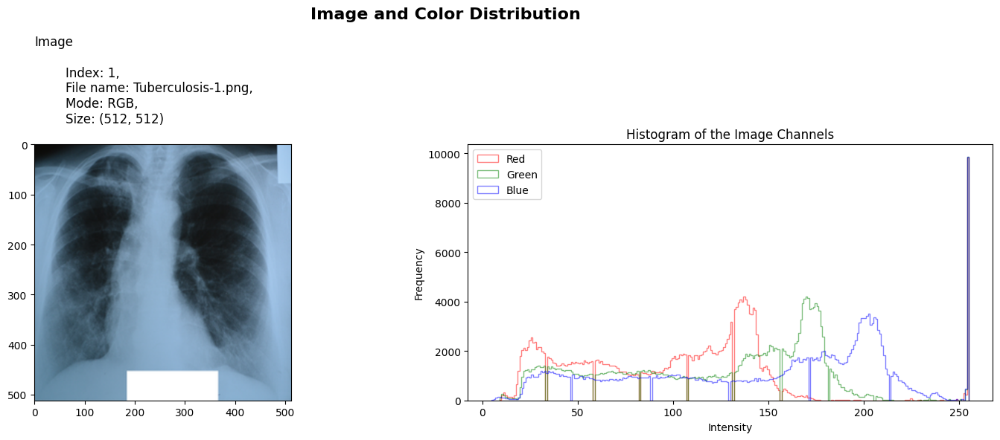

In [12]:
# Usage example:
plot_image_and_histogram(subset= 'Tuberculosis', 
                         index=1,
                         title = "Image and Color Distribution")

**Explaination (2)**: `Image(Tuberculosis-1.png)` the histogram will be separated into three channels (Red, Green, and Blue)

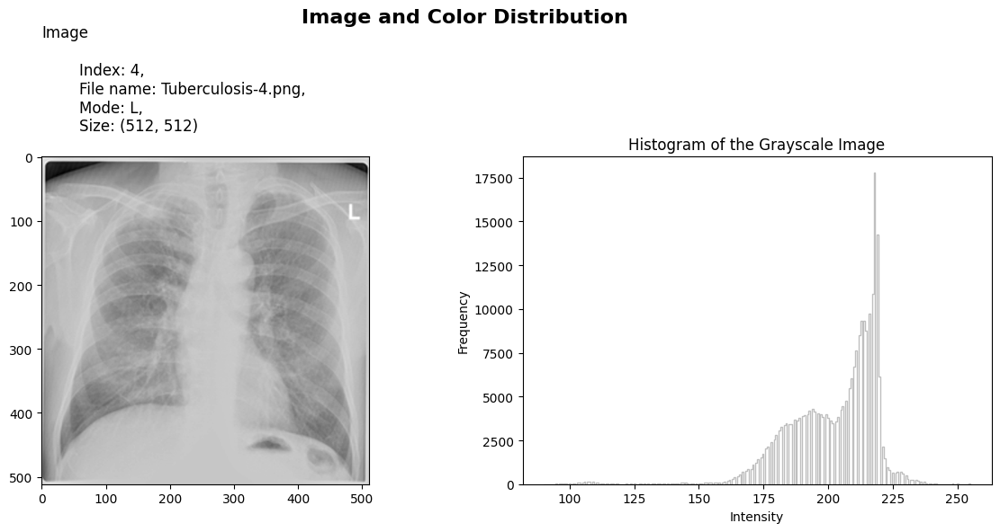

In [13]:
plot_image_and_histogram(subset= 'Tuberculosis', 
                         index=4, 
                         title = "Image and Color Distribution")

**Explaination (3)**: `Image(Tuberculosis-4.png)`.Mode is `L`, the histogram will be Gray Scale

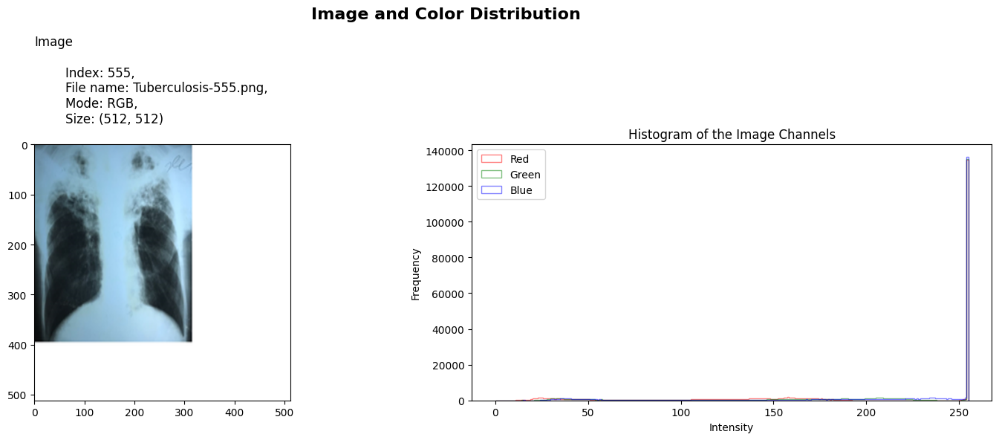

In [14]:
plot_image_and_histogram(subset= 'Tuberculosis', 
                         index=555, 
                         title = "Image and Color Distribution")

**Explaination (4)**: `Image(Tuberculosis-555.png)` contains some regions with `blank white space` that need to be removed. To achieve this, we will `remove` the blank white space and `crop` the image.

# 1. Data Preprocessing

## 1.1 Data Transforming

### 1.1.1 Image Conversion

**Problem:** The dataset (Raw data) consists of .png files, making manipulation difficult.

**Objective:** Convert **Image.PNG** files to NumPy Arrays for easier manipulation, optimize and faster.

- **Pros:**
    - **Memory Efficiency:** NumPy arrays require less memory than raw image files, making them ideal for large datasets.
    - **Computational Efficiency:** NumPy array operations are optimized and faster.
- **Cons:**
    - **Lossy Compression:** Converting images to NumPy arrays may reducing image quality.
    - **Storage and Disk Space:** NumPy arrays can still consume significant disk space

### 1.1.2 Image Resizing

**Problem:** The dataset (Raw data) consists of images with varying sizes, necessitating consistency with other images in the dataset.

**Objective:** Resize images from 512 x 512 to 128 x 128 for memory and processing time constraints.

- **Pros:**
    - **Standardization:** Resizing ensures all images have the same dimensions
    - **Memory Optimization:** Smaller image sizes reduce memory usage
- **Cons:**
    - **Loss of Detail:** Resizing may result in a loss of image detail

### 1.1.3 Image Mode Consistency

**Problem:** The dataset (Raw data) contains images with various color modes, requiring consistency.

**Objective:** Convert all images to the same mode (e.g., "Gray Scale", "RGB", "L") to ensure uniformity, preferably to "RGB".

- **Pros:**
    - **Visualization:** Converting to a common mode like RGB enables easier visualization and interpretation.
- **Cons:**
    - **Information Loss:** Converting to a single color mode may result in the loss of certain color or intensity information present in the original images.

In [15]:
import numpy as np
from numpy import asarray
import os
from tqdm import tqdm

In [16]:
def numpize(subset: str, label: int, img_size=(128, 128), grayscale=False):
    """
    Convert a set of images from a specified subset to NumPy arrays.

    Parameters:
    - subset (str): Specifies the subset of images, e.g., 'Normal' or 'Tuberculosis'.
    - label (int): Represents the label or class associated with the subset of images.
        - 'Normal'represented as 0,  
        - 'Tuberculosis' represented as 1
    - img_size (tuple): Tuple representing the desired size of the images after resizing.
    - grayscale (bool): If True, convert images to grayscale.

    Returns:
    - numpy_array (numpy.ndarray): NumPy array containing the transformed images.
    """
    image_dir = f'{dir_path}/{subset}/'
    image_files = os.listdir(image_dir)
    image_count = len(image_files)
    transformed_images = []
    labels = []
    for i in tqdm(range(1, image_count + 1), desc='Transforming...'):
        image_path = f'{image_dir}/{subset}-{i}.png'
        image = Image.open(image_path)

        # Ensure all images are in the same format
        if grayscale:
            image = image.convert('L')  # Convert to grayscale
        else:
            image = image.convert('RGB')  # Convert to RGB

        # Resize all images to the specified size without padding
        resized_image = image.resize(img_size)
        data = np.asarray(resized_image)
        # Achieve into list
        transformed_images.append(data)
        labels.append(label)

    images_numpy_array = np.array(transformed_images)
    labels_numpy_array = np.array(labels)
    return images_numpy_array, labels_numpy_array

## Normal

In [17]:
x_norm, y_norm = numpize(subset='Normal', 
               label = 0,
               img_size=(128, 128), 
               grayscale=False)
x_norm.shape

Transforming...: 100%|██████████| 3500/3500 [00:45<00:00, 76.46it/s]


(3500, 128, 128, 3)

In [18]:
y_norm.shape

(3500,)

## Tuberculosis

In [19]:
x_tb, y_tb = numpize(subset='Tuberculosis', 
             label = 1,  
             img_size=(128, 128), 
             grayscale=False)
x_tb.shape

Transforming...: 100%|██████████| 700/700 [00:08<00:00, 83.20it/s]


(700, 128, 128, 3)

In [20]:
y_tb.shape

(700,)

In [21]:
def show_image(images, target, title, num_display=16, num_cols=4, cmap='gray', random_mode=False):
    '''
    :Parameters
        images (ndarray (n,)): Input data as a numpy array.
        target (ndarray (n,)): Target data as a numpy array.
        title (String): Title of the plot.
        num_display (int): Number of images to display. Default is 16.
        num_cols (int): Number of columns in the plot. Default is 4.
        cmap (str): Color map for displaying images. Default is 'gray'.
        random_mode (bool): If True, display images randomly. If False, display the first num_display images. Default is False.
    '''
    # Determine the number of rows based on the num_cols parameter
    n_cols = min(num_cols, num_display)
    n_rows = int(np.ceil(num_display / n_cols))

    n_images = min(num_display, len(images))
    if random_mode:
        if num_display > n_images:
            print("Warning: num_display exceeds the number of available images. Setting num_display to the number of available images.")
            num_display = n_images
        random_indices = np.random.choice(
            n_images, num_display, replace=False)
    else:
        num_display = min(num_display, n_images)
        random_indices = np.arange(num_display)

    fig, axes = plt.subplots(
        nrows=n_rows, ncols=n_cols, figsize=(17, 4*n_rows))
    for i, ax in enumerate(axes.flatten()):
        index = random_indices[i]
        if i >= n_images:  # Check if the index exceeds the available number of images
            break
        else:
            image = images[index]

        ax.imshow(image, cmap=cmap)
        ax.set_title("Target: {}".format(target[index]))

        # Add image index as text
        ax.text(0.5, -0.2, f'Image Index: {index}', transform=ax.transAxes,
                fontsize=7, ha='center')

    plt.suptitle(f"{title} (Displaying {num_display} Images)",
                 fontsize=16, fontweight='bold')

    fig.set_facecolor('white')
    plt.tight_layout() 
    return plt.show()

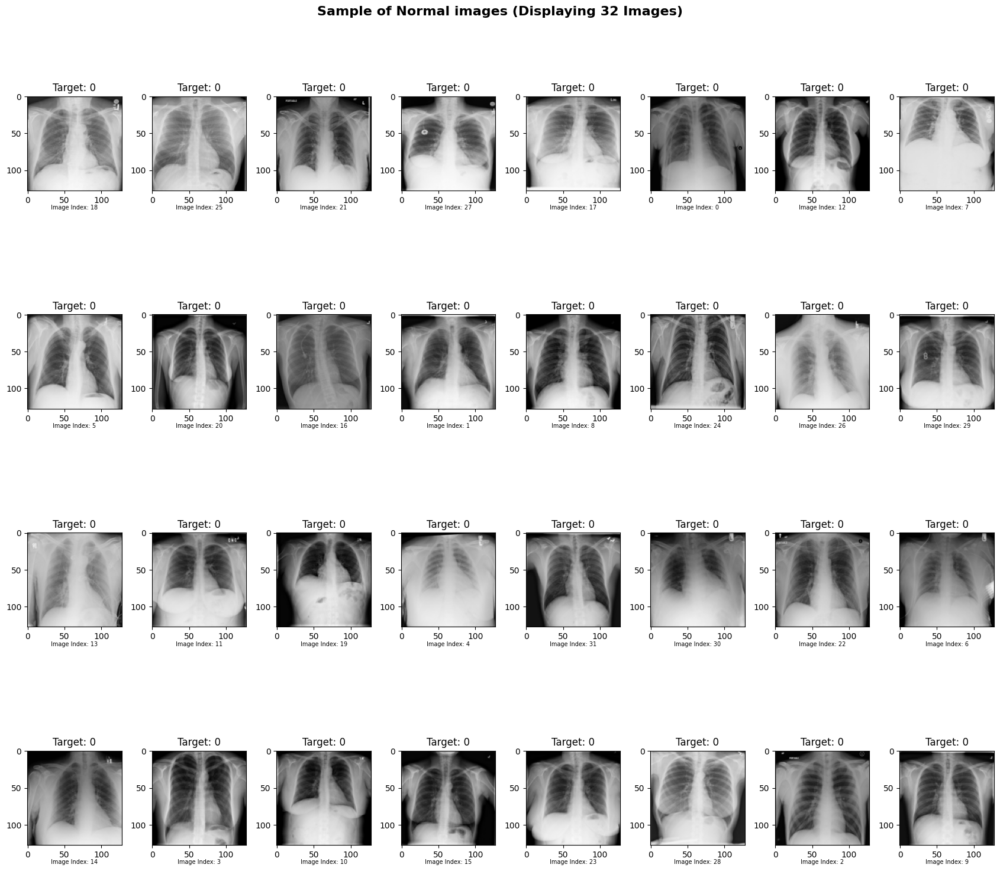

In [22]:
show_image(images=x_norm, 
           target=y_norm,
           title='Sample of Normal images',
           num_display=32, 
           num_cols=8, 
           cmap='gray', 
           random_mode=True)

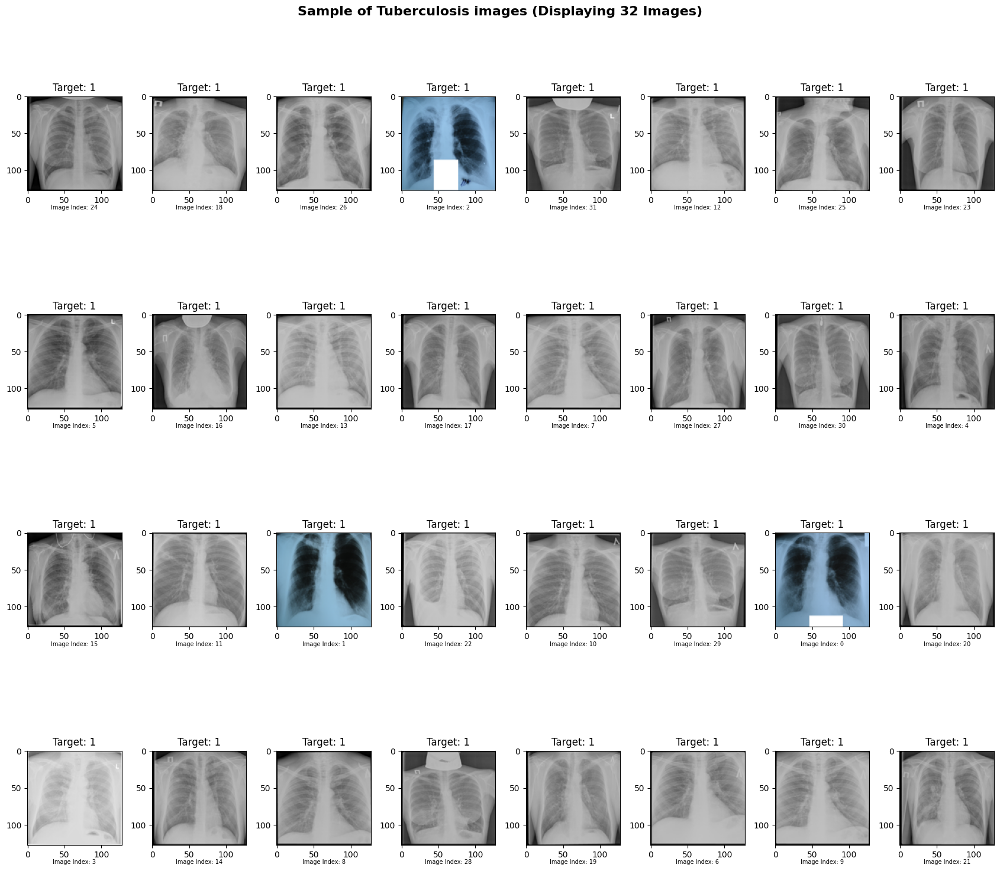

In [23]:
show_image(images=x_tb, 
           target=y_tb,
           title='Sample of Tuberculosis images',
           num_display=32, 
           num_cols=8, 
           cmap='gray', 
           random_mode=True)

### 1.1.4 Image Cropping

**Problem:** Some images in the dataset (Raw data) contain unnecessary blank space, requiring cropping to focus on relevant regions.

**Objective:** Crop images to remove blank space and focus on specific regions of interest, such as lung areas.

- **Pros:**
    - **Improved Focus:** Cropping enhances focus on relevant features
 
- **Cons:**
    - **Risk of Information Loss:** Over-cropping may remove important information

#### 1.1.4.1 Distribution of Intensity Analysis  $X_{Normal}$ VS $X_{Tuberulosis}$
- **Topic**: Gray scale Histogram: Distribution of intensity pixel
- **Mode**: Gray scale 
- **Plot**: Histogram
- <u>**Objective**</u>: aim to compare the distribution of intensity pixels between the datasets of Normal lung X-rays ($X_{Normal}$) and Tuberculosis ($X_{Tuberculosis}$). 

In [24]:
from skimage import img_as_float
from skimage import exposure

In [25]:
def plot_gray_scale_histogram(images, titles, bins=55):
    '''
    Plot Gray Scale Histograms of Images.

    Parameters:
        - images (list): List of grayscale images to plot histograms for.
        - titles (list): List of titles for each histogram.
        - bins (int, optional): Number of bins for the histogram. Default is 100.

    Returns:
        None

    This function generates histograms for a list of grayscale images and displays them side by side. Each histogram is accompanied by its respective title.

    The function does not return any values; it displays the histogram plots directly.
    '''
    # Display results
    fig, axes = plt.subplots(2, len(images), figsize=(17, 8))

    for i, (title, image) in enumerate(zip(titles, images)):
        ax_img, ax_hist, ax_cdf, random_index = img_and_hist(
            image, axes[:, i], bins)

        mean_value = np.mean(image)
        median = np.median(image)
        percentile_95 = np.percentile(image, 95)
        std_value = np.std(image)
        min_value = np.min(image)
        max_value = np.max(image)

        ax_img.set_title('Descriptive statistics of '+r'$\bf{' + f'{title}'+'}$' +
                         f'\nMean: {mean_value: .2f}, Std: {std_value: .2f}, Median: {median: .2f},\nPercentile 95: {percentile_95: .2f}, Min: {min_value: .2f}, Max: {max_value: .2f}', fontsize=16)
        ax_img.text(0.5, -0.15, f'Image Index: {random_index}\n(Display random image)', transform=ax_img.transAxes,
                    fontsize=10, ha='center')

        y_min, y_max = ax_hist.get_ylim()
        ax_hist.set_title(
            'Distribution of pixel intensities of'+r'$\bf{' + f'{title}'+'}$', fontsize=16)
        ax_hist.set_ylabel('Number of pixels')
        ax_hist.set_yticks(np.linspace(0, y_max, 5))

        ax_cdf.set_ylabel('Fraction of total intensity')
        ax_cdf.set_yticks(np.linspace(0, 1, 5))

    plt.suptitle('Gray scale Histogram: Distribution of intensity pixel',
                 fontsize=16, fontweight='bold')
    # Prevent overlap of y-axis labels
    fig.tight_layout()
    plt.show()


def img_and_hist(image_data, axes, bins=100):
    '''
    Plot an image along with its histogram and cumulative histogram.

    Parameters:
        - image_data (ndarray): Grayscale image data as a numpy array.
        - axes (list): List of axes for displaying the image, histogram, and cumulative histogram.
        - bins (int): Number of bins for the histogram.

    Returns:
        - ax_img, ax_hist, ax_cdf: Axes objects for image, histogram, and cumulative histogram.

    This function displays an image along with its histogram and cumulative histogram. It takes the grayscale image data, a list of axes for plotting, and the number of bins for the histogram.

    The function returns the axes objects for the image, histogram, and cumulative histogram.
    '''

    '''
    Plot an image along with its histogram and cumulative histogram.
    '''
    image = img_as_float(image_data)
    ax_img, ax_hist = axes
    ax_cdf = ax_hist.twinx()

    random_index = np.random.randint(0, len(image_data))

    # Display image
    ax_img.imshow(image if image.shape[0] ==1 else image[random_index], cmap=plt.cm.gray)
    ax_img.set_axis_off()

    # Display histogram
    ax_hist.hist(image.ravel(), bins=bins, histtype='step', color='black')
    ax_hist.ticklabel_format(axis='y', style='scientific', scilimits=(0, 0))
    ax_hist.set_xlabel('Pixel intensity')
    # ax_hist.set_xlim(0, 1)
    ax_hist.set_yticks([])

    # Display cumulative distribution
    img_cdf, bins = exposure.cumulative_distribution(image, bins)
    ax_cdf.plot(bins, img_cdf, 'r')
    ax_cdf.set_yticks([])

    return ax_img, ax_hist, ax_cdf, random_index
    

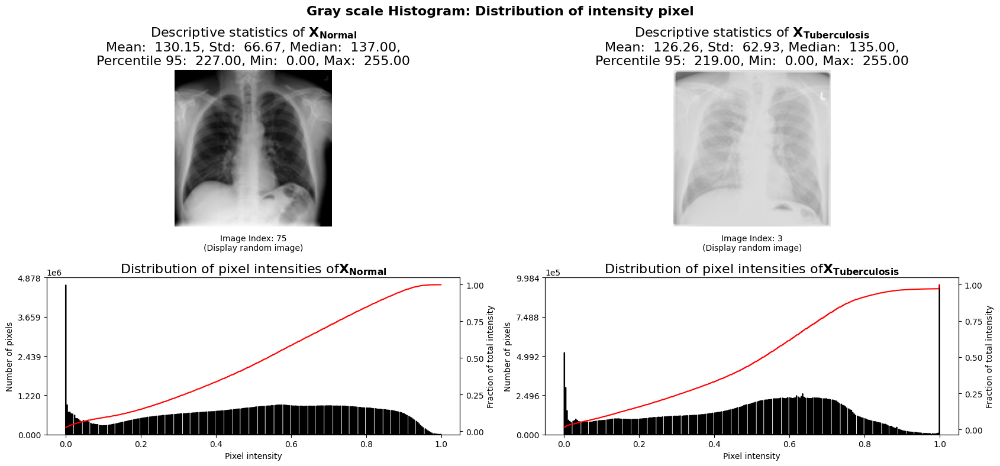

In [26]:
images = [x_norm, x_tb]
subsets = ['X_{Normal}', 'X_{Tuberculosis}']
# For visualization
"""
images: list of numpy.array
subsets: list of string
bins: integer or number that control the shape of distribution for to display
"""
plot_gray_scale_histogram(images=images, titles=subsets, bins=555)

#### 1.1.4.2 Identify Abnormal Image
<u>**Objective**</u>:  identify and filter out images with blank white regions based on their **statistics**.

#### Example of an Abnormal Image
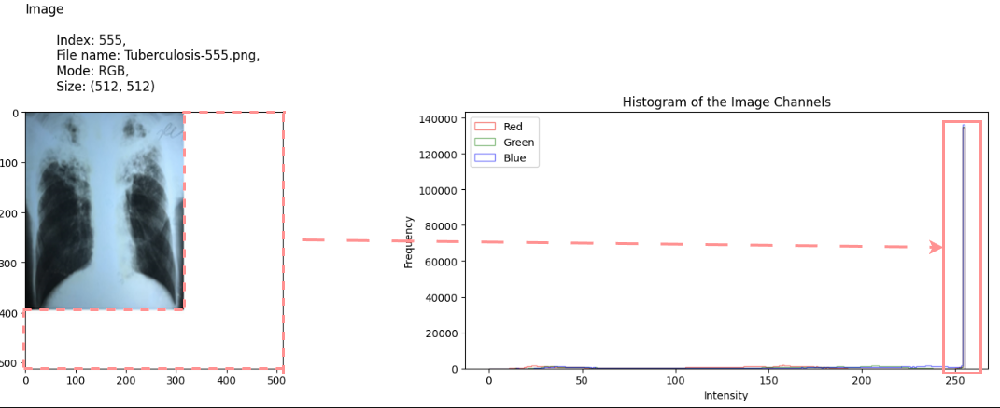

In [27]:
import cv2

In [28]:
def compute_image_statistics(image):
    # Convert image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    
    # Compute image statistics
    mean_intensity = np.mean(gray)
    std_intensity = np.std(gray)
    median_intensity = np.median(gray)
    percentile_95 = np.percentile(gray, 95)
    
    return mean_intensity, std_intensity, median_intensity, percentile_95

def abnormal_image_identifier(images, labels, subset, thresholds):
    filtered_normal_images = []
    filtered_abnormal_images = []
    filtered_normal_labels = []
    filtered_abnormal_labels = []
    
    for image, label in zip(images, labels):
        # Compute image statistics
        mean_intensity, std_intensity, median_intensity, percentile_95 = compute_image_statistics(image)
        
        # Check if image meets filtering criteria
        if (mean_intensity > thresholds['mean_threshold'] and
            std_intensity > thresholds['std_threshold'] and
            median_intensity > thresholds['median_threshold'] and
            percentile_95 > thresholds['percentile_threshold']):
            # Image is abnormal
            filtered_abnormal_images.append(image)
            filtered_abnormal_labels.append(label)
        else:
            # Image is normal
            filtered_normal_images.append(image)
            filtered_normal_labels.append(label)
            
    summary = f"""{prefix_bold}Detected Abnormal Images{suffix_bold}
    Subset: {subset}
    Amount: {len(filtered_abnormal_images)} images
    """
    
    print(summary)
    
    return np.array(filtered_normal_images), np.array(filtered_abnormal_images), filtered_normal_labels, filtered_abnormal_labels


#### Tuberculosis
Variables:
- **constant**: for decrease the descriptive statistic values, for more remain unidentified abnormal images
- **thresholds**: based on "Gray scale Histogram: Distribution of intensity pixel" on section [1.1.4.1](####1-1-4-1-distribution-of-intensity-analysis)

In [29]:
constant = 5
tb_thresholds = {
    'mean_threshold': 126-constant,  
    'std_threshold': 62-constant,   
    'median_threshold': 135-constant, 
    'percentile_threshold': 219-constant 
}

# Filter images based on thresholds
norm_tb_images, abnorm_tb_images,norm_tb_labels, abnorm_tb_labels  = abnormal_image_identifier(x_tb, y_tb, subset='Tuberculosis', thresholds=tb_thresholds)

Detected Abnormal Images
    Subset: Tuberculosis
    Amount: 67 images
    


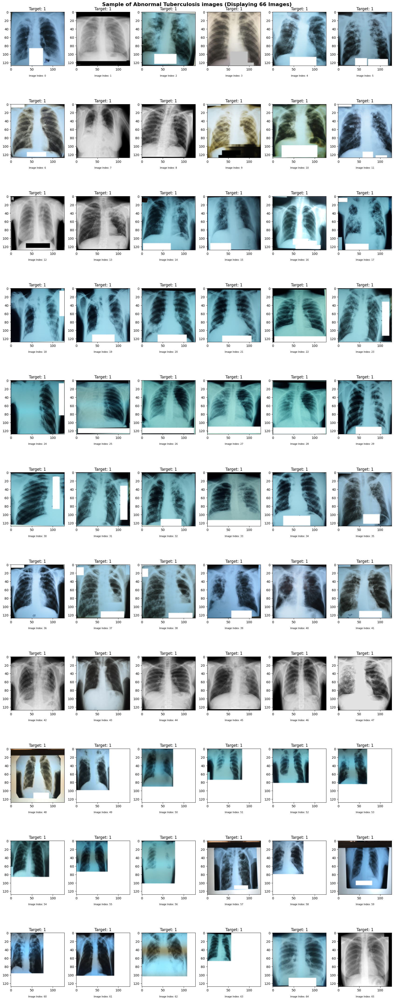

In [30]:
show_image(images=abnorm_tb_images, 
           target=abnorm_tb_labels,
           title='Sample of Abnormal Tuberculosis images',
           num_display=66, 
           num_cols=6, 
           cmap='gray', 
           random_mode=False)


**Explanation**: 
This plot represented "Tuberculosis" group, Some images contain unnecessary `White` blank space that appeared like reflected "L" letter, "Bottom" of image,And requiring cropping to focus on relevant regions.

**Problem including**: 
- `White` blank space image
- `Black` blank space image

**Solution**: 
- **Image cropping**: cropping to focus on lung regions
- **Remove**: Remove training examples

#### Normal
Variables:
- **constant**: for decrease the descriptive statistic values, for more remain unidentified abnormal images
- **thresholds**: based on "Gray scale Histogram: Distribution of intensity pixel" on section [1.1.4.1](####1-1-4-1-distribution-of-intensity-analysis)

In [31]:
constant = 5

norm_thresholds = {
    'mean_threshold': 130 + constant,  
    'std_threshold': 66 + constant,   
    'median_threshold': 137 +constant, 
    'percentile_threshold': 227 +constant
}

# Filter images based on thresholds
norm_norm_images, abnorm_norm_images,norm_norm_labels, abnorm_norm_labels  = abnormal_image_identifier(x_norm, y_norm, subset='Normal', thresholds=norm_thresholds)

Detected Abnormal Images
    Subset: Normal
    Amount: 77 images
    


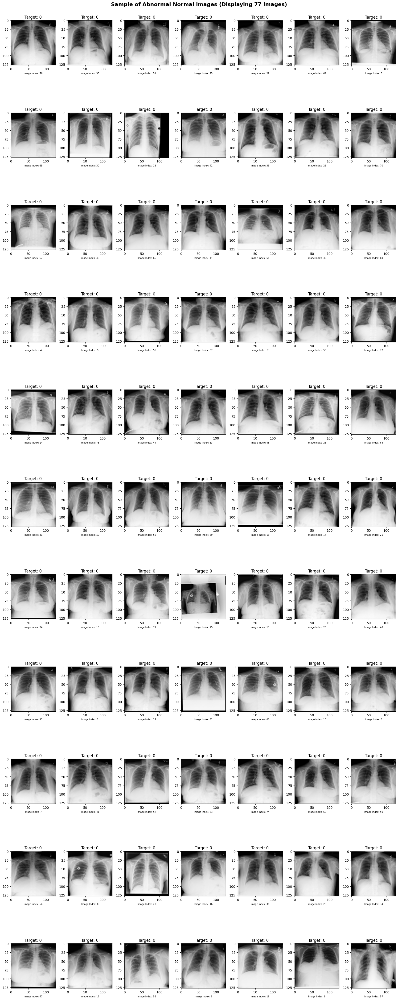

In [32]:
show_image(images=abnorm_norm_images, 
           target=abnorm_norm_labels,
           title='Sample of Abnormal Normal images',
           num_display=77, 
           num_cols=7, 
           cmap='gray', 
           random_mode=True)

**Explanation**:
- `White` blank space image
- `Black` blank space image

This plot represented "Normal" group, Some images contain unnecessary `White` blank space around the edge of image, requiring cropping to focus on relevant regions.

#### 1.1.4.3 Remove Background
<u>**Objective**</u>: to remove the blank white space in the background of lung images using `OpenCV (cv2)`. Before we proceed with the removal process, we need to construct a function to <u>calculate</u> the `threshold` using the `Interquartile Range (IQR)` method for the following purposes:

- **Fill suitable Threshold of  `cv2.threshold`**: Because we aim to remove the blank white space in the images, it's essential to choose an appropriate threshold value for the `cv2.threshold` function. However, the intensity of the blank space varies among images, with some spaces closely resembling white but not entirely white (Intensity=255) and others being completely white. Therefore, we need to calculate statistical values to determine a suitable threshold.

- **Perform Removal and Cropping**: Once we have determined the threshold, we can use `cv2.threshold` to identify the blank space in the images and select the inverted regions, which represent the lung regions. Then, we crop these regions to create images of the same size (128x128) as the others in the dataset.

###### 1.1.4.3.1 Type of Threshold
<u>**Objective**</u>: choose the appropriate type of threshold for image segmentation based on the problem requirements, In this case, the threshold type selected is `cv2.THRESH_BINARY_INV` or `Threshold Binary, Inverted`, Because When I used `cv2.THRESH_BINARY` to remove to blank background on the image and it covered the lung region instead of the blank background, then I inversed (`cv2.THRESH_BINARY_INV`) it and it work. You will see an example of it later.

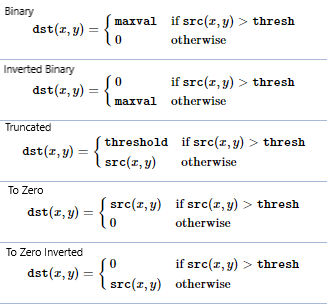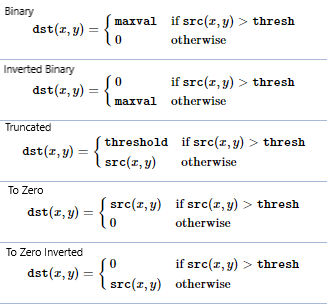

Source 1: [python-thresholding-techniques-using-opencv](https://www.geeksforgeeks.org/python-thresholding-techniques-using-opencv-set-1-simple-thresholding/)

Source 2: [docs-opencv-tutorial_threshold](https://docs.opencv.org/4.x/db/d8e/tutorial_threshold.html)


###### 1.1.4.3.2 Remove Blank Background
<u>**Objective**</u>: To remove the blank white space in lung images, This involves several steps:
1. `convert to grayscale`: converted to grayscale using the cv2.cvtColor function. 
2. `calculate threshold`: Before applying thresholding, a suitable threshold value needs to be determined. which helps choose a threshold value based on the image's intensity distribution.
3. `cv2.threshold`: where pixel intensities above the threshold are set to white and those below are set to black.
4. `cv2.findContours`: After thresholding, contours are detected in the binary image, This method represent the boundaries of objects in the image.
5. `cv2.rectangle`:  Once contours are detected, a bounding rectangle is drawn around, helps visualize the regions that will be cropped.
6. `crop the subject with padding`: the lung region is cropped from the original image using the bounding box coordinates. Padding may be added to ensure that the entire lung region is included in the cropped image.
7. `cv2.resize`: ensure consistency with other images in the dataset.

In [33]:
def cv2_gray_converter(image):
    if len(image.shape) == 3:  # RGB image
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    else:  # Grayscale image
        gray = image
    return gray

In [34]:
def RBS(image,
        new_size=(128, 128), 
        init_intensity=240, 
        final_intensity=255):
    """
    RBS (Remove Blank Space):
        RBS Function: It will detect an image whether White/Black depends on range of Intensity range, Incase you want to remove:
            - White, Intensity should be 240 - 255 (Almost White) of Intensity will be selected, and remove it
            - Black,  Intensity should be 0 - 10 (Almost Black) of Intensity will be selected, and remove it
            PS, I used the 95% Percentile value of Tuberculosis group to remove the White Blank Space in their group, And padding parameter created just incase to preserve the edge of an image
    """
    # 1. Condition: To convert the image to grayscale
    gray = cv2_gray_converter(image)
    """
    How cv2.threshold works:
        ret, thresh = cv2.threshold(image, start_intensity_value, end_intensity_value, type_of_thresholding)
        Parameters:
            - image: The input grayscale image.
            - start_intensity_value: The lower threshold intensity value.
            - end_intensity_value: The upper threshold intensity value.
            - type_of_thresholding: The type of thresholding to be applied.
    Example:
        ret, thresh = cv2.threshold(image, 240, 255, cv2.THRESH_BINARY)
        Explanation: This will create a binary threshold image where pixel intensities higher than 240 are set to 255 (white).
    """
    # 2. calculate threshold
    info = f"Intensity Range: {init_intensity} to {final_intensity}"
    # 3. thresholding: 
    ret, thresh = cv2.threshold(gray, init_intensity, final_intensity, cv2.THRESH_BINARY_INV)
    
    """
    Code - Types of Thresholding:
        ret, thresh1 = cv2.threshold(img, 120, 255, cv2.THRESH_BINARY) 
        ret, thresh2 = cv2.threshold(img, 120, 255, cv2.THRESH_BINARY_INV) 
        ret, thresh3 = cv2.threshold(img, 120, 255, cv2.THRESH_TRUNC) 
        ret, thresh4 = cv2.threshold(img, 120, 255, cv2.THRESH_TOZERO) 
        ret, thresh5 = cv2.threshold(img, 120, 255, cv2.THRESH_TOZERO_INV) 
    """

    """
    Contour Approximation Method: 
        - Used to find contours in a binary image (2 colors image). 
        - Find contours, represent the boundaries of objects in an image with the same intensity or color.
    """
    contours, hierarchy = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
     
    # Find the contour with the largest area
    contour = max(contours, key=cv2.contourArea)

    # Find the bounding box of the contour
    x, y, w, h = cv2.boundingRect(contour)

    # Crop the original image using the bounding box
    cropped_image = image[y:y+h, x:x+w]
    cropped_image = cv2.resize(cropped_image, new_size)
    
    return cropped_image, thresh, info


In [35]:
def DCS(image, 
        padding=0, 
        init_intensity=10, 
        final_intensity=255,
        new_size=(128, 128)):
    
    """
    DCS (Detect and Crop Subject):
        DCS Function: It will detect an image input in gray where 10 - 255 of Intensity will be selected
    """
    # Convert the image to grayscale
    gray = cv2_gray_converter(image)
    
    # Apply thresholding to segment the subject (you can use more sophisticated segmentation techniques here)
    ret, thresh = cv2.threshold(gray, init_intensity, final_intensity, cv2.THRESH_BINARY)
    
    # Find contours
    contours, hierarchy = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # Find the contour with the largest area
    contour = max(contours, key=cv2.contourArea)
    
    # Find the bounding box of the contour
    x, y, w, h = cv2.boundingRect(contour)
    
    # Draw a rectangle around the detected contour
    cv2.rectangle(image, (x, y), (x + w, y + h), (255, 0, 0), 2)  # Bounding box with Red color
    
    # Crop the subject with padding
    cropped_image = image[max(y - padding if (y - padding) > 0 else 0, 0):min((y + h + padding) if (y + h + padding) > 0 else 0, image.shape[0]),
                         max(x - padding if (x - padding) > 0 else 0, 0):min(x + w + padding if (x + w + padding) else 0, image.shape[1])]
    cropped_image = cv2.resize(cropped_image, new_size)
    
    return cropped_image

In [36]:
def display_after_remove(images, 
                         targets, 
                         subset, 
                         dcs_init_intensity,
                         dcs_final_intensity,
                         rbs_init_intensity,
                         rbs_final_intensity,
                         padding, 
                         
                         new_size=(128, 128), 
                         num_display=5, 
                         title='Image cropping', 
                         random_mode=False):
    cropped_images = []
    
    if random_mode:
        display_indices = np.random.choice(len(images), num_display, replace=False)
    else:
        display_indices = range(min(num_display, len(images)))
    # Image Processing and Achieve cropped images and targets or labels
    
    """
    Intensity Variables Declaration
    """
    # Black Intensity Range
    init_black_intensity = 10
    final_black_intensity = 255
    # White Intensity Range
    init_white_intensity = 214
    final_white_intensity = 255
    
    for image in images:
        
        # Detect and Crop Subject
        detected_image = DCS(image, 
                             padding=padding,
                             init_intensity=init_black_intensity, 
                             final_intensity=final_black_intensity,
                             new_size=new_size)
        
        # Remove white
        cropped_image, thresh, info = RBS(detected_image,
                                                         new_size=new_size, 
                                                         init_intensity=init_white_intensity, 
                                                         final_intensity=final_white_intensity, 
                                                         )
        cropped_images.append(cropped_image)
        
    # Image Visualization: helps visualize the regions that will be cropped.
    for idx in display_indices:
        uncropped_image = images[idx]
        label = targets[idx]
        
        
        # Detect and Crop Subject
        detected_image = DCS(uncropped_image, 
                             padding=padding,
                             init_intensity=init_black_intensity, 
                             final_intensity=final_black_intensity,
                             new_size=new_size)
        
        # Remove white
        cropped_image, thresh, info = RBS(detected_image,
                                                         new_size=new_size, 
                                                         init_intensity=init_white_intensity, 
                                                         final_intensity=final_white_intensity, 
                                                         )
        prefix_bold = r'$\bf{'
        suffix_bold = '}$'
        
        uncropped_title = f"""
            Mode: {Image.fromarray(uncropped_image).mode},
            Size: {Image.fromarray(uncropped_image).size}
            """
        cropped_title = f"""
            Mode: {Image.fromarray(cropped_image).mode},
            Size: {Image.fromarray(cropped_image).size}
            """
        plt.figure(figsize=(12, 6))
        plt.rcParams['axes.titlesize'] = 7

        plt.subplot(1, 4, 1)
        plt.imshow(uncropped_image)
        plt.title(f'{prefix_bold}Input{suffix_bold}: Original Image' + '\n' + uncropped_title, loc='left')

        plt.subplot(1, 4, 2)
        plt.imshow(detected_image)
        plt.title(f'{prefix_bold}Subject-Detection{suffix_bold}\nDetected Subject on Image: \nThreshold + Contours,\nCropping + ({padding}) Padding ')

        plt.subplot(1, 4, 3)
        plt.imshow(thresh, cmap='RdYlGn')
        plt.title(f"{prefix_bold}Threshold-Image{suffix_bold}\n{info}", fontsize=7)

        plt.subplot(1, 4, 4)
        plt.imshow(cropped_image)
        plt.title(f'{prefix_bold}Output{suffix_bold}: Cropped Image' + '\n' + cropped_title, loc='left')

        plt.suptitle(title + f"\n{prefix_bold}Subset{suffix_bold}: {subset}", font='bold')
        plt.show()
        
    return np.array(cropped_images), targets

In [37]:
tb_thresholds

{'mean_threshold': 121,
 'std_threshold': 57,
 'median_threshold': 130,
 'percentile_threshold': 214}

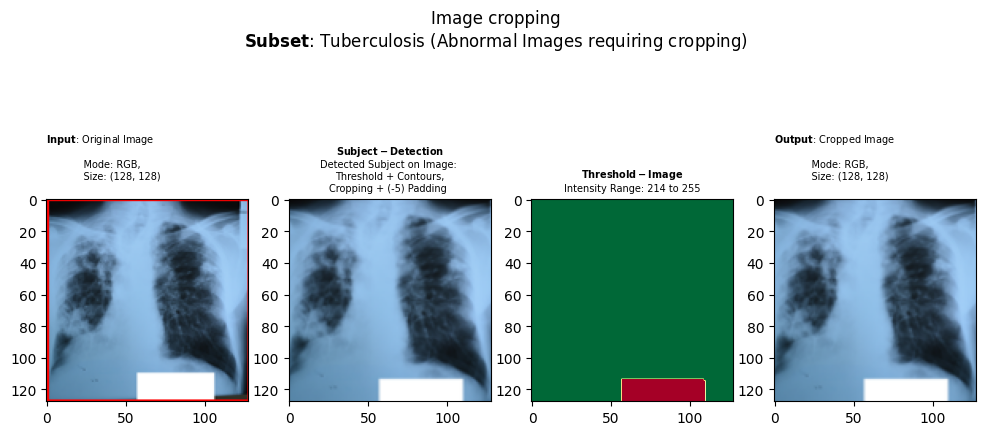

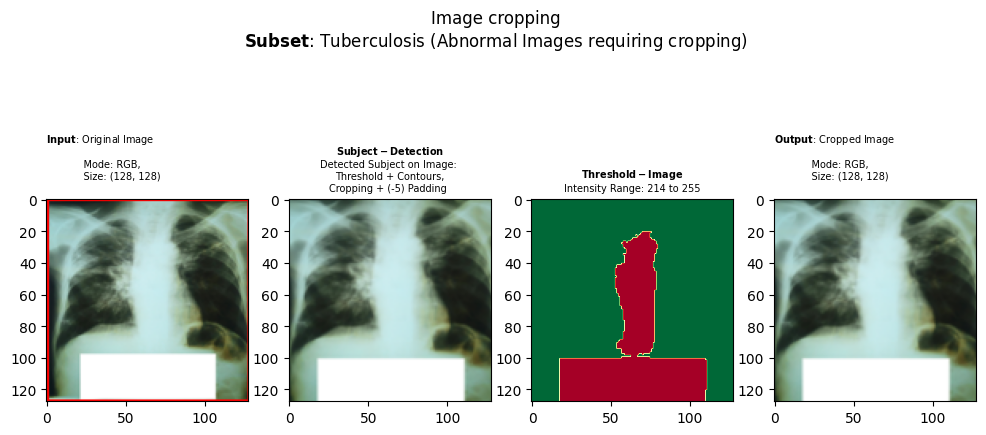

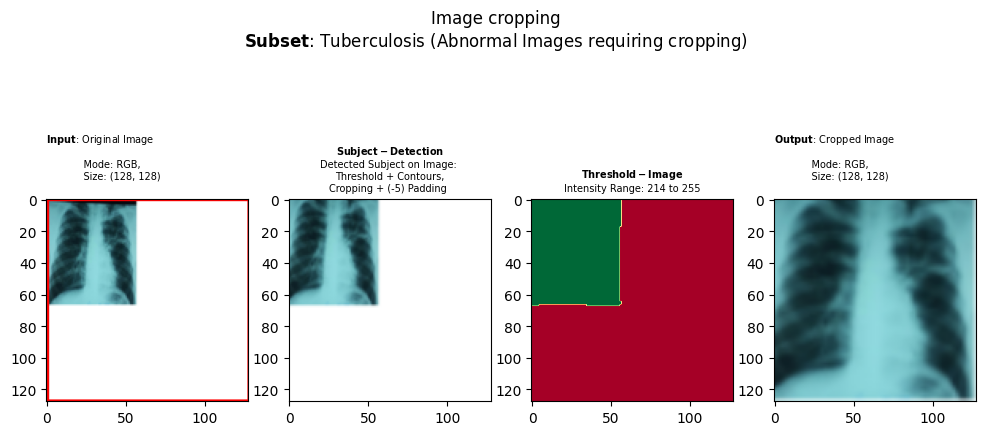

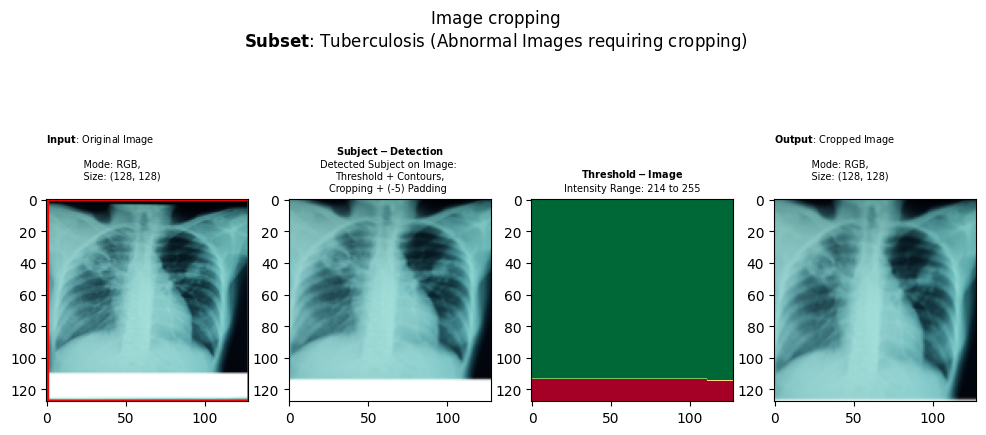

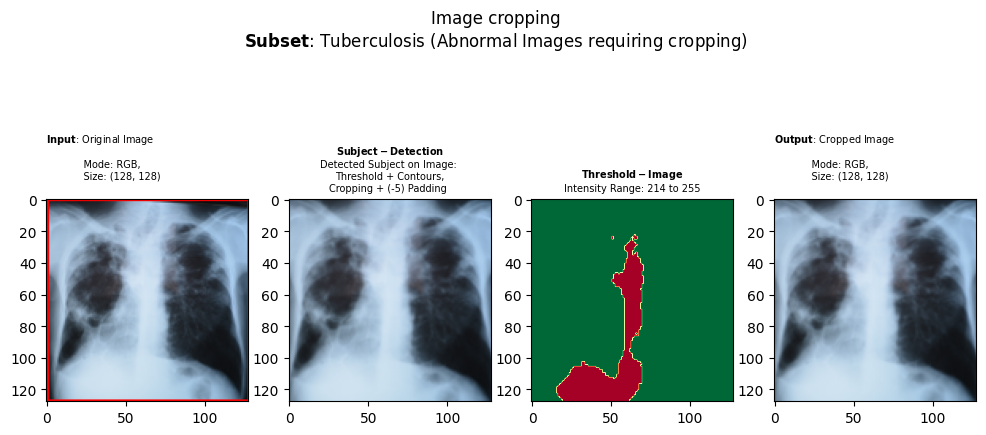

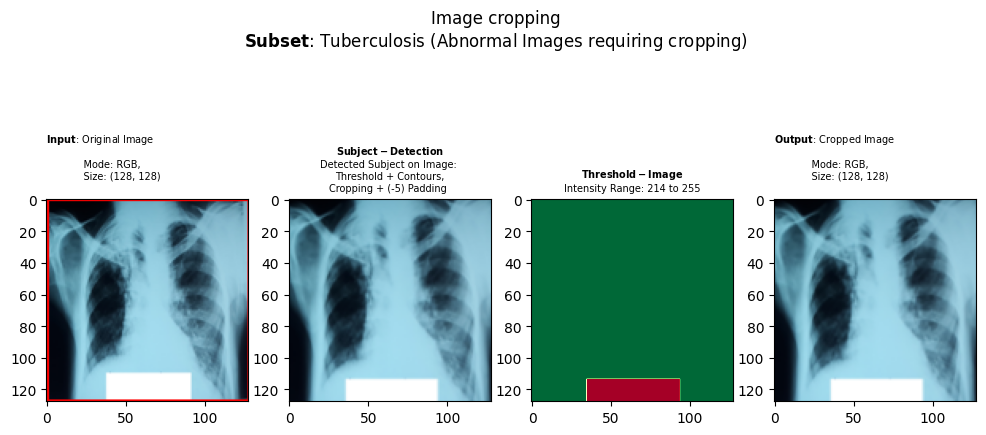

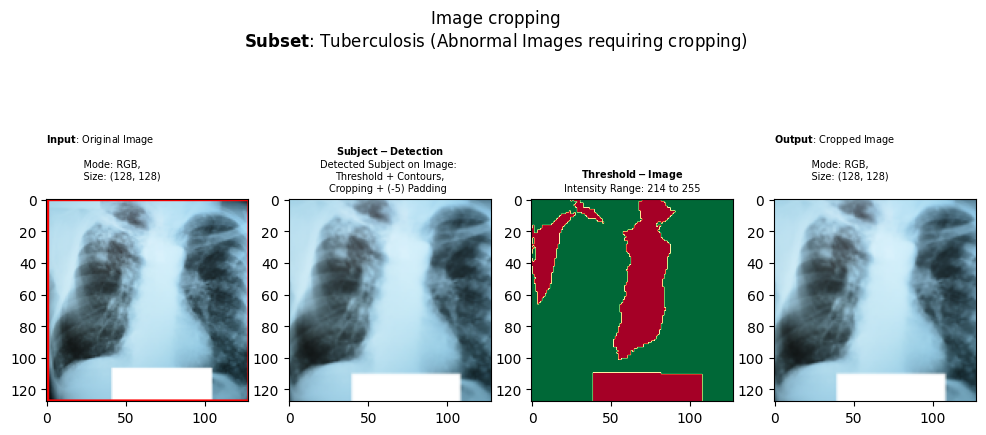

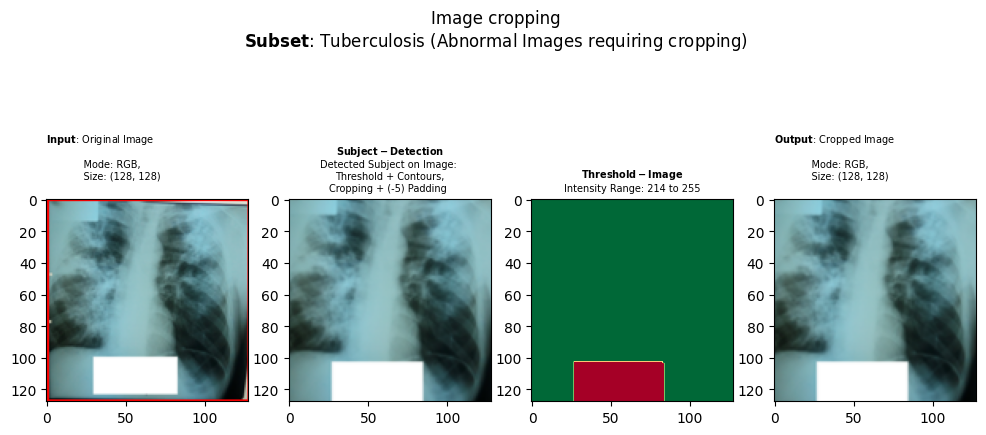

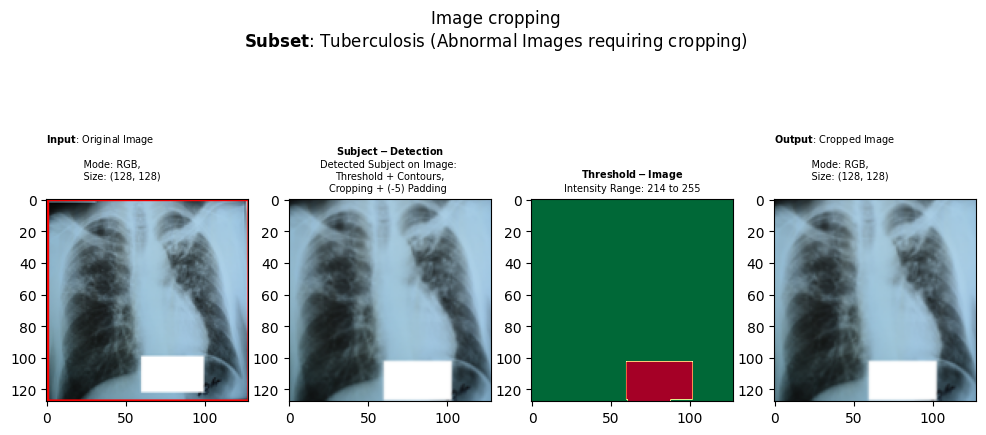

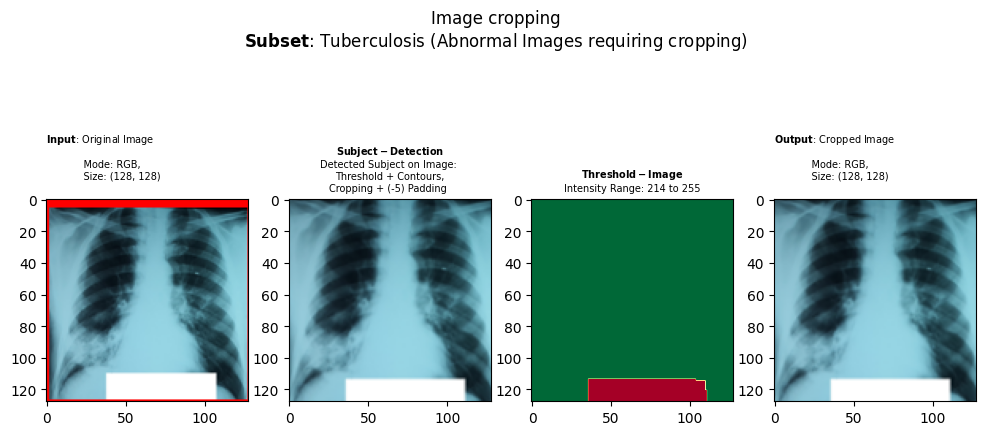

In [38]:
tb_cropped_images, tb_cropped_labels = display_after_remove(images=abnorm_tb_images, 
                                              targets=abnorm_tb_labels, 
                                              subset="Tuberculosis (Abnormal Images requiring cropping)",
                                              dcs_init_intensity=10,
                                              dcs_final_intensity=255,
                                              rbs_init_intensity=tb_thresholds['percentile_threshold'],
                                              rbs_final_intensity=255,
                                              padding=-5,
                                              new_size=(128, 128), 
                                              num_display=10, 
                                              title='Image cropping', 
                                              random_mode=True)

In [39]:
tb_cropped_images.shape

(67, 128, 128, 3)

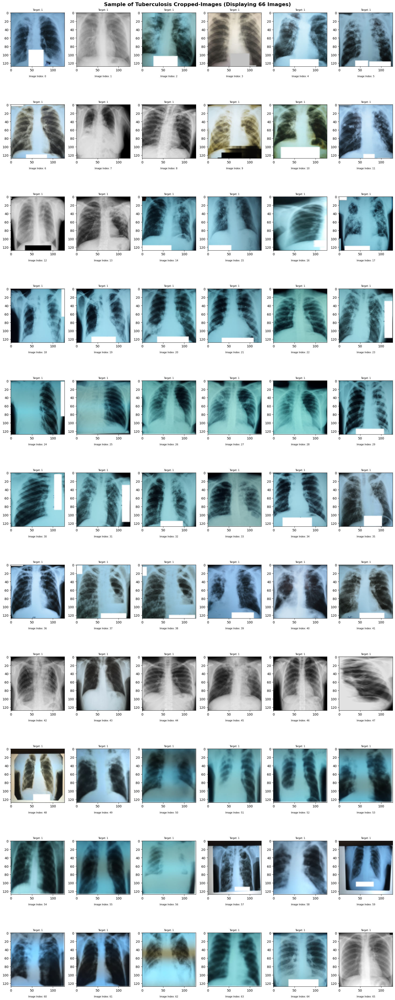

In [40]:
show_image(images=tb_cropped_images, 
           target=tb_cropped_labels,
           title='Sample of Tuberculosis Cropped-Images',
           num_display=66, 
           num_cols=6, 
           cmap='gray', 
           random_mode=False)

### 1.1.5 Data Preparation

**Objective:** prepare data to facilitate further Data Augmentation processing. We will create explicit variables that are easy to call and work with.

- **X**; representing 7,000 samples, each with a size of 128x128 pixels. contains
    - **Normal images**
        - `x_norm`: representing 3,500 images
    - **Tuberculosis images**
        - `x_tb`: representing 700 images
            - Normal images:
                - `norm_tb_images`: representing 633 images
            - Abnormal images:
                - `abnorm_tb_images`: representing 67 images
                
- **y**; represents the binary classification labels, where 0 represents a normal image, 1 represents a TB image. 
    - **Normal labels:**
        - `y_norm`: representing 3,500 labels
    - **Tuberculosis labels:**
        - `y_tb`: representing 700 labels
            - Normal labels:
                - `norm_tb_labels`: representing 633 labels
            - Abnormal labels:
                - `abnorm_tb_labels`: representing 67 labels

$$X_{Tuberculosis}(700) = X_{Filtered-Tuberculosis-Normal}(633) +X_{Tuberculosis-Abnormal-Cropped}(67)$$

In [41]:
# Concatenate 
X_tb = np.concatenate((norm_tb_images, tb_cropped_images), axis=0)

# Concatenate 
y_tb = np.concatenate((norm_tb_labels, tb_cropped_labels), axis=0)

In [42]:
X_tb.shape

(700, 128, 128, 3)

In [43]:
y_tb.shape

(700,)

## 1.2 Data Augmentation (Class imbalance problem - Oversamping) (Optional):
Perform data augmentation techniques such as rotation, scaling, flipping, and adding noise to increase the diversity and size of your training dataset. This helps in improving the model's generalization ability.
### Objective
- solve class imbalance problem (700 TB images and 3500 normal images)

### Not Recommended:

1. **Reflection:**
    - Reflection in x-axis is discouraged due to potential confusion (e.g., 6 vs. 9).
    - Reflection in y-axis results in non-physiologic images, not recommended.
    - No method simulates differences between Posterior-Anterior (PA) and Anteroposterior (AP) chest X-rays.
2. **Severe Rotation:**
    - Avoid severe rotations (−90 to 90) as they may introduce unrealistic noise.
    - Slight rotations (−5 to 5) seen in practice can be helpful.
3. **Scaling:**
    - Large scaling (>×1) stretches the image, while small scaling (<×1) reduces its size.
    - Equal scaling in both axes is possible; scaling in only one axis is not recommended clinically.
4. **Shearing:**
    - Shearing is not recommended, producing clinically non-existent images.

### Could Be Helpful/Acceptable:

1. **Translation (Shifting):**
    - Shifting X-ray images can be useful to center lungs, enhancing detector robustness.
    - No clearly recommended translation range; considered acceptable clinically.

### Summary of Clinical Perspective
| Augmentation Technique | Recommendation | Explanation |
| --- | --- | --- |
| Reflection (x-axis) | Not Recommended | Adds unnecessary noise and misleads the learning algorithm. |
| Reflection (y-axis) | Not Recommended | Leads to non-physiologic images and confounds learning. |
| Rotation | Could be helpful (within -5 to 5 degrees) | Slight rotations seen in clinical practice, but severe rotations are not recommended. |
| Scaling | Not Recommended | Large scaling stretches the image, small scaling reduces size. Equal scaling is possible, but x-axis or y-axis scaling is not recommended clinically. |
| Shearing | Not Recommended | Produces images that do not exist clinically. |
| Translation | Could be helpful/acceptable | Shifting X-ray images can be useful for better lung positioning, but no recommended range. |
Read more: https://www.frontiersin.org/articles/10.3389/fmed.2021.629134/full

In [44]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import random
import time

In [45]:
def x_ray_image_augmentation(images, targets, sample_count):
    '''
    :Parameters
        images (ndarray (n,)): Input data as a numpy array.
        target (ndarray (n,)): Target data or Label data as a numpy array.
        sample_count (integer64): Number of data needed.
    '''
    start_time = time.time() 
    # Randomize the data augmentation parameters
    rotation_range = random.randint(-5, 5)
    # width_shift_range = random.uniform(0.0, 0.05)      Not reccomend
    # height_shift_range = random.uniform(0.0, 0.05)     Not reccomend
    # shear_range = random.uniform(0.0, 0.1)             Not reccomend
    zoom_range = random.uniform(0.0, 0.1)
    fill_mode = random.choice(['nearest',
                               'constant',
                               #    'reflect',               Not reccomend
                               'wrap'])

    # Create the ImageDataGenerator with randomized parameters
    datagen = ImageDataGenerator(
        rotation_range=rotation_range,
        # width_shift_range=width_shift_range,             Not reccomend
        # height_shift_range=height_shift_range,           Not reccomend
        # shear_range=shear_range,                         Not reccomend
        zoom_range=zoom_range,
        fill_mode=fill_mode
    )
    # Load and augment the data

    augmented_data_generator = datagen.flow(images, targets, batch_size=1)
    batch_images, batch_labels = augmented_data_generator.next()
    for _ in tqdm(range(sample_count-images.shape[0]), desc='augmenting...'):
        batch_images, batch_labels = augmented_data_generator.next()
        try:
            combined_images = np.concatenate(
                (combined_images, batch_images), axis=0)
            combined_labels = np.concatenate(
                (combined_labels, batch_labels), axis=0)
        except NameError:
            combined_images = np.concatenate((images, batch_images), axis=0)
            combined_labels = np.concatenate((targets, batch_labels), axis=0)
            
    end_time = time.time()  # Record the end time
    execution_time_seconds = end_time - start_time  # Calculate the execution time
    execution_time_minutes = execution_time_seconds / 60
    
    '''
    Returns:
        combined_images (ndarray (n,)) : generated images
        combined_labels (ndarray (n,)) : generated labels
    '''
    
    summary = f""" Summary
    Execution time: {execution_time_minutes}, minutes,
    Before Augmentation: {images.shape[0]} images,
    After Augmentation: {combined_images.shape[0]} images,
    Total: +{combined_images.shape[0]-images.shape[0]} images
    """
    print(summary)
    return combined_images, combined_labels


## 1.3 Normalizing the pixel values

In [46]:
# Scaled the subset of dataset before do Augmentation 
X_tb = X_tb/255

# So do the others
x_norm = x_norm/255

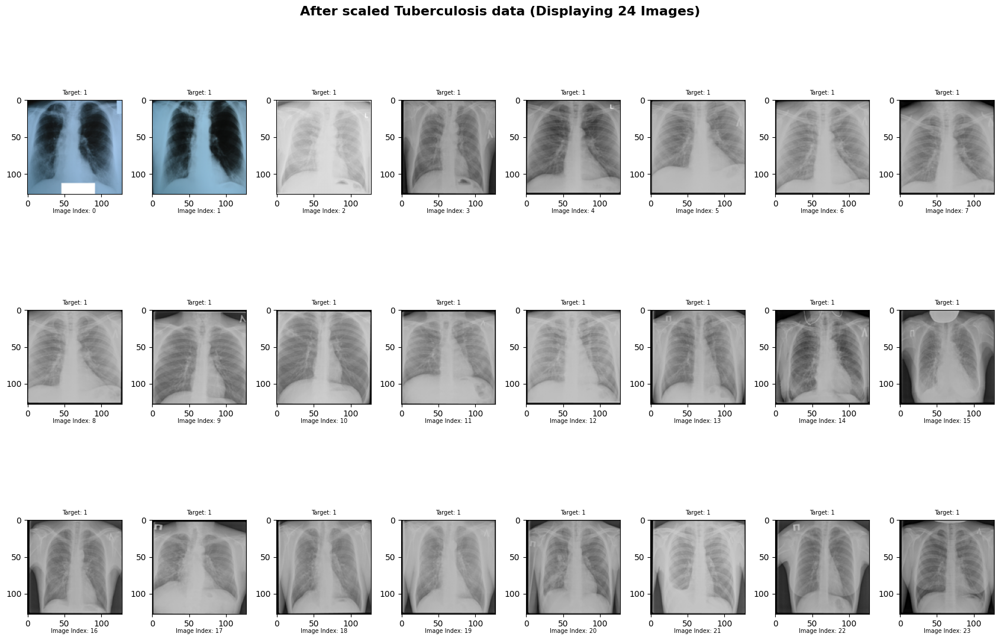

In [47]:
show_image(images=X_tb,
           target=y_tb,
           title='After scaled Tuberculosis data', 
           num_display=24, 
           num_cols=8, 
           cmap='gray', 
           random_mode=False)

In [48]:
X_tb_augmented, y_tb_augmented = x_ray_image_augmentation(images=X_tb, 
                                                         targets=y_tb, 
                                                         sample_count=3500)

augmenting...: 100%|██████████| 2800/2800 [15:16<00:00,  3.05it/s]

 Summary
    Execution time: 15.281512641906739, minutes,
    Before Augmentation: 700 images,
    After Augmentation: 3500 images,
    Total: +2800 images
    


In [49]:
X_tb_augmented.shape

(3500, 128, 128, 3)

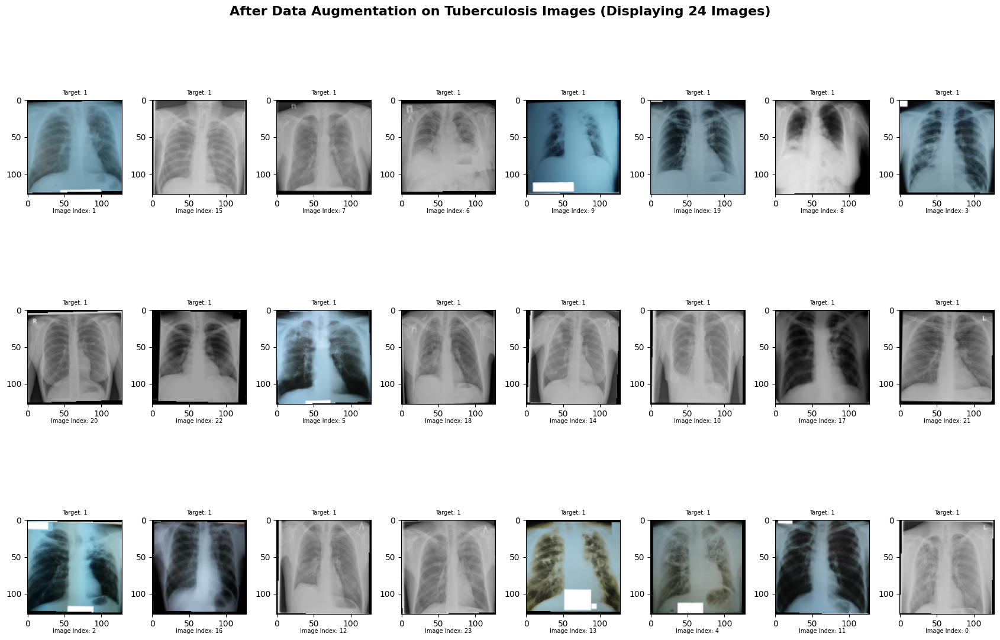

In [50]:
# New image indexes, started at 700-3500
start_index = 700
end_index = 3500

show_image(images=X_tb_augmented[start_index:end_index],
           target=y_tb_augmented[start_index:end_index],
           title='After Data Augmentation on Tuberculosis Images', 
           num_display=24, 
           num_cols=8, 
           cmap='gray', 
           random_mode=True)

### Compare Distribution (Tuberculosis Original Dataset vs Tuberculosis + Augmentation)

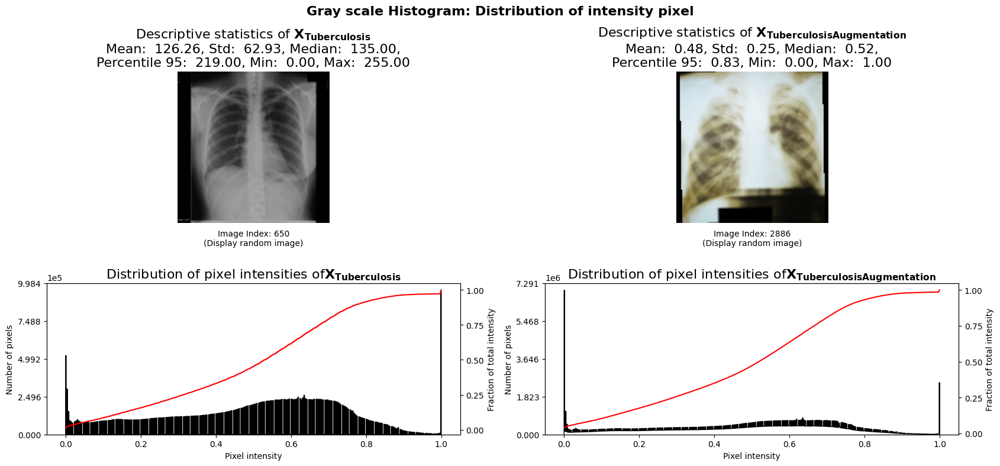

In [51]:
images_2 = [x_tb, X_tb_augmented]
subsets_2 = ['X_{Tuberculosis}', 'X_{TuberculosisAugmentation}']
# For visualization
plot_gray_scale_histogram(images=images_2, titles=subsets_2, bins=555)

**Explanation**:

Both distributions are similar, as indicated by the red lines and statistical descriptors.

## 1.4 Data Preparation
prepare data to facilitate further processing and training. We will create explicit variables that are easy to call and work with.

### 1.4.1 Original (Class Imbalanced)
- **$X_{Imbalanced}$**; representing 4,200 samples, each with a size of 128x128 pixels. contains
    - `x_norm` variable: 3500 samples will be the `Normal` images 
    - `X_tb` variable: 700 samples will be the `Tuberculosis` images 

- **$y_{Imbalanced}$**; represents the binary classification labels, where 
    - `y_norm` variable: 3500 samples - 0 represents a ``Normal`` images
    - `y_tb` variable: 700 samples - 1 represents a `Tuberculosis` images. 

In [52]:
# Concatenate x_norm and x_tb along the first axis (samples)
X_imbalanced = np.concatenate((x_norm, X_tb), axis=0)

# Concatenate y_norm and target_tb
y_imbalanced = np.concatenate((y_norm,  y_tb), axis=0)

In [53]:
X_imbalanced.shape

(4200, 128, 128, 3)

In [54]:
y_imbalanced.shape

(4200,)

In [55]:
np.bincount(y_imbalanced)

array([3500,  700])

### 1.4.2 Over-sampling (Class Balanced)
- **$X_{Balanced}$**; representing 7,000 samples, each with a size of 128x128 pixels. contains
    - `x_norm` variable: 3500 samples will be the `Normal` images 
    - `X_tb_augmented` variable: 3500 samples will be the `Tuberculosis Augmented` images 

- **$y_{Balanced}$**; represents the binary classification labels, where 
    - `y_norm` variable: 3500 samples - 0 represents a ``Normal`` labels
    - `y_tb_augmented` variable: 3500 samples - 1 represents a `Tuberculosis Augmented` labels.

In [56]:
X_over_sampling = np.concatenate((x_norm, X_tb_augmented), axis=0)
y_over_sampling = np.concatenate((y_norm,  y_tb_augmented), axis=0)

In [57]:
X_over_sampling.shape

(7000, 128, 128, 3)

In [58]:
y_over_sampling.shape

(7000,)

In [59]:
np.bincount(y_over_sampling)

array([3500, 3500])

### 1.4.3 Under-sampling (Class Balanced)
- **$X_{norm_undersampled}$**; representing 1,400 samples, each with a size of 128x128 pixels. contains
    - `x_norm_undersampled` variable: 700 samples will be the `Normal` images 
    - `X_tb` variable: 700 samples will be the `Tuberculosis` images 

- **$y_{Balanced}$**; represents the binary classification labels, where 
    - `y_norm_undersampled` variable: 700 samples - 0 represents a ``Normal`` labels
    - `y_tb` variable: 700 samples - 1 represents a `Tuberculosis` labels.

#### Undersampling function
**Objective**: 
- Undersample the majority class (3,500 training examples) to match the size of the minority class (700 training examples), resulting in a balanced dataset with a ratio of 700:700 for the two classes.
- It randomly selects a subset of samples from the majority class to match the size of the minority class using the `np.random.choice` function. Sampling is done without replacement to ensure each sample is selected only once.

In [60]:
def Undersampling(x_majority, y_majority, x_minority, y_minority, replacement=False):
    # Determine the size of the minority class
    num_samples_minority = len(y_minority)

    # Randomly select a subset of samples from the majority class to match the size of the minority class
    selected_indices_majority = np.random.choice(np.arange(len(y_majority)), size=num_samples_minority, replace=replacement)

    # Undersampled majority class data
    x_majority_resampled = x_majority[selected_indices_majority]
    y_majority_resampled = y_majority[selected_indices_majority]

    # Combine 
    x_resampled = np.concatenate((x_majority_resampled, x_minority))
    y_resampled = np.concatenate((y_majority_resampled, y_minority))

    return x_resampled, y_resampled

In [61]:
X_norm_undersampled, y_norm_undersampled = Undersampling(x_norm, y_norm, x_tb, y_tb)

In [62]:
# Print the shapes of the undersampled data
print("Undersampled x_norm shape:", X_norm_undersampled.shape)
print("Undersampled y_norm shape:", y_norm_undersampled.shape)

Undersampled x_norm shape: (1400, 128, 128, 3)
Undersampled y_norm shape: (1400,)


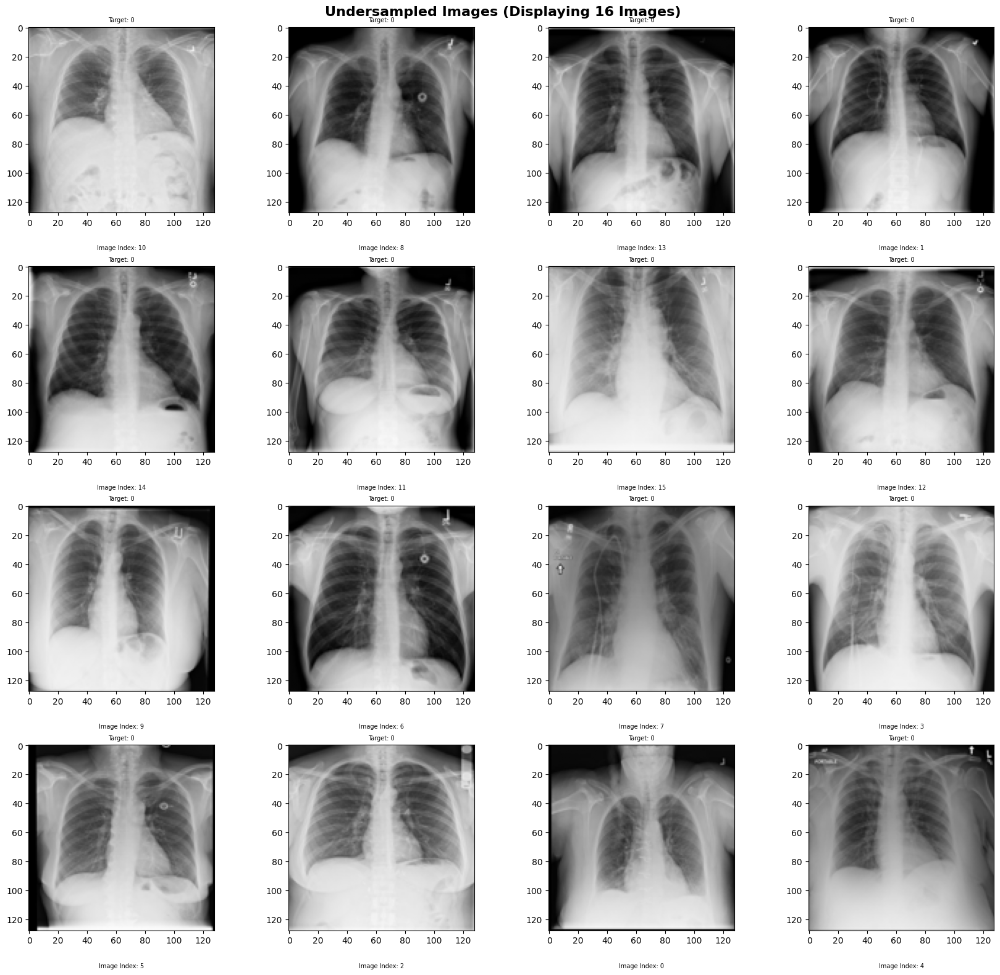

In [63]:
show_image(images=X_norm_undersampled,
           target=y_norm_undersampled,
           title='Undersampled Images', 
           num_display=16, 
           num_cols=4, 
           cmap='gray', 
           random_mode=True)

## 1.5 Image Enhancement 
Image Pre-processing for Chest X-ray

<u>used</u> to improve their visual quality and enhance the details within the images.

Aim: 
- Improve the visibility of details in the image
- Enhance the contrast of the image

### 1.5.1 Contrast Stretching:
- Objective: Enhance the visibility of details and improve contrast in an image.
- Goal: Increase the dynamic range of pixel values by stretching the intensity values to a desired range.

In [64]:
from skimage import exposure

In [65]:
def contrast_stretching(X):
    p2, p98 = np.percentile(X, (2, 98))
    stretched_img = exposure.rescale_intensity(X, in_range=(p2, p98))
    return stretched_img

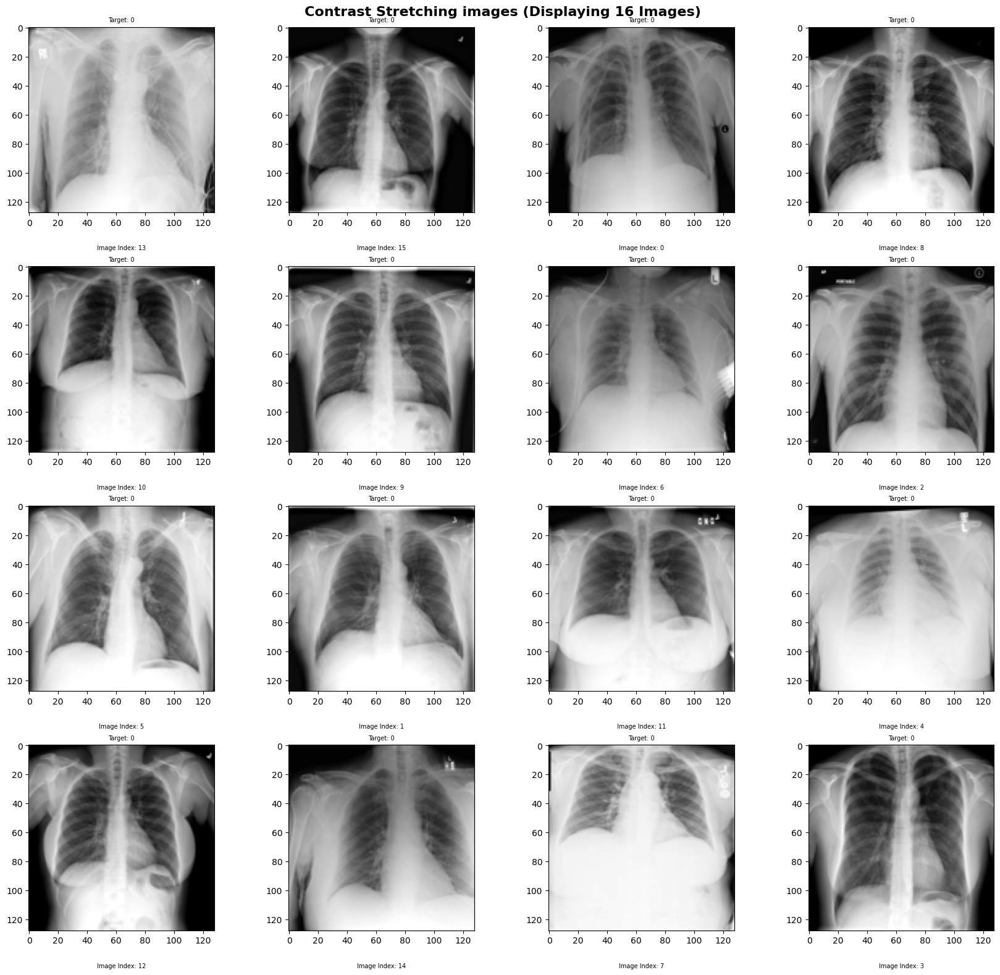

In [66]:
X_stretched = contrast_stretching(X_imbalanced[0:16])
y_stretched = y_imbalanced[0:16]
show_image(images=X_stretched,
           target=y_stretched,
           title='Contrast Stretching images', 
           num_display=16, 
           num_cols=4, 
           cmap='gray', 
           random_mode=True)

### 1.5.2 Histogram Equalization:
- Objective: Enhance the global contrast and improve the overall brightness distribution in an image.
- Goal: Adjust the pixel intensity distribution to achieve a uniform histogram.

In [67]:
def equalization(X):
    eq_img = exposure.equalize_hist(X)
    return eq_img

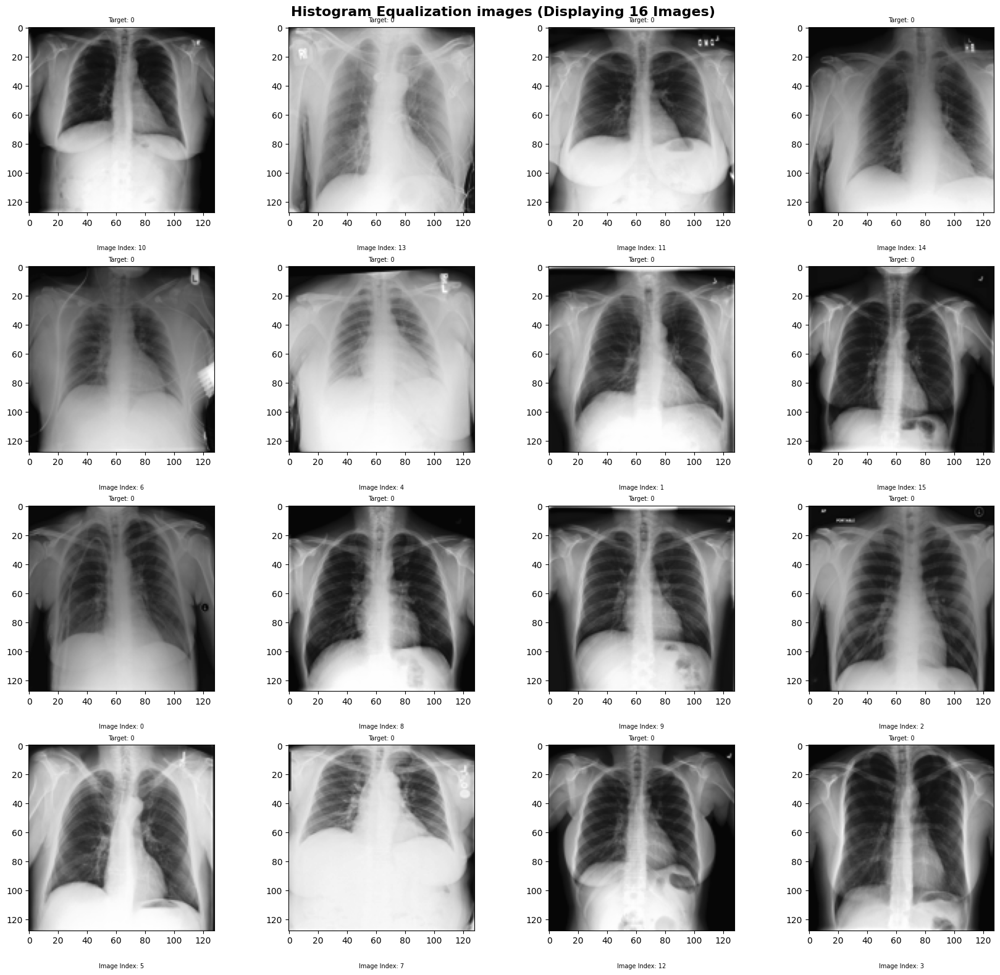

In [68]:
X_eq = equalization(X_imbalanced[0:16])
y_eq = y_imbalanced[0:16]
show_image(images=X_eq,
           target=y_eq,
           title='Histogram Equalization images', 
           num_display=16, 
           num_cols=4, 
           cmap='gray', 
           random_mode=True)

### 1.5.3 Adaptive Histogram Equalization:
- Objective: Enhance the contrast while preserving local details in an image.
- Goal: Apply histogram equalization locally to different regions of an image.

Usage example: 
``` python
def adaptive_equalization(X, clip_limit):
    '''
    :Parameters:
    X (ndarray (n,)): Input data as a numpy array, X.shape should be (128, 128, 1)
    clip_limit (int or float): used to control the contrast
    '''
    # Normalize the input image to the range of -1 to 1 and perform adaptive histogram equalization
    X_normalized = (X - np.min(X)) / (np.max(X) - np.min(X))
    X_normalized = (X_normalized * 2) - 1  # Scale to -1 to 1
    adapteq_img = exposure.equalize_adapthist(
        X_normalized, clip_limit=clip_limit)

    return adapteq_img

```

> Note: I added '**batch_size**' parameter, Because of computational and memory constraints.

In [69]:
def adaptive_equalization(X, clip_limit, batch_size=None):
    '''
    :Parameters:
    X (ndarray (n,)): Input data as a numpy array, X.shape should be (128, 128, 1)
    clip_limit (int or float) (default is  0.01): used to control the contrast, normalized between 0 and 1 (higher values give more contrast). 
    batch_size (int): Size of the batch to process. If None, the entire input is processed at once.
    '''
    if batch_size is None:
        # Normalize the input image to the range of -1 to 1 and perform adaptive histogram equalization
        X_normalized = (X - np.min(X)) / (np.max(X) - np.min(X))
        X_normalized = (X_normalized * 2) - 1  # Scale to -1 to 1
        adapteq_img = exposure.equalize_adapthist(
            X_normalized, clip_limit=clip_limit)
    else:
        # Process data in batches
        num_batches = int(np.ceil(len(X) / batch_size))
        batch_results = []

        for i in tqdm(range(num_batches),desc='processing...'):
            start_idx = i * batch_size
            end_idx = min((i + 1) * batch_size, len(X))

            # Normalize the input image to the range of -1 to 1 and perform adaptive histogram equalization for each batch
            X_normalized = (X[start_idx:end_idx] - np.min(X[start_idx:end_idx])) / \
                (np.max(X[start_idx:end_idx]) - np.min(X[start_idx:end_idx]))
            X_normalized = (X_normalized * 2) - 1  # Scale to -1 to 1
            adapteq_img_batch = exposure.equalize_adapthist(
                X_normalized, clip_limit=clip_limit)
            batch_results.append(adapteq_img_batch)

        # Concatenate the batch results
        adapteq_img = np.concatenate(batch_results, axis=0)

    return adapteq_img

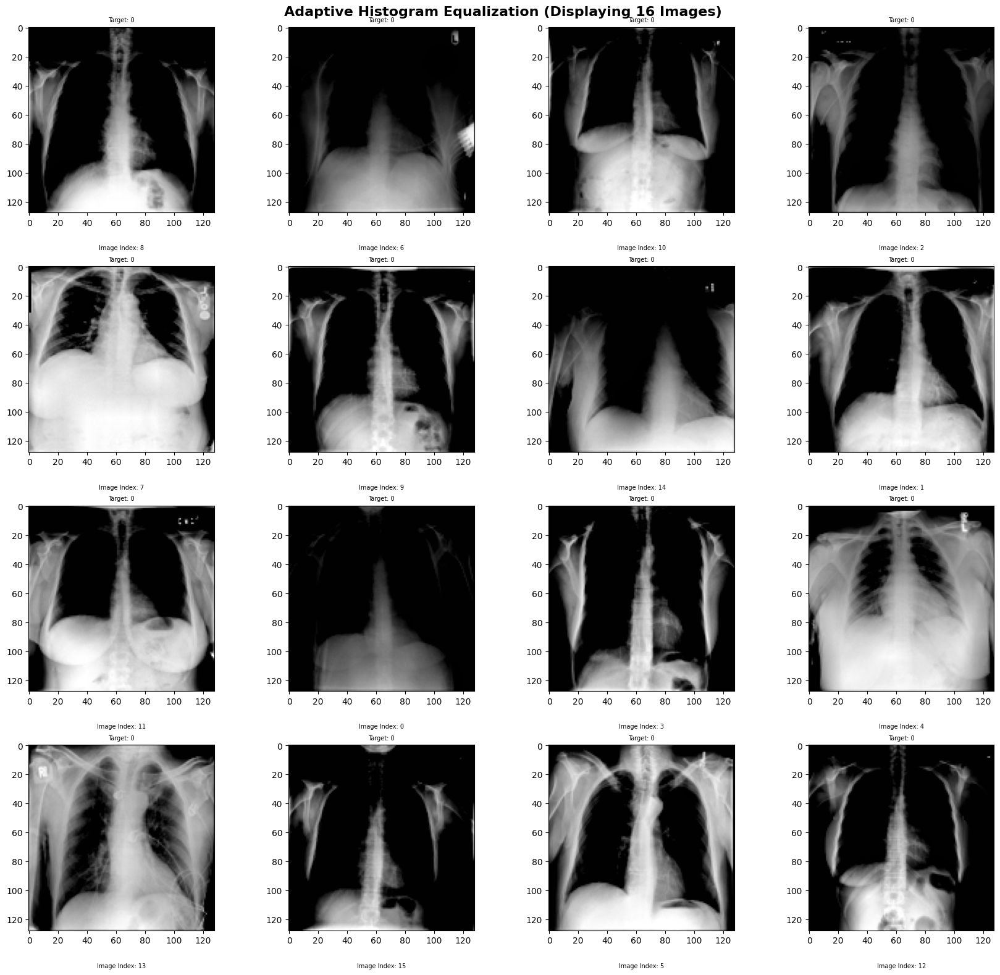

In [70]:
X_adapteq = adaptive_equalization(X_imbalanced[0:16], 0.01)
y_adapteq = y_imbalanced[0:16]
show_image(images=X_adapteq,
            target=y_adapteq,
            title='Adaptive Histogram Equalization', 
            num_display=16, 
            num_cols=4, 
            cmap='gray', 
            random_mode=True)

### 1.5.4 Summary of each Image Enhancement 

In [71]:
sample = X_imbalanced[0,:,:,:]
sample.shape

(128, 128, 3)

In [72]:
# 1. Load a normal image
img = sample

# 2. Contrast stretching
img_cs = contrast_stretching(img)

# 3. Histogram Equalization
img_eq = equalization(img)

# 4. Adaptive Equalization
img_adapteq = adaptive_equalization(img, 0.01)

methods = ['Low contrast image', 'Contrast stretching',
           'Histogram equalization', 'Adaptive equalization']
images_3 = [img, img_cs, img_eq, img_adapteq]

/opt/conda/lib/python3.10/site-packages/skimage/_shared/utils.py:316: UserWarning: This might be a color image. The histogram will be computed on the flattened image. You can instead apply this function to each color channel, or set channel_axis.
  return func(*args, **kwargs)


In [73]:
def img_and_hist_single_img(image, axes, bins=100):
    '''
    Plot an image along with its histogram and cumulative histogram.
    '''
    image = img_as_float(image)
    ax_img, ax_hist = axes
    ax_cdf = ax_hist.twinx()

    # Display image
    ax_img.imshow(image, cmap=plt.cm.gray)
    ax_img.set_axis_off()

    # Display histogram
    ax_hist.hist(image.ravel(), bins=bins, histtype='step', color='black')
    ax_hist.ticklabel_format(axis='y', style='scientific', scilimits=(0, 0))
    ax_hist.set_xlabel('Pixel intensity')
    # ax_hist.set_xlim(0, 1)
    ax_hist.set_yticks([])

    # Display cumulative distribution
    img_cdf, bins = exposure.cumulative_distribution(image, bins)
    ax_cdf.plot(bins, img_cdf, 'r')
    ax_cdf.set_yticks([])

    return ax_img, ax_hist, ax_cdf

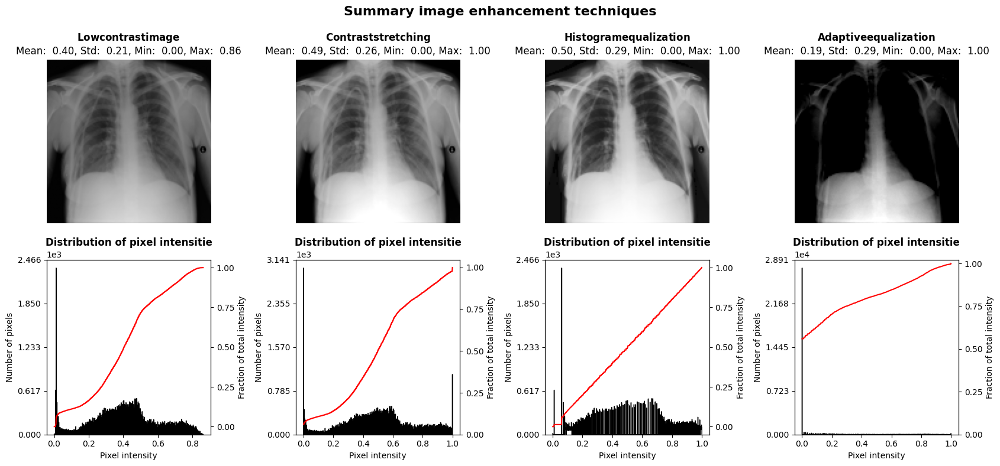

In [74]:
# Display results
fig, axes = plt.subplots(2, 4, figsize=(17, 8))

for i, (method, image) in enumerate(zip(methods, images_3)):
    ax_img, ax_hist, ax_cdf = img_and_hist_single_img(image, axes[:, i], bins=555)

    mean_value = np.mean(image)
    std_value = np.std(image)
    min_value = np.min(image)
    max_value = np.max(image)

    ax_img.set_title(
        r'$\bf{' + f'{method}'+'}$'+f'\nMean: {mean_value: .2f}, Std: {std_value: .2f}, Min: {min_value: .2f}, Max: {max_value: .2f}', fontsize=12)

    y_min, y_max = ax_hist.get_ylim()
    ax_hist.set_title(
        'Distribution of pixel intensitie', fontsize=12, fontweight='bold')
    ax_hist.set_ylabel('Number of pixels')
    ax_hist.set_yticks(np.linspace(0, y_max, 5))

    ax_cdf.set_ylabel('Fraction of total intensity')
    ax_cdf.set_yticks(np.linspace(0, 1, 5))

plt.suptitle('Summary image enhancement techniques',
             fontsize=16, fontweight='bold')
fig.tight_layout()
plt.show()

### Explanation

**Overview of plot**: aims to improve the contrast "Low contrast image."

**Red line**: (Black/White balances) A steeper curve indicates an increased Black/White intensity

| Method | Range | Pixel Intensity Distribution | Image | Conclusion | 
| --- | --- | --- | --- | --- |
| Low Contrast | [0, 255] | Original image | Original image | Original image |
| Contrast Stretching | [0, 1] | Similar distribution to original image | Similar to original image | Dataset normalized, Distribution similar to original image |
| Histogram Equalization | [0, 1] | New distribution | Similar to original image, But a little bit higher contrast |  Dataset normalized, Black/White is balanced |
| Adaptive Histogram Equalization | [0, 1] | New distribution | High contrast, Different local contrast in different regions of the image compared to the original image | Dataset normalized, Desirable contrast |

### How to consider 
<u>Answer</u> In fact we need to experiment <b>all image enhancement techniques</b> for Training in CNN, Which one give us a better Performance?


# 2. CNN:

## Deep Learning - Convolutional Neural Networks
Convolutional Neural Networks (CNNs) are a class of deep learning algorithms specifically designed for image processing, pattern recognition, and computer vision tasks. They have revolutionized the field of computer vision and have achieved state-of-the-art results in various image-related applications, such as object detection, image classification, segmentation, and more.

CNN are designed to perform tasks on the 2-D image, In the context of binary classification for TB detection, we can customize the output layer of the CNN to have a single unit, which will classify the input as either TB or normal.

![Alt Text](https://dwbi1.files.wordpress.com/2021/07/fig-1-cnn-architecture.jpg)

Image Source: https://dwbi1.wordpress.com/2021/07/04/what-is-convolutional-neural-network-cnn/

![Alt Text](https://www.mdpi.com/electronics/electronics-11-01775/article_deploy/html/images/electronics-11-01775-g001.png)
Image Source: https://www.mdpi.com/2079-9292/11/11/1775

### Why CNN?
CNNs are specifically suitable for image data:
- ANN (Artificial Neural Network) - Tabular data/ 1D -  used for tasks such as regression, binary classification, and multi-class classification on structured data
- RNN (Recurrent Neural Network) - Tabular data/ 1D (Time Series), designed for handling sequential data
- CNN (Convolutional Neural Network) - Image

### Use Cases 
#### ANN (Artificial Neural Network)

Data Type: Tabular data/1D, Structured data

Typical Use Cases:

- Regression
- Binary Classification
- Multi-class Classification (structured data)

#### RNN (Recurrent Neural Network)

Data Type: Tabular data/1D (Time Series), Structured data

Typical Use Cases:

- Time Series Forecasting
- Natural Language Processing
- Speech Recognition

#### CNN (Convolutional Neural Network)

Data Type: Image, Unstructured data

Typical Use Cases:

- Image Classification
- Object Detection
- Image Segmentation
- Image Generation

## 2.1 How CNNs Work:

Convolutional Neural Networks (CNNs) designed for image and visual data processing.

Training Process:
- Forward propagation
    - Receives the input images in a variable (say X) and applies a series of linear transformations through hidden layers using activation functions. until the **final output** layer produces predictions for the given input.
- Backward propagation
    - Randomly initialized the weights, biases and Adjust/Update parameters (weights and biases) during this step to minimize the Error/Loss function (**Gradient Optimization**) and improve the model's performance. 

CNNs Learning: Detecting Features in Images
- Convolutional Layers: ability to learn and detect the entire image and patterns, edges, and features. 
- Activation Functions: each layer applies an activation function, input images and calculated by activation function transform to the output of each layers.
- Pooling Layers: retain the most important information while reducing the computational complexity.

Summary using a Convolution or Pooling layer we reduce the dimensions of the input image of dimensions

Read more **Demystifying the Mathematics Behind Convolutional Neural Networks (CNNs)**: https://www.analyticsvidhya.com/blog/2020/02/mathematics-behind-convolutional-neural-network/

## 2.2 Layers

### 2.1.1 Convolutional Layers:
These layers perform the core operation in CNNs - convolution. Convolution involves sliding a set of small filters (also known as kernels) across the input image and computing dot products to create feature maps. Each filter specializes in detecting certain features like edges, corners, textures, etc.

For simplicity, let’s stick with grayscale images as we try to understand how CNNs work.


![image.png](https://editor.analyticsvidhya.com/uploads/750710_QS1ArBEUJjjySXhE.png)
Image Source: https://www.analyticsvidhya.com/blog/2021/05/convolutional-neural-networks-cnn/

 filter/kernel(3×3 matrix) and apply it to the input image to get the convolved feature. This convolved feature is passed on to the next layer.
 Each filter specializes in detecting certain features like edges, corners, textures, etc.


This layer learn to detect edges

![image-2.png](https://editor.analyticsvidhya.com/uploads/52794neural-networks-layers-visualization.jpg)

Image Source: https://www.analyticsvidhya.com/blog/2021/05/convolutional-neural-networks-cnn/

### 2.1.2 Pooling Layers:

![image.png](https://1299806939-files.gitbook.io/~/files/v0/b/gitbook-legacy-files/o/assets%2F-LvMRntv-nKvtl7WOpCz%2F-LvMRp9FltcwEeVxPYFs%2F-LvMRrqrlhiBpH5LD-_p%2FPooling_Simple_max.png?generation=1575572710691611&alt=media)

Image Source: https://leonardoaraujosantos.gitbook.io/artificial-inteligence/machine_learning/deep_learning/pooling_layer


Pooling layers are **used to summarize the important features extracted from the previous convolutional layers. These layers reduce the spatial dimensions of the feature maps, typically reducing them by half.**

Pooling layers reduce the spatial dimensions of feature maps while <u>preserving</u> essential information. Each pooling region is transformed into a single output value, representing the presence of a particular feature in that region.

Objective: 
- Reduces the spatial dimensions of the feature maps, making the model more efficient and reducing overfitting.
- Maintaining essential information while improving computational efficiency.

Common pooling techniques are **max pooling**, which selects the maximum value in a local region, and **average pooling**

### 2.1.3 Dropout Layer
Random drop some Neural, 
Dropout is a regularization technique used to prevent overfitting in deep learning models. It involves randomly deactivating a fraction of neurons during training.
**Dropout**:  will prevent our network from overfitting thus helping our network generalize better. How much dropout should we add after each layer?
0%, 10%, 20%, 30%, 40%, 50%, 60%, or 70%

How it works:

Installing the dropout layer, a so-called dropout probability must also be specified. This determines how many of the nodes/units in the layer will be set equal to 0. If we have an input layer with ten input values, a dropout probability of 10% means that one random input will be set equal to zero in each training pass. If instead, it is a hidden layer, the same logic is applied to the hidden nodes/units. So a dropout probability of 10% means that 10% of the nodes/units will not be used in each run.

Dropout layer is often <u>used</u> after a **Fully Connected (Dense) Layers**
> Note 1 **Dropout**:  will prevent our network from overfitting thus helping our network generalize better. How much dropout should we add after each layer?
0%, 10%, 20%, 30%, 40%, 50%, 60%, or 70%


### 2.1.4 Flatten Layer
The Flatten layer reshapes the output from previous layers into a 1D vector. It is used to convert the multidimensional feature maps into a flat feature vector so that it can be processed by fully connected layers.
**Enables the utilization of fully connected layers to make predictions or decisions based on the learned features.**

Pros:
- Enables the model to process the learned features from convolutional layers in fully connected layers.
- Simplifies the representation of data, making it easier for the subsequent layers to interpret and learn from the features.
- Allows the model to be compatible with architectures that require 1D inputs, such as traditional fully connected neural networks.
Cons:
- might losing some locality information.

### 2.1.5 Fully Connected (Dense) Layers
Fully connected layers consist of a fixed number of neurons connected to every neuron in the previous layer. They help combine learned features and make the final predictions. ReLU activation functions are commonly used for hidden layers, introducing non-linearity. For binary classification tasks like TB detection, a sigmoid activation function is used in the output layer to produce a probability score between 0 and 1 for classifying an image as TB or normal.
**Combining the learned features from previous layers and making final predictions in a neural network.**

### 2.1.6 Output Layers 
The Output Layer is the final layer of a neural network that produces the model's predictions. In binary classification tasks like Tuberculosis (TB) detection, the output layer typically consists of a single neuron with a sigmoid activation function.

Objective:
output layer is to generate a probability score between 0 and 1, representing the likelihood of the input belonging to a particular class. In TB detection, the output layer aims to classify the input chest X-ray image as either TB positive or normal based on the learned features from the previous layers.

Outcomes:
**a probability score close to 0 for normal images and close to 1 for TB images**, allowing the model to classify the input X-ray images accurately.
By applying an appropriate threshold to the output probability score, we can make the final decision on whether an X-ray image is classified as TB positive or normal.

## 2.3 Hyperparameters in both **convolutional** and **pooling** layers

### 2.3.1 Padding
Padding is the process of adding extra border pixels around the input image before applying convolutions.

**Purpose**:
- preserve the spatial dimensions of the feature maps, especially at the edges, which can be lost during convolutional operations.
- helps avoid the reduction in the feature map's size, which can occur when using a large kernel or multiple layers of convolutions.
- Padding involves adding zero-value pixels around the input image. This helps to <u>preserve</u> valuable information during convolution and ensures that the feature map doesn't become excessively small.

**Problem**: When Convolution → smaller output

**Solution**: +Padding

**When to use**: 

Try using padding = same when you feel the border’s of the image might be important, Because when Convolution → smaller output
**Type of Padding**:

![0rs9l.gif](https://miro.medium.com/v2/resize:fit:4800/format:webp/0*jSYji1D43vJWZZ_5)

Image Source: https://sarathpanat.medium.com/all-about-convolutional-neural-network-cnn-6ccce6738958


1. Padding `'valid'` is the 1st figure.
    - means no padding at all. Just leave your data the same it was.    
2. Padding `'same'` is the 3rd figure.
    - The output is the same size. It is called SAME because for a convolution with a stride=1, (or for pooling) it should produce output of the same size as the input. 


### 2.3.2 Kernel size
refers small filter applied during the convolution operation.
Common kernel sizes are (3x3), (5x5), and (7x7), but other sizes

Purpose:
-  captures more contextual information

### 2.3.3 Stride 
skip scanning pixel
controls the step size of the filter as it scans the input image.
In both **convolutional** and **pooling** layers:
1. Convolutional Stride: A stride of 1 means the **filter** moves one **pixel** at a time
2. Pooling Stride: A stride of 1 means the **window** moves one **pixel** at a time




**Purpose**:
- faster computation and downsampling of the data.

**When to use**: 
- Stride = 1: Input data is small, and preserving spatial information is important.
- Stride > 1: Input data is large, help reduce computational cost and memory usage, But lead to **information loss**

![0_iqNdZWyNeCr5tCkc.gif](https://miro.medium.com/v2/resize:fit:640/format:webp/0*wW8SEzhhhTDN30Ow)

Image Source: https://sarathpanat.medium.com/all-about-convolutional-neural-network-cnn-6ccce6738958


> Noted 2 **Stride**: Stride just means the amount a filter moves during a covolution operation. So, a stride of 1 means that the filter will slide 1 pixel after each covolution operation as shown in this animation.


> Noted 3 **In practice**: Stride is often set based on experimentation and model performance on the validation set.

## 2.4 Activation Functions
### 2.4.1 ReLU Activation function 
The Rectified Linear Activation function (ReLU) is specifically used as a non-linear activation function, as opposed to other non-linear functions such as Sigmoid because it has been empirically observed that CNNs using ReLU are faster to train than their counterparts. ReLU is performed after every convolutional layer

The ReLU activation function is a one-to-one mathematical operation:
#### Why this Activations?  
Using non-linear activation functions like ReLU is crucial because real-world data and patterns are often complex and non-linear. If we only use linear activation functions, the neural network can only learn linear relationships, limiting its ability to capture more intricate patterns and reducing its performance. better performance in tasks like image classification, object detection, and more.

#### Output of this Activations?  
1. If the input is greater than or equal to zero, the output is equal to the input itself (Output = Input).
2. If the input is less than zero, the output is zero (Output = 0).

In mathematical terms, the ReLU function can be defined as follows:

$$ReLU(x) = max(0, x) \tag{1}$$



### 2.4.2 Sigmoid Activation function 
used in the output layer of neural networks for Binary classification tasks. The Sigmoid activation function is a non-linear activation commonly used in neural networks. It maps any input value to a range between 0 and 1, allowing it to interpret the input as probabilities.

The Sigmoid function can be written:
$$sigmoid(x) = \frac{1}{1+{e^{-x} }} \tag{2}$$
Where "x" is the input value, and "e" represents the exponential function.



#### Why this Activations?  
- <u>used</u> in the output layer of neural networks for binary classification tasks, where the goal is to classify data into two classes (e.g., yes or no, true or false). But in this notebook will as this binary as 0 and 1
- <u>converts</u> the model's raw output into a probability value

#### Output of this Activations?  
- <u>transforms</u> input values into probabilities between 0 and 1, making it suitable for binary classification tasks that require a probability-based decision.

Table representing the architecture of the CNN model 

<u>assume</u> unit_multiplier = 1.0

| Layer (Type)   | Number of Filters | Padding | Activation | Out of Activation Shape | Total Parameters            |
|-----------------|-------------------|---------|------------|--------------------------|-----------------------------|
| Input           | -                 | -       | -          | (128, 128, 1)            | 0                           |
| Conv2D          | 32 * unit_multiplier| Same    | ReLU       | (128, 128, 32)           | 320         |
| MaxPooling2D    | -                 | Same    | -          | (64, 64, 32)             | 0                           |
| Conv2D          | 64 * unit_multiplier| Same    | ReLU       | (64, 64, 64)             | 18,496      |
| MaxPooling2D    | -                 | Same    | -          | (32, 32, 64)             | 0                           |
| Conv2D          | 128 * unit_multiplier| Same    | ReLU       | (32, 32, 128)            | 73,856      |
| MaxPooling2D    | -                 | Same    | -          | (16, 16, 128)            | 0                           |
| Flatten         | -                 | -       | -          | (32768)                  | 0                           |
| Dense           | 128 * unit_multiplier| -      | ReLU       | (128)                    | 4,194,432  |
| Dropout         | -                 | -       | -          | (128)                    | 0                           |
| Dense           | 1                 | -       | Sigmoid    | (1)                      | 129                         |

Total Params: 4,287,809 

## 2.5 Adam Optimizer in Tensorflow

Adam Optimizer is a common technique for adjusting the weights and biases ($\vec{W}, b$ parameters) of a model to minimize its loss function (how well it performs).

### Formula:
The Adam optimizer updates the parameters using the following formula

$$W_{j} = W_{j}-\alpha\frac{\partial}{\partial W_{j}}J(\vec{W}, b)\times\epsilon$$ 
- **$W_{j}$**: Represents the parameter in the model. These parameters are the weights of the neural network, which are adjusted during the training process to minimize the loss function **$J(\vec{W},b)$**.

- **$\alpha$**: The learning rate, which controls the step size or rate of learning. It determines the size of the steps taken in the parameter space during optimization. A smaller learning rate slows down learning but can help in avoiding overshooting the optimal solution. The default value is typically set to 0.001.

- **$\frac{\partial}{\partial W_{j}}J(\vec{W}, b)$**: The gradient of the loss function **$J(\vec{W},b)$** with respect to the parameter  **$W_{j}$**. It indicates the direction and magnitude of the change needed to minimize the loss function.
- **$J(\vec{W},b)$**: The loss function, which measures the discrepancy between the predicted output of the model and the actual output. The goal of optimization is to minimize this loss function by adjusting the model parameters **$\vec{W}$** and **$\beta$** biases .

### Parameters:

- **alpha ($\alpha$)** (Default=0.001) (need to be tuned). 
    Controls the step size or ability of learning. (A smaller value slows down learning and may increase training time.)
- **beta1 ($\beta1$)** (Default=0.9).
    Controls the decay of the learning rate, with 0.9 being close to 1.
- **beta2 ($\beta2$)** (Default=0.999).
    Controls the decay of the learning rate, with 0.99 being close to 1.
   
- **epsilon ($\epsilon$)** (Default=1e-7 ≈ 0.00000001). 
    A small value (1e-7 ≈ 0.00000001) to ensure numerical stability during optimization.

Source: [Adam optimization](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam)

## 2.6 CNN Classifier with GridSearchCV
The CNN architecture is highly scalable and customizable, allowing you to adjust various parameters to suit your specific needs. Here's how you can customize the model:

### Objective:
Objective:
- **Scalability and Customizability**: designed to be highly scalable and customizable, allowing users to adjust various parameters such as input shape, unit multiplier, convolutional and pooling layer configurations
- **Integration with GridSearchCV**: designed to use with GridSearchCV library, the CNN Class facilitates automated hyperparameter tuning, enabling more efficiently search through parameter grid and identify the combination of hyperparameters for their CNN models.

### Usage with GridSearchCV

The CNN classifier seamlessly integrates with scikit-learn's `GridSearchCV` for hyperparameter tuning, providing a scalable solution for optimizing model performance. Here's how you can use it:

```python
# Example usage with GridSearchCV

cnn = CNN(unit_multiplier=1,
          input_shape=(128,128,3))

param_grid = {
    'batch_size': [16, 32],
    'epochs': [10, 20],
    'learning_rate': [0.001, 0.01]
}

grid_search = GridSearchCV(estimator=cnn, param_grid=param_grid, cv=5)
grid_search.fit(X_train, y_train)

```

In [75]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, AveragePooling2D, Flatten, Dropout, Dense
from sklearn.model_selection import KFold
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score

In [76]:
class CNN(BaseEstimator, ClassifierMixin):
    def __init__(self, 
                 # CNN Architecture
                 input_shape=(128, 128, 3), 
                 unit_multiplier=1.0, 
                 # CNN Hyperparameters
                 conv_padding='same', 
                 conv_kernel_size=(3, 3),
                 conv_stride=1, 
                 pool_padding='same', 
                 pool_kernel_size=(2, 2), 
                 pool_stride=2, 
                 dropout=0, 
                 l1_lambda=None,
                 l2_lambda=None, 
                 pooling_type='max', 
                 # Adam Optimizer Configuration (Default)
                 learning_rate=0.001,
                 beta1=0.9,
                 beta2=0.999,
                 epsilon=1e-07,
                 # Training Configuration
                 batch_size=32,
                 epochs=10,
                 verbose=0,
                 metrics=['accuracy'],
                 ):
        
        self.input_shape = input_shape
        self.unit_multiplier = unit_multiplier
        self.conv_padding = conv_padding
        self.conv_kernel_size = conv_kernel_size
        self.conv_stride = conv_stride
        self.pool_padding = pool_padding
        self.pool_kernel_size = pool_kernel_size
        self.pool_stride = pool_stride
        self.dropout = dropout
        self.l1_lambda = l1_lambda
        self.l2_lambda = l2_lambda
        self.pooling_type = pooling_type
        self.learning_rate=learning_rate
        self.beta1=beta1
        self.beta2=beta2
        self.epsilon=epsilon
        self.metrics = metrics
        self.batch_size=batch_size
        self.epochs = epochs
        self.verbose = verbose
        self.model = self.architecturize()

    def architecturize(self):
        reg_l1 = None
        reg_l2 = None

        if self.l1_lambda is not None:
            reg_l1 = tf.keras.regularizers.l1(self.l1_lambda)

        if self.l2_lambda is not None:
            reg_l2 = tf.keras.regularizers.l2(self.l2_lambda)

        model = Sequential()
        model.add(Conv2D(
            int(32 * self.unit_multiplier),
            self.conv_kernel_size,
            strides=self.conv_stride,
            padding=self.conv_padding,
            activation='relu',
            kernel_regularizer=reg_l1,
            input_shape=self.input_shape))

        if self.pooling_type == 'max':
            model.add(MaxPooling2D(
                pool_size=self.pool_kernel_size,
                strides=self.pool_stride,
                padding=self.pool_padding))
        elif self.pooling_type == 'avg':
            model.add(AveragePooling2D(
                pool_size=self.pool_kernel_size,
                strides=self.pool_stride,
                padding=self.pool_padding))
        else:
            raise ValueError("Invalid pooling_type. Use 'max' or 'avg'.")

        model.add(Conv2D(
            int(64 * self.unit_multiplier),
            self.conv_kernel_size,
            strides=self.conv_stride,
            padding=self.conv_padding,
            kernel_regularizer=reg_l2,
            activation='relu'))

        if self.pooling_type == 'max':
            model.add(MaxPooling2D(
                pool_size=self.pool_kernel_size,
                strides=self.pool_stride,
                padding=self.pool_padding))
        elif self.pooling_type == 'avg':
            model.add(AveragePooling2D(
                pool_size=self.pool_kernel_size,
                strides=self.pool_stride,
                padding=self.pool_padding))
        else:
            raise ValueError("Invalid pooling_type. Use 'max' or 'avg'.")

        model.add(Conv2D(
            int(128 * self.unit_multiplier),
            self.conv_kernel_size,
            strides=self.conv_stride,
            padding=self.conv_padding,
            kernel_regularizer=reg_l2,
            activation='relu'))

        if self.pooling_type == 'max':
            model.add(MaxPooling2D(
                pool_size=self.pool_kernel_size,
                strides=self.pool_stride,
                padding=self.pool_padding))
        elif self.pooling_type == 'avg':
            model.add(AveragePooling2D(
                pool_size=self.pool_kernel_size,
                strides=self.pool_stride,
                padding=self.pool_padding))
        else:
            raise ValueError("Invalid pooling_type. Use 'max' or 'avg'.")

        model.add(Flatten())
        model.add(Dense(
            units=int(128 * self.unit_multiplier),
            activation='relu',
            kernel_regularizer=reg_l2))

        model.add(Dropout(self.dropout))
        model.add(Dense(units=1, activation='sigmoid'))
        
        # Adam Optimizer Algorithm
        self.optimizer = tf.keras.optimizers.Adam(
                learning_rate=self.learning_rate,
                beta_1= self.beta1,
                beta_2= self.beta2,
                epsilon=self.epsilon,
            )
        model.compile(loss='binary_crossentropy',
                      optimizer=self.optimizer,
                      metrics=self.metrics)
    
        return model

    def predict_(self, X, threshold=0.5):

        probabilities = self.model.predict(X, verbose=self.verbose)
        binary_predictions = (probabilities > threshold).astype("int32")
        return binary_predictions, probabilities
    
    def fit(self, X, y):
        self.model.fit(X, y, epochs=self.epochs, batch_size=self.batch_size, verbose=self.verbose)
        return self
    
    def predict(self, X):
        return self.model.predict(X)

    def score(self, X, y):
        y_pred = self.predict(X)
        return accuracy_score(y, y_pred)
    
    def summary(self):
        self.model.summary()
        
    def cv(self, X, y, epochs=10, batch_size=16, cv=5, verbose=1):
        kf = KFold(n_splits=cv, shuffle=True)
        scores = []
        for train_index, test_index in kf.split(X):
            X_train, X_test = X[train_index], X[test_index]
            y_train, y_test = y[train_index], y[test_index]
            self.model.fit(X_train, y_train, epochs=epochs if epochs else self.epochs, batch_size=batch_size if batch_size else self.batch_size, verbose=verbose if verbose else self.verbose)
            _, accuracy = self.model.evaluate(X_test, y_test, verbose=self.verbose)
            scores.append(accuracy)
        return scores
    
    def train(self, X_train, y_train, X_val, y_val, epochs, batch_size):

        steps_per_epoch = len(X_train) // batch_size
        validation_steps = len(X_val) // batch_size
        
        history = self.model.fit(
            X_train, y_train,
            batch_size=batch_size,
            epochs=epochs,
            steps_per_epoch=steps_per_epoch,
            validation_steps=validation_steps,
            validation_data=(X_val, y_val),
            verbose=self.verbose,
        )
        return history

In [77]:
cnn = CNN(unit_multiplier=1,
          input_shape=(128,128,3))

In [78]:
cnn.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 64, 64, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 64, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 32, 32, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 32, 32, 128)       73856     
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 16, 16, 128)       0

# 3. Splitting the Dataset:
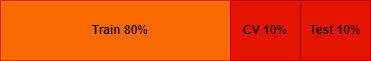

Split the dataset into training, validation, and test sets. The usual split ratios are 
- 80% for training, 
- 10% for validation, 
- and 10% for testing. 

Ensure that the classes are balanced in each split.

In [79]:
from sklearn.model_selection import train_test_split

In [80]:
def viz_class_distribution(X, y, title, classe_labels, train_percent=0.8, val_percent=0.1, test_percent=0.1, show_plot=True):
    '''
    :Parameters:
    - X (numpy array): The input feature matrix of shape (num_examples, num_features).
    - y (numpy array): The target labels of shape (num_examples,).
    - title (str): The title for the entire plot.
    - classes (list): A list of class labels, e.g., ['Normal', 'Tuberculosis'].
    - train_percent (float): Percentage of data for training set.
    - val_percent (float): Percentage of data for validation set.
    - test_percent (float): Percentage of data for test set.
    - show_plot (Boolean): True or False of d

    :Returns:
    - X_train, y_train, X_test, y_test, X_val, y_val: The subsets of the data.
    '''
    assert train_percent + val_percent + test_percent == 1.0, "Sum of train_percent, val_percent, and test_percent should be 1.0"

    # Convert y to integers
    y = y.astype(int)

    # Split the data
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=val_percent + test_percent, random_state=42, stratify=y)

    test_size = test_percent / (val_percent + test_percent)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=test_size, random_state=42, stratify=y_temp)
    if show_plot:
        # Create a subplot with 3 columns and 1 row
        fig, axs = plt.subplots(1, 3, figsize=(15, 5))

        # List of subset names
        subset_names = ['Train', 'Test', 'Validation']
        n = len(X)

        # Iterate over subsets
        for i, subset in enumerate([(X_train, y_train), (X_test, y_test), (X_val, y_val)]):
            X_subset, y_subset = subset
            n_subset = len(y_subset)
            # Get the class counts
            class_counts = np.bincount(y_subset)

            # Plot histogram for the current subset
            axs[i].bar(classe_labels, class_counts, color='#AA99FF')
            subtitle = r'$\bf{' + subset_names[i] + \
                '}$' + f' {int(n_subset/n*100)} %'
            axs[i].set_title(
                subtitle + f'\n Size = {X_subset.shape[0]}', fontsize=18)
            axs[i].set_xlabel('Class')
            axs[i].set_ylabel('Number of examples')

            # Add labels to the bars
            for j, count in enumerate(class_counts):
                axs[i].text(j, count, str(count), ha='center',
                            va='bottom', fontsize=12)

        class_counts = np.bincount(y)
        class_balance_text = ' | '.join(
            [f'{class_label} ({count})' for class_label, count in zip(classe_labels, class_counts)])
        plt.suptitle(f'{title}' + f'\n Training examples (X): {X.shape[0]}' +
                     f'\nTarget (y): {class_balance_text}', fontsize=20)

        plt.tight_layout()
        plt.show()

    return X_train, y_train, X_test, y_test, X_val, y_val

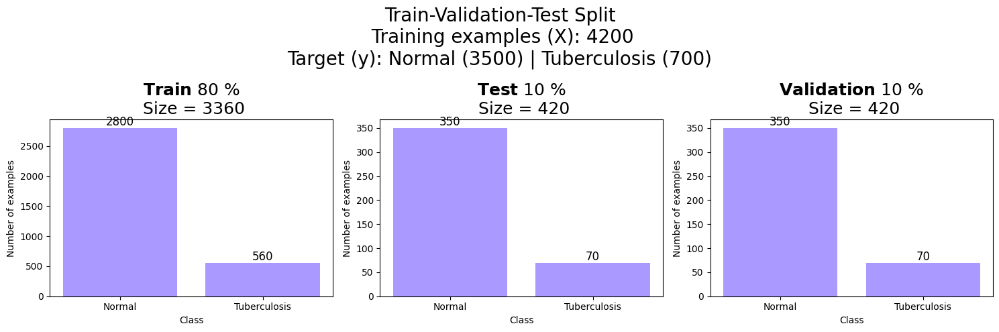

In [81]:
X_train, y_train, X_test, y_test, X_val, y_val = viz_class_distribution(X=X_imbalanced, 
                        y=y_imbalanced, 
                        title='Train-Validation-Test Split', 
                        classe_labels=['Normal', 'Tuberculosis'], 
                        train_percent=0.8, 
                        val_percent=0.1, 
                        test_percent=0.1)

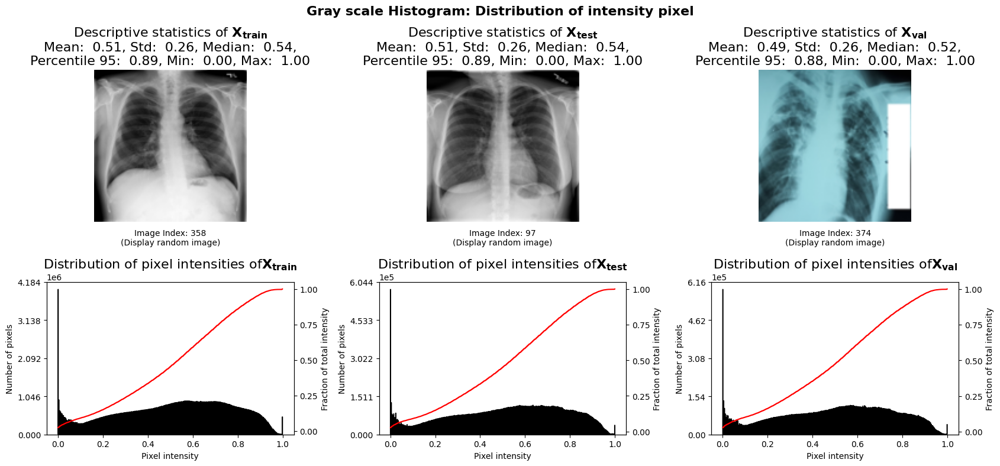

In [82]:
images = [X_train, X_test, X_val]
subsets = ['X_{train}', 'X_{test}', 'X_{val}']
# For visualization
plot_gray_scale_histogram(images=images, titles=subsets, bins=555)

In [83]:
# Remove unused variables to free up memory
del x_norm
del y_norm
del x_tb
del y_tb
del norm_tb_images
del abnorm_tb_images
del norm_tb_labels
del abnorm_tb_labels

del norm_norm_images
del abnorm_norm_images
del norm_norm_labels
del abnorm_norm_labels

del tb_cropped_images, tb_cropped_labels

del X_tb_augmented, y_tb_augmented

# 4. Modeling
`Learning Problem`: Binary Classification
## 4.1 Experimental Plan
- Experiment A - Baseline Performance
- Experiment B - Data Sampling Technique or Data Augmentation
- Experiment C - Image Size
- Experiment D - Image Mode: RGB vs. Grayscale
- Experiment E - Image Enhancement

### 4.1.1. Experiment A - Baseline Performance:
The baseline performance is evaluated without applying any technique to the dataset. (128x128, Dataset contains Both RGB and Grayscale, Class Ratio is 3,500: 700)

In [84]:
epochs = 10
batch_size = 64

In [85]:
cnn1 = CNN(unit_multiplier=0.05,
          input_shape=(128,128,3))
cnn1.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 128, 128, 1)       28        
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 64, 64, 1)         0         
 g2D)                                                            
                                                                 
 conv2d_4 (Conv2D)           (None, 64, 64, 3)         30        
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 32, 32, 3)         0         
 g2D)                                                            
                                                                 
 conv2d_5 (Conv2D)           (None, 32, 32, 6)         168       
                                                                 
 max_pooling2d_5 (MaxPoolin  (None, 16, 16, 6)        

In [86]:
history = cnn1.train(X_train, y_train, X_val, y_val,
                   epochs=epochs,
                   batch_size=batch_size)

In [87]:
def plot_history(history):
    # Accuracy 
    plt.plot(history.history['accuracy'], c = 'royalblue', linewidth = 2.5, label = 'Training')
    plt.plot(history.history['val_accuracy'], c = 'firebrick', linestyle = '--', label = 'Valid')
    plt.title('Model accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left', frameon = True, facecolor = 'white')
    plt.show()

    # Loss 
    plt.plot(history.history['loss'], c = 'royalblue', linewidth = 2.5, label = 'Training')
    plt.plot(history.history['val_loss'], c = 'firebrick', linestyle = '--', label = 'Valid')
    plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left',frameon = True, facecolor = 'white')
    plt.show()

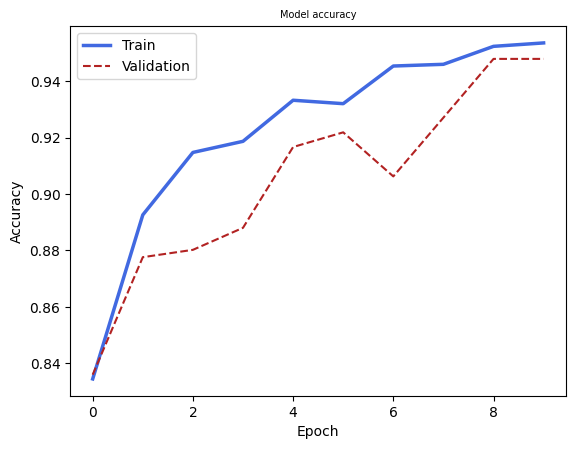

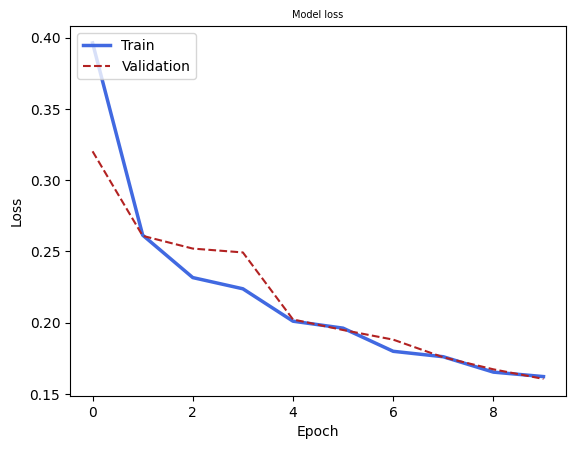

In [88]:
plot_history(history)

### Evaluation function
In binary classification, we define the metrics commonly used for evaluating binary classification models:

- True Positive (TP): The model correctly predicted a positive class sample.
- True Negative (TN): The model correctly predicted a negative class sample.
- False Positive (FP): The model incorrectly predicted a positive class sample (Type I error).
- False Negative (FN): The model incorrectly predicted a negative class sample (Type II error).

Metrics include:

- `Precision`:
    - Precision measures the proportion of true positive predictions among all positive predictions.
    
$$Precision = \frac{TP}{(TP + FP)} \tag{1}$$

- `Recall (Sensitivity)`:
    - Recall measures the proportion of true positive predictions among all actual positive instances.
$$Recall = \frac{TP}{(TP + FN)} \tag{2}$$

- `Specificity`:
    - Specificity measures the proportion of actual negative instances that were correctly identified.
$$Specificity = \frac{TN}{(TN + FP)} \tag{3}$$

- `F1 Score`:
    - F1 Score is the harmonic mean of precision and recall, providing a balance between the two metrics.
$$F1 Score = 2 \times \frac{(Precision \times Recall)}{(Precision + Recall)} \tag{4}$$

- `Accuracy`:
    - Accuracy measures the proportion of correct predictions among all predictions made.
$$Accuracy = \frac{(TP + TN)}{(TP + TN + FP + FN)} \tag{5}$$

- `Area Under the ROC Curve (AUC)`:
    - AUC represents the area under the Receiver Operating Characteristic (ROC) curve, which measures the model's ability to `distinguish` between `positive` and `negative` classes.

In [89]:
import json
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, accuracy_score, roc_curve, roc_auc_score, f1_score, auc

In [90]:
def evaluate(estimator, estimator_tag, experiment_tag, X_train, y_train, X_test, y_test, X_val, y_val):
    """
    Evaluate the performance of a model on different subsets of data.

    Args:
    - estimator: The trained model object
    - estimator_tag: Identifier for the model
    - experiment_tag: Identifier for the Experiment
    - X_train: Training data
    - y_train: Training labels
    - X_test: Test data
    - y_test: Test labels
    - X_val: Validation data
    - y_val: Validation labels

    Returns:
    - evaluation_results: DataFrame containing evaluation metrics
    """
    subsets = {'Train': (X_train, y_train), 'Test': (X_test, y_test), 'Validation': (X_val, y_val)}
    performances = []
    for subset_name, (X_subset, y_actual) in subsets.items():
        # Model Prediction/Y hat
        # y_pred_binary_predictions, y_probabilities
        
        y_pred, y_prob = estimator.predict_(X_subset)

        # Calculate ROC curve and AUC score
        fpr, tpr, thresholds = roc_curve(y_actual, y_prob)
        auc_score = auc(fpr, tpr)

        # Classification Report
        report = classification_report(y_actual, y_pred, output_dict=True)
        report_dict = json.loads(json.dumps(report))

        # Extract precision and recall from report_dict
        precision = report_dict['weighted avg']['precision']
        recall = report_dict['weighted avg']['recall']
        accuracy = report_dict['accuracy']
        f1_score = report_dict['weighted avg']['f1-score']

        # Confusion Matrix
        cm = confusion_matrix(y_actual, y_pred)
        TP = cm[0][0]
        FP = cm[0][1]
        FN = cm[1][0]
        TN = cm[1][1]
        
        sensitivity = TP / (TP + FN)  # Sensitivity or True Positive Rate
        specificity = TN / (TN + FP)  # Specificity or True Negative Rate

        performance = {
            'Model': estimator_tag,
            'Experiment_tag':experiment_tag,
            'Subset': subset_name,
            'FPR':fpr,
            'TPR':tpr,
            'TP': TP,
            'FP': FP,
            'FN': FN,
            'TN': TN,
            'Precision': precision,
            'Recall': recall,
            'Sensitivity': sensitivity,
            'Specificity': specificity,
            'F1 Score': f1_score,
            'AUC': auc_score,
            'Accuracy': accuracy,
        }

        performances.append(performance)

    return pd.DataFrame(performances)

In [91]:
evaluation_1 = evaluate(cnn1, 
                        'CNN_1_Baseline', 
                        'A',
                        X_train, 
                        y_train, 
                        X_test, 
                        y_test, 
                        X_val, 
                        y_val)

In [92]:
evaluation_1

,Model,Experiment_tag,Subset,FPR,TPR,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
0,CNN_1_Baseline,A,Train,"[0.0, 0.011428571428571429, 0.0114285714285714...","[0.0, 0.7517857142857143, 0.7821428571428571, ...",2762,38,93,467,0.960313,0.961012,0.967426,0.924752,0.960195,0.985249,0.961012
1,CNN_1_Baseline,A,Test,"[0.0, 0.011428571428571429, 0.0114285714285714...","[0.0, 0.7, 0.8857142857142857, 0.8857142857142...",346,4,14,56,0.956481,0.957143,0.961111,0.933333,0.955796,0.983388,0.957143
2,CNN_1_Baseline,A,Validation,"[0.0, 0.011428571428571429, 0.0114285714285714...","[0.0, 0.6571428571428571, 0.7142857142857143, ...",342,8,15,55,0.943822,0.945238,0.957983,0.873016,0.944068,0.982204,0.945238


In [93]:
def plot_confusion_matrix(estimator,X,  y, subset_name):
    y_pred, y_prob = estimator.predict_(X)
    
    cm = confusion_matrix(y, y_pred)
    labels = ['Negative', 'Positive']

    # Extract TP, TN, FP, FN
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn)  # Sensitivity or True Positive Rate
    specificity = tn / (tn + fp)  # Specificity or True Negative Rate

    plt.figure(figsize=(18, 9))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels)



    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix - {subset_name}\n'
              f'True Positives: {tp} | True Negatives: {tn}\n'
              f'False Positives: {fp} (Type I error) | False Negatives: {fn} (Type II error)\n'
              f'Sensitivity (True Positive Rate): {sensitivity:.4f} | Specificity (True Negative Rate): {specificity:.4f}',
              loc='center', wrap=True)
    plt.show()

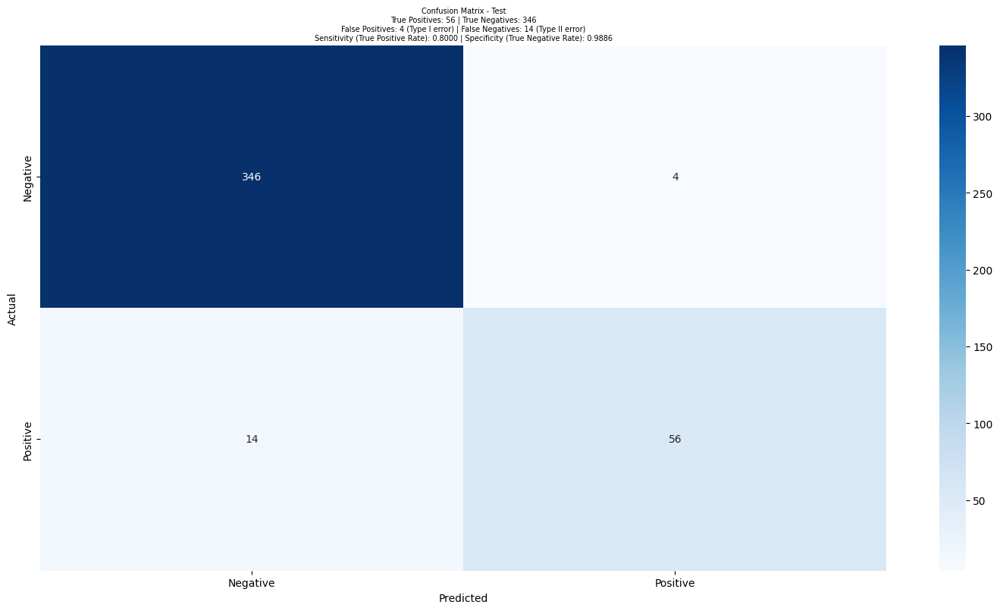

In [94]:
plot_confusion_matrix(estimator=cnn1,
                      X=X_test,  
                      y=y_test, 
                      subset_name='Test')

In [95]:
def plot_roc(estimator,X, y, subset_name):
    
    y_pred, y_prob = estimator.predict_(X)
    
    fpr, tpr, thresholds = roc_curve(y, y_prob)
    
    roc_auc = auc(fpr,tpr)

    # Print ROC Curve
    plt.figure(figsize=(18, 9))
    plt.plot(fpr, tpr, c = 'royalblue', linewidth = 2.5,label='AUC = %0.3f'% roc_auc)
    plt.plot([0,1],[0,1], c = 'firebrick', linestyle = '--')
    plt.xlim([-0.1,1.0])
    plt.ylim([-0.1,1.01])
    plt.xlabel('False positive rate (1-Specificity)')
    plt.ylabel('True positive rate (Sensitivity)')
    plt.title(f'ROC Curve - {subset_name}')
    plt.grid()
    plt.show()

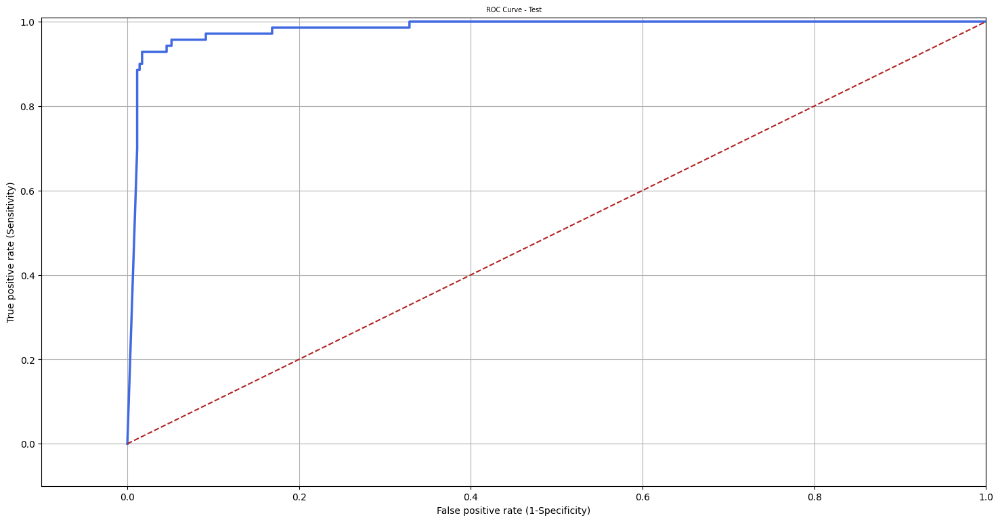

In [96]:
plot_roc(estimator=cnn1, 
         X=X_test, 
         y=y_test, 
         subset_name='Test')


### 4.1.2. Experiment B - Data Sampling Technique or Data Augmentation:
Different data sampling techniques and data augmentation strategies are explored to improve model performance: 

- Class-Imbalanced (3,500: 700)
- Over-sampling (3,500: 3500)
- Under-sampling (700: 700)


#### Over-sampling (3,500: 3500)

In [97]:
X_train, y_train, X_test, y_test, X_val, y_val = viz_class_distribution(X=X_over_sampling,
                                                                        y=y_over_sampling,
                                                                        title='Class Distribution in Train-Validation-Test Split (Over-Sampling)',
                                                                        classe_labels=['Normal', 'Tuberculosis'],
                                                                        train_percent=0.8,
                                                                        val_percent=0.1,
                                                                        test_percent=0.1,
                                                                        show_plot=False)

In [98]:
cnn2 = CNN(unit_multiplier=0.05,
           input_shape=(128,128,3))
cnn2.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_6 (Conv2D)           (None, 128, 128, 1)       28        
                                                                 
 max_pooling2d_6 (MaxPoolin  (None, 64, 64, 1)         0         
 g2D)                                                            
                                                                 
 conv2d_7 (Conv2D)           (None, 64, 64, 3)         30        
                                                                 
 max_pooling2d_7 (MaxPoolin  (None, 32, 32, 3)         0         
 g2D)                                                            
                                                                 
 conv2d_8 (Conv2D)           (None, 32, 32, 6)         168       
                                                                 
 max_pooling2d_8 (MaxPoolin  (None, 16, 16, 6)        

In [99]:
history2 = cnn2.train(X_train, y_train, X_val, y_val,
                        epochs=epochs,
                        batch_size=batch_size)

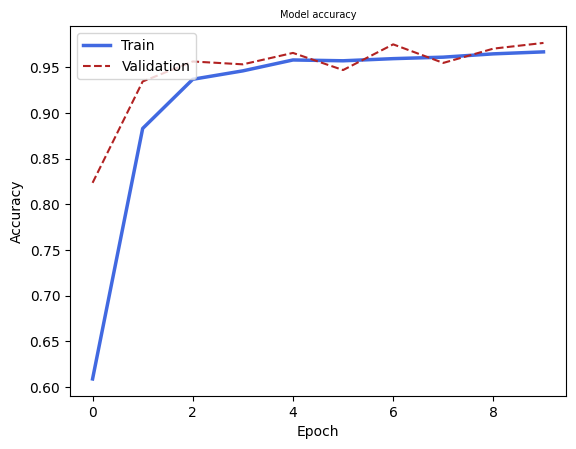

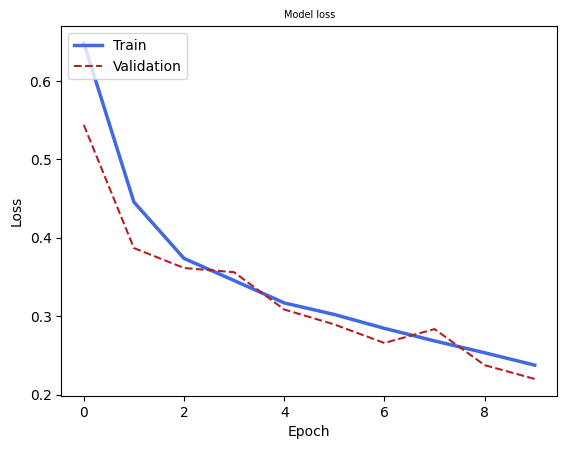

In [100]:
plot_history(history2)

In [101]:
evaluation_2 = evaluate(cnn2,
'CNN_2_Over_sampling',
'B',
X_train,
y_train,
X_test,
y_test,
X_val,
y_val)

In [102]:
evaluation_2

,Model,Experiment_tag,Subset,FPR,TPR,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
0,CNN_2_Over_sampling,B,Train,"[0.0, 0.0067857142857142855, 0.006785714285714...","[0.0, 0.8742857142857143, 0.8842857142857142, ...",2749,51,132,2668,0.967713,0.967321,0.954183,0.981243,0.967315,0.994038,0.967321
1,CNN_2_Over_sampling,B,Test,"[0.0, 0.005714285714285714, 0.0057142857142857...","[0.0, 0.8771428571428571, 0.9228571428571428, ...",346,4,16,334,0.971983,0.971429,0.955801,0.988166,0.971420,0.995037,0.971429
2,CNN_2_Over_sampling,B,Validation,"[0.0, 0.002857142857142857, 0.0028571428571428...","[0.0, 0.8914285714285715, 0.9114285714285715, ...",345,5,11,339,0.977283,0.977143,0.969101,0.985465,0.977141,0.996833,0.977143


#### Under-sampling (700: 700)

In [103]:
X_train, y_train, X_test, y_test, X_val, y_val = viz_class_distribution(X=X_norm_undersampled,
y=y_norm_undersampled,
title='Class Distribution in Train-Validation-Test Split (Under-Samping)',
classe_labels=['Normal', 'Tuberculosis'],
train_percent=0.8,
val_percent=0.1,
test_percent=0.1,
                                                                        show_plot=False)

In [104]:
cnn3 = CNN(unit_multiplier=0.05,
input_shape=(128,128,3))
cnn3.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_9 (Conv2D)           (None, 128, 128, 1)       28        
                                                                 
 max_pooling2d_9 (MaxPoolin  (None, 64, 64, 1)         0         
 g2D)                                                            
                                                                 
 conv2d_10 (Conv2D)          (None, 64, 64, 3)         30        
                                                                 
 max_pooling2d_10 (MaxPooli  (None, 32, 32, 3)         0         
 ng2D)                                                           
                                                                 
 conv2d_11 (Conv2D)          (None, 32, 32, 6)         168       
                                                                 
 max_pooling2d_11 (MaxPooli  (None, 16, 16, 6)        

In [105]:
history3 = cnn3.train(X_train, y_train, X_val, y_val,
epochs=epochs,
batch_size=batch_size)

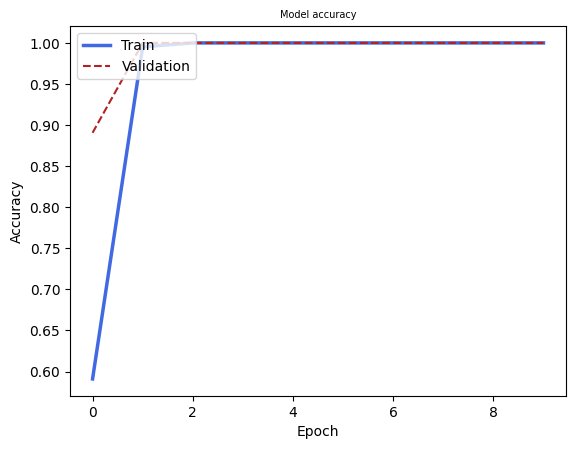

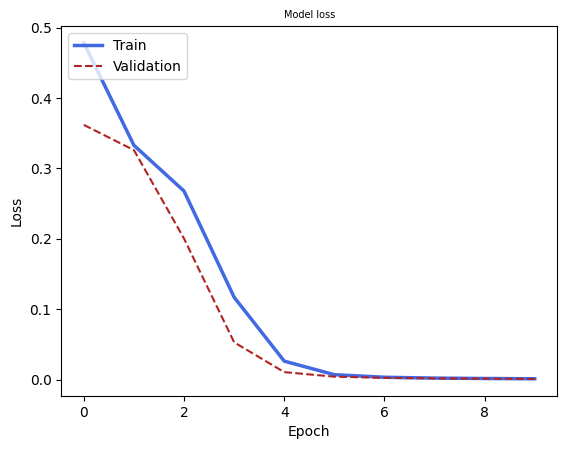

In [106]:
plot_history(history3)

In [107]:
evaluation_3 = evaluate(cnn3,
                        'CNN_3_Under_sampling',
                        'B',
                        X_train,
                        y_train,
                        X_test,
                        y_test,
                        X_val,
                        y_val)

In [108]:
evaluation_3

,Model,Experiment_tag,Subset,FPR,TPR,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
0,CNN_3_Under_sampling,B,Train,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.5017857142857143, 0.5375, 0.5642857142...",560,0,0,560,1.000000,1.000000,1.000000,1.0,1.000000,1.0,1.000000
1,CNN_3_Under_sampling,B,Test,"[0.0, 0.0, 0.0, 0.0, 0.0, 1.0]","[0.0, 0.6142857142857143, 0.7, 0.7285714285714...",70,0,1,69,0.992958,0.992857,0.985915,1.0,0.992857,1.0,0.992857
2,CNN_3_Under_sampling,B,Validation,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0]","[0.0, 0.6142857142857143, 0.6285714285714286, ...",70,0,0,70,1.000000,1.000000,1.000000,1.0,1.000000,1.0,1.000000


### 4.1.3. Experiment C - Image Size:
Investigate the impact of input image size on model performance and training time trade-off, considering sizes such as:
- 16x16
- 32x32
- 64x64 
- 128x128

Variables to use:
- X_imbalanced, y_imbalanced (Original)

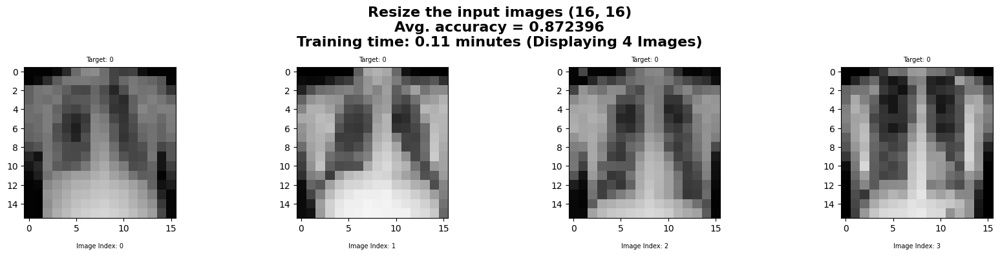

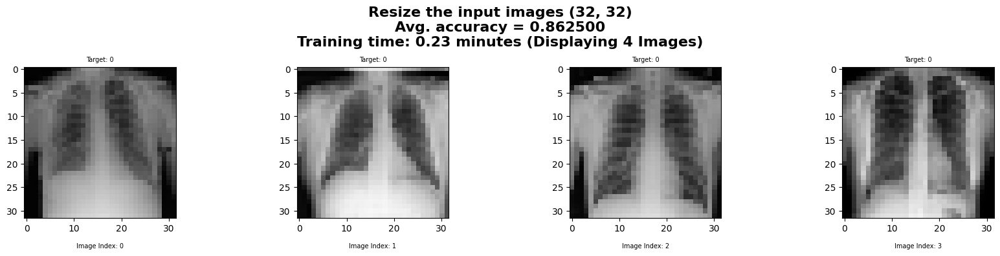

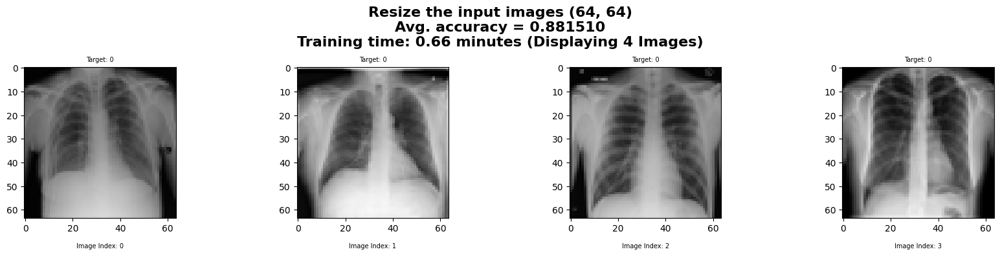

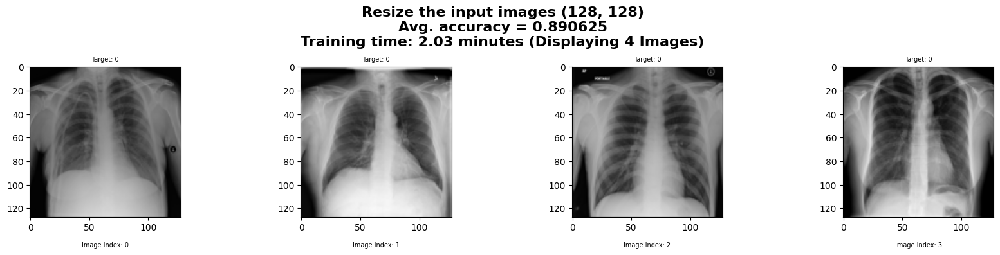

In [109]:
image_size_performances = []
target_shapes = [(16, 16),(32, 32), (64, 64), (128, 128)]
for target_shape in target_shapes:
    # Input size
    input_shape = target_shape+ (3,) 
    # Resize the Input Images
    X_resized = tf.image.resize(X_imbalanced, target_shape).numpy()
    
    # Construct CNN Model
    cnn = CNN(unit_multiplier=0.05,
    input_shape=input_shape)
    
    # Split Train/Valid/Test subset
    X_train, X_temp, y_train, y_temp = train_test_split(
    X_resized, y_imbalanced, test_size=0.2, random_state=42, stratify=y_imbalanced)

    X_test, X_val, y_test, y_val = train_test_split(
        X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)
    
    # Train the model
    start_time = time.time()

    history = cnn.train(X_train, y_train, X_val, y_val,
                        epochs=epochs,
                        batch_size=batch_size)
    end_time = time.time()
    training_time = end_time - start_time
    # Evaluate to collect performance to compare other methods
    evaluation = evaluate(cnn,
                        f"CNN_{input_shape}",
                        'C',
                        X_train,
                        y_train,
                        X_test,
                        y_test,
                        X_val,
                        y_val)
    # Collect
    image_size_performances.append(evaluation)
    # Avg. Accuracy
    mean_acc = np.mean(history.history['val_accuracy'])
    # Display input resized images
    show_image(images=X_resized, target=y_imbalanced,
               title=f'Resize the input images {target_shape}\nAvg. accuracy = {mean_acc:2f}\nTraining time: {training_time/60:.2f} minutes', 
               num_display=4, 
               num_cols=4, 
               random_mode=False)


### 4.1.4. Experiment D - Experiment D - Image Mode: RGB vs. Grayscale
Investigate the impact of different input mode of image on both RGB and grayscale images 


In [110]:
def numpy_convert_to_grayscale(X):
    converted_images = []
    for image in X:
        # Convert image data type to uint8
        image_uint8 = (image * 255).astype(np.uint8)
        # Convert RGB image to grayscale
        gray = cv2.cvtColor(image_uint8, cv2.COLOR_RGB2GRAY)
        gray = np.expand_dims(gray, axis=-1)
        converted_images.append(gray)
    return np.array(converted_images)

In [111]:
X_imbalanced_gray = numpy_convert_to_grayscale(X_imbalanced)

In [112]:
X_imbalanced_gray.shape

(4200, 128, 128, 1)

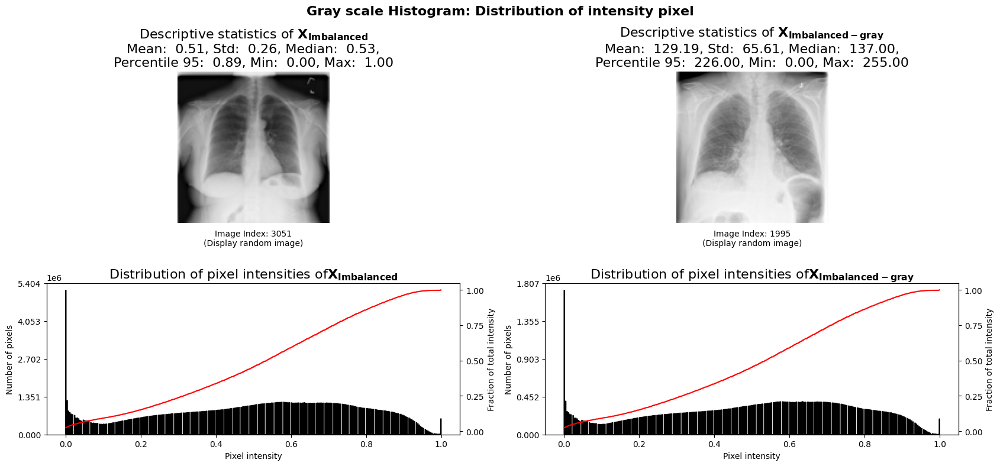

In [113]:
images = [X_imbalanced, X_imbalanced_gray]
subsets = ['X_{Imbalanced}', 'X_{Imbalanced-gray}']
# For visualization
plot_gray_scale_histogram(images=images, titles=subsets, bins=555)

In [114]:
X_train, y_train, X_test, y_test, X_val, y_val = viz_class_distribution(X=X_imbalanced_gray,
    y=y_imbalanced,
    title='Class Distribution in Train-Validation-Test Split (Gray Scale)',
    classe_labels=['Normal', 'Tuberculosis'],
    train_percent=0.8,
    val_percent=0.1,
    test_percent=0.1,
    show_plot=False)

In [115]:
cnn4 = CNN(unit_multiplier=0.05,
           input_shape=(128,128,1))
cnn4.summary()

Model: "sequential_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_24 (Conv2D)          (None, 128, 128, 1)       10        
                                                                 
 max_pooling2d_24 (MaxPooli  (None, 64, 64, 1)         0         
 ng2D)                                                           
                                                                 
 conv2d_25 (Conv2D)          (None, 64, 64, 3)         30        
                                                                 
 max_pooling2d_25 (MaxPooli  (None, 32, 32, 3)         0         
 ng2D)                                                           
                                                                 
 conv2d_26 (Conv2D)          (None, 32, 32, 6)         168       
                                                                 
 max_pooling2d_26 (MaxPooli  (None, 16, 16, 6)        

In [116]:
history4 = cnn4.train(X_train, 
                      y_train, 
                      X_val, 
                      y_val,
                      epochs=epochs,
                    batch_size=batch_size)

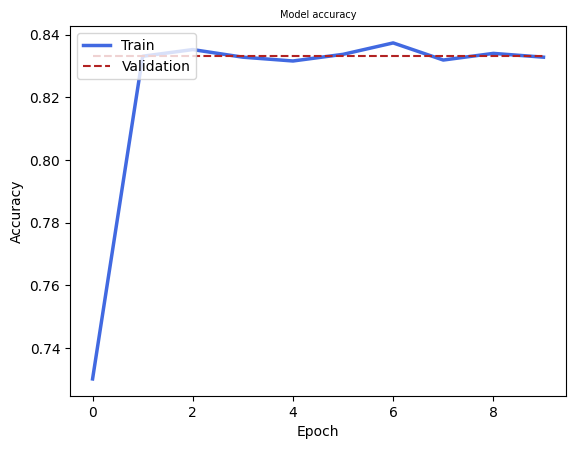

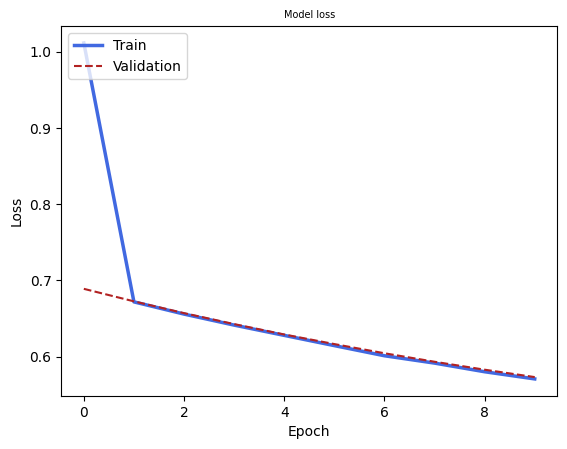

In [117]:
plot_history(history4)

In [118]:
evaluation_4 = evaluate(cnn4,
                        'CNN_4_Gray_Scale',
                        'D',
                        X_train,
                        y_train,
                        X_test,
                        y_test,
                        X_val,
                        y_val)

/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/tmp/ipykernel_19/1396738617.py:49: RuntimeWarning: invalid valu

In [119]:
evaluation_4

,Model,Experiment_tag,Subset,FPR,TPR,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
0,CNN_4_Gray_Scale,D,Train,"[0.0, 1.0]","[0.0, 1.0]",2800,0,560,0,0.694444,0.833333,0.833333,NaN,0.757576,0.500000,0.833333
1,CNN_4_Gray_Scale,D,Test,"[0.0, 0.002857142857142857, 0.9885714285714285...","[0.0, 0.0, 1.0, 1.0]",349,1,70,0,0.694113,0.830952,0.832936,0.0,0.756394,0.504286,0.830952
2,CNN_4_Gray_Scale,D,Validation,"[0.0, 0.002857142857142857, 0.9885714285714285...","[0.0, 0.0, 1.0, 1.0]",349,1,70,0,0.694113,0.830952,0.832936,0.0,0.756394,0.504286,0.830952


In [120]:
del X_imbalanced_gray

### 4.1.5. Experiment E - Image Enhancement:
What is Image enhancement technique give us the best Performance?, considering Image enhancement technique such as:
- Contrast Stretching
- Histogram Equalization
- Adaptive Histogram Equalization


#### Contrast Stretching

In [121]:
X_stretched = contrast_stretching(X_imbalanced)

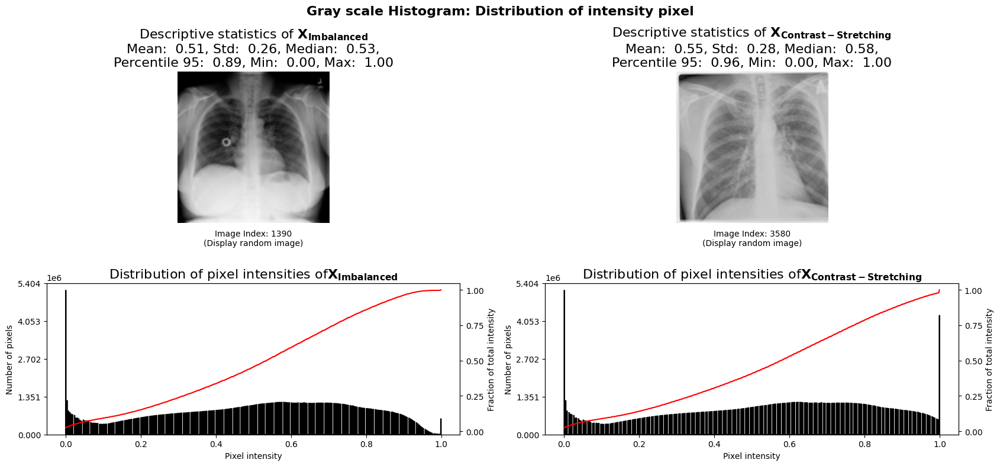

In [122]:
images = [X_imbalanced, X_stretched]
subsets = ['X_{Imbalanced}', 'X_{Contrast-Stretching}']
# For visualization
plot_gray_scale_histogram(images=images, 
                          titles=subsets, 
                          bins=555)

In [123]:
X_train, y_train, X_test, y_test, X_val, y_val = viz_class_distribution(X=X_stretched,
    y=y_imbalanced,
    title='Class Distribution in Train-Validation-Test Split (X_stretched)',
    classe_labels=['Normal', 'Tuberculosis'],
    train_percent=0.8,
    val_percent=0.1,
    test_percent=0.1,
                                                                        show_plot=False)

In [124]:
cnn5 = CNN(unit_multiplier=0.05,
        input_shape=(128,128,3))
cnn5.summary()

Model: "sequential_9"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_27 (Conv2D)          (None, 128, 128, 1)       28        
                                                                 
 max_pooling2d_27 (MaxPooli  (None, 64, 64, 1)         0         
 ng2D)                                                           
                                                                 
 conv2d_28 (Conv2D)          (None, 64, 64, 3)         30        
                                                                 
 max_pooling2d_28 (MaxPooli  (None, 32, 32, 3)         0         
 ng2D)                                                           
                                                                 
 conv2d_29 (Conv2D)          (None, 32, 32, 6)         168       
                                                                 
 max_pooling2d_29 (MaxPooli  (None, 16, 16, 6)        

In [125]:
history5 = cnn5.train(X_train, y_train, X_val, y_val,
                        epochs=epochs,
                        batch_size=batch_size)

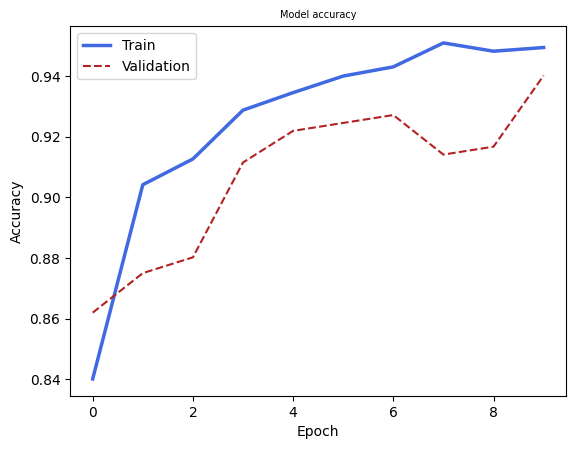

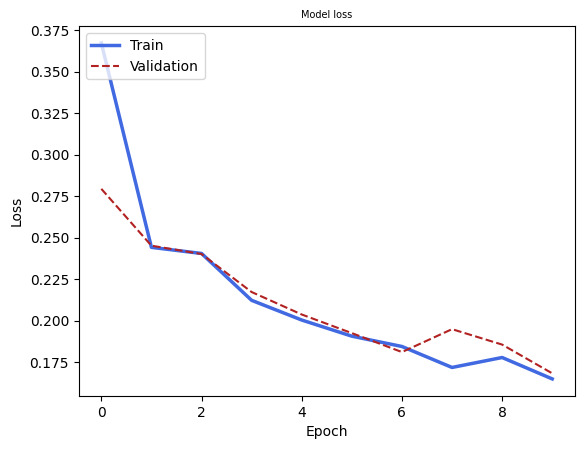

In [126]:
plot_history(history5)

In [127]:
evaluation_5 = evaluate(cnn5,
                    'CNN_5_Contrast-Stretching',
                    'E',
                    X_train,
                    y_train,
                    X_test,
                    y_test,
                    X_val,
                    y_val)

In [128]:
evaluation_5

,Model,Experiment_tag,Subset,FPR,TPR,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
0,CNN_5_Contrast-Stretching,E,Train,"[0.0, 0.0075, 0.0075, 0.008214285714285714, 0....","[0.0, 0.75, 0.7625, 0.7625, 0.7821428571428571...",2767,33,99,461,0.960081,0.960714,0.965457,0.933198,0.959713,0.987052,0.960714
1,CNN_5_Contrast-Stretching,E,Test,"[0.0, 0.008571428571428572, 0.0085714285714285...","[0.0, 0.6857142857142857, 0.7571428571428571, ...",346,4,15,55,0.954075,0.954762,0.958449,0.932203,0.953183,0.982653,0.954762
2,CNN_5_Contrast-Stretching,E,Validation,"[0.0, 0.017142857142857144, 0.0171428571428571...","[0.0, 0.6714285714285714, 0.7714285714285715, ...",344,6,19,51,0.938838,0.940476,0.947658,0.894737,0.937972,0.978245,0.940476


In [129]:
# Remove variable for memory constraint
del X_stretched

#### Histogram Equalization

In [130]:
X_eq = equalization(X_imbalanced)

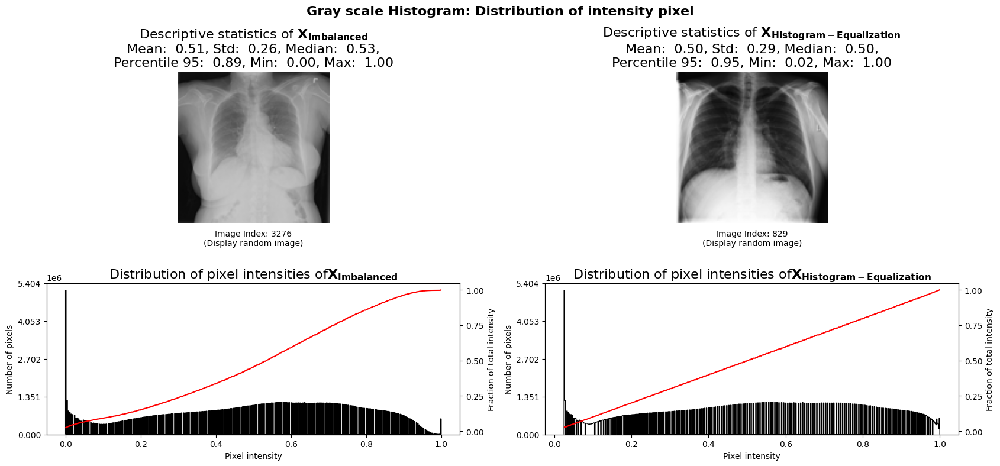

In [131]:

images = [X_imbalanced, X_eq]
subsets = ['X_{Imbalanced}', 'X_{Histogram-Equalization}']
# For visualization
plot_gray_scale_histogram(images=images, titles=subsets, bins=555)

In [132]:
X_train, y_train, X_test, y_test, X_val, y_val = viz_class_distribution(X=X_eq,
    y=y_imbalanced,
    title='Class Distribution in Train-Validation-Test Split (Histogram-Equalization)',
    classe_labels=['Normal', 'Tuberculosis'],
    train_percent=0.8,
    val_percent=0.1,
    test_percent=0.1,show_plot=False)

In [133]:
cnn6 = CNN(unit_multiplier=0.05,
input_shape=(128,128,3))
cnn6.summary()

Model: "sequential_10"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_30 (Conv2D)          (None, 128, 128, 1)       28        
                                                                 
 max_pooling2d_30 (MaxPooli  (None, 64, 64, 1)         0         
 ng2D)                                                           
                                                                 
 conv2d_31 (Conv2D)          (None, 64, 64, 3)         30        
                                                                 
 max_pooling2d_31 (MaxPooli  (None, 32, 32, 3)         0         
 ng2D)                                                           
                                                                 
 conv2d_32 (Conv2D)          (None, 32, 32, 6)         168       
                                                                 
 max_pooling2d_32 (MaxPooli  (None, 16, 16, 6)       

In [134]:
history6 = cnn6.train(X_train, y_train, X_val, y_val,
epochs=epochs,
batch_size=batch_size)

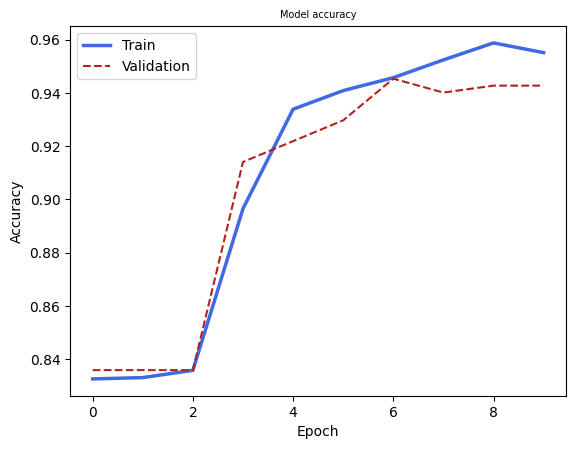

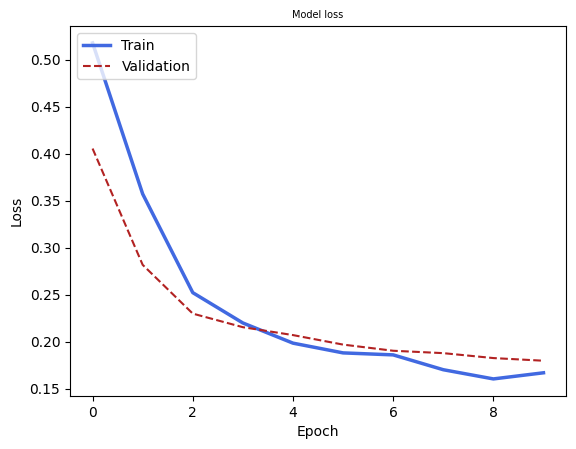

In [135]:
plot_history(history6)

In [136]:
evaluation_6 = evaluate(cnn6,
                    'CNN_6_Histogram-Equalization',
                        'E',
                    X_train,
                    y_train,
                    X_test,
                    y_test,
                    X_val,
                    y_val)

In [137]:
evaluation_6

,Model,Experiment_tag,Subset,FPR,TPR,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
0,CNN_6_Histogram-Equalization,E,Train,"[0.0, 0.0017857142857142857, 0.001785714285714...","[0.0, 0.5910714285714286, 0.6392857142857142, ...",2783,17,129,431,0.956759,0.956548,0.955701,0.962054,0.954560,0.991564,0.956548
1,CNN_6_Histogram-Equalization,E,Test,"[0.0, 0.008571428571428572, 0.0085714285714285...","[0.0, 0.38571428571428573, 0.5714285714285714,...",347,3,30,40,0.922059,0.921429,0.920424,0.930233,0.913501,0.979939,0.921429
2,CNN_6_Histogram-Equalization,E,Validation,"[0.0, 0.0, 0.0, 0.002857142857142857, 0.002857...","[0.0, 0.5, 0.6, 0.6, 0.6142857142857143, 0.614...",348,2,21,49,0.946039,0.945238,0.943089,0.960784,0.941662,0.986571,0.945238


In [138]:
# Remove variable for memory constraint
del X_eq

#### Adaptive Histogram Equalization

In [139]:
X_adapteq = adaptive_equalization(X_imbalanced, 0.01, 16)

processing...: 100%|██████████| 263/263 [02:18<00:00,  1.90it/s]


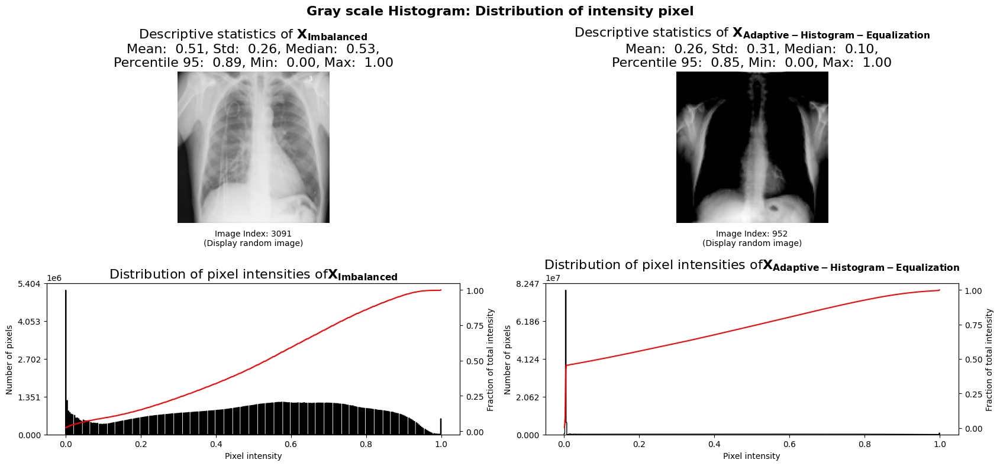

In [140]:
images = [X_imbalanced, X_adapteq]
subsets = ['X_{Imbalanced}', 'X_{Adaptive-Histogram-Equalization}']
# For visualization
plot_gray_scale_histogram(images=images, titles=subsets, bins=555)

In [141]:
X_train, y_train, X_test, y_test, X_val, y_val = viz_class_distribution(X=X_adapteq,
    y=y_imbalanced,
    title='Class Distribution in Train-Validation-Test Split (Adaptive-Histogram-Equalization)',
    classe_labels=['Normal', 'Tuberculosis'],
    train_percent=0.8,
    val_percent=0.1,
    test_percent=0.1,
                                                                        show_plot=False)

In [142]:
cnn7 = CNN(unit_multiplier=0.05,
input_shape=(128,128,3))
cnn7.summary()

Model: "sequential_11"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_33 (Conv2D)          (None, 128, 128, 1)       28        
                                                                 
 max_pooling2d_33 (MaxPooli  (None, 64, 64, 1)         0         
 ng2D)                                                           
                                                                 
 conv2d_34 (Conv2D)          (None, 64, 64, 3)         30        
                                                                 
 max_pooling2d_34 (MaxPooli  (None, 32, 32, 3)         0         
 ng2D)                                                           
                                                                 
 conv2d_35 (Conv2D)          (None, 32, 32, 6)         168       
                                                                 
 max_pooling2d_35 (MaxPooli  (None, 16, 16, 6)       

In [143]:
history7 = cnn7.train(X_train, 
                      y_train, 
                      X_val, 
                      y_val,
                    epochs=epochs,
                    batch_size=batch_size)

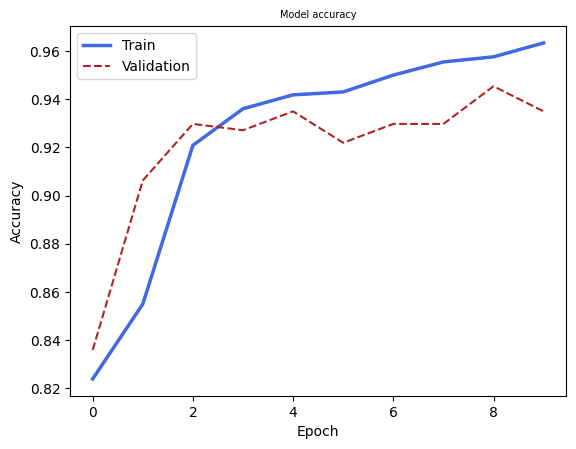

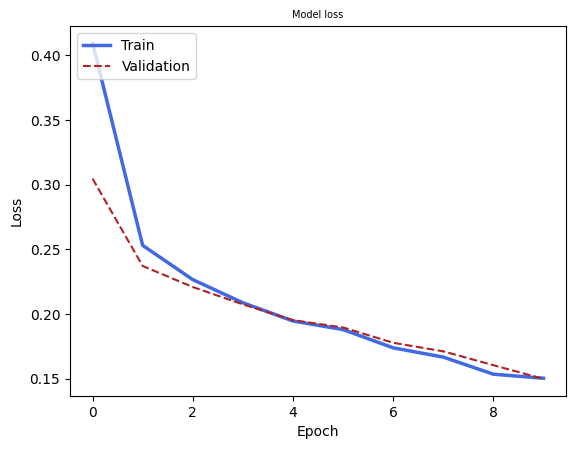

In [144]:
plot_history(history7)

In [145]:
evaluation_7 = evaluate(cnn7,
                    'CNN_7_Adaptive_Histogram_Equalization',
                        'E',
                    X_train,
                    y_train,
                    X_test,
                    y_test,
                    X_val,
                    y_val)

In [146]:
evaluation_7

,Model,Experiment_tag,Subset,FPR,TPR,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
0,CNN_7_Adaptive_Histogram_Equalization,E,Train,"[0.0, 0.009285714285714286, 0.0092857142857142...","[0.0, 0.7839285714285714, 0.7982142857142858, ...",2770,30,92,468,0.963172,0.963690,0.967855,0.939759,0.962825,0.990364,0.963690
1,CNN_7_Adaptive_Histogram_Equalization,E,Test,"[0.0, 0.011428571428571429, 0.0114285714285714...","[0.0, 0.7571428571428571, 0.8428571428571429, ...",346,4,12,58,0.961314,0.961905,0.966480,0.935484,0.960966,0.986694,0.961905
2,CNN_7_Adaptive_Histogram_Equalization,E,Validation,"[0.0, 0.014285714285714285, 0.0142857142857142...","[0.0, 0.6428571428571429, 0.7285714285714285, ...",345,5,22,48,0.934322,0.935714,0.940054,0.905660,0.932034,0.982347,0.935714



### 4.1.6. Model Benchmark/Model Comparison:
Different models are benchmarked and compared to determine which one model have the best performance for tuberculosis prediction.

In [147]:
performances = pd.concat([evaluation_1, evaluation_2, evaluation_3, evaluation_4, evaluation_5, evaluation_6, evaluation_7]+ image_size_performances, ignore_index=True)
performances

,Model,Experiment_tag,Subset,FPR,TPR,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
0,CNN_1_Baseline,A,Train,"[0.0, 0.011428571428571429, 0.0114285714285714...","[0.0, 0.7517857142857143, 0.7821428571428571, ...",2762,38,93,467,0.960313,0.961012,0.967426,0.924752,0.960195,0.985249,0.961012
1,CNN_1_Baseline,A,Test,"[0.0, 0.011428571428571429, 0.0114285714285714...","[0.0, 0.7, 0.8857142857142857, 0.8857142857142...",346,4,14,56,0.956481,0.957143,0.961111,0.933333,0.955796,0.983388,0.957143
2,CNN_1_Baseline,A,Validation,"[0.0, 0.011428571428571429, 0.0114285714285714...","[0.0, 0.6571428571428571, 0.7142857142857143, ...",342,8,15,55,0.943822,0.945238,0.957983,0.873016,0.944068,0.982204,0.945238
3,CNN_2_Over_sampling,B,Train,"[0.0, 0.0067857142857142855, 0.006785714285714...","[0.0, 0.8742857142857143, 0.8842857142857142, ...",2749,51,132,2668,0.967713,0.967321,0.954183,0.981243,0.967315,0.994038,0.967321
4,CNN_2_Over_sampling,B,Test,"[0.0, 0.005714285714285714, 0.0057142857142857...","[0.0, 0.8771428571428571, 0.9228571428571428, ...",346,4,16,334,0.971983,0.971429,0.955801,0.988166,0.971420,0.995037,0.971429
5,CNN_2_Over_sampling,B,Validation,"[0.0, 0.002857142857142857, 0.0028571428571428...","[0.0, 0.8914285714285715, 0.9114285714285715, ...",345,5,11,339,0.977283,0.977143,0.969101,0.985465,0.977141,0.996833,0.977143
6,CNN_3_Under_sampling,B,Train,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.5017857142857143, 0.5375, 0.5642857142...",560,0,0,560,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
7,CNN_3_Under_sampling,B,Test,"[0.0, 0.0, 0.0, 0.0, 0.0, 1.0]","[0.0, 0.6142857142857143, 0.7, 0.7285714285714...",70,0,1,69,0.992958,0.992857,0.985915,1.000000,0.992857,1.000000,0.992857
8,CNN_3_Under_sampling,B,Validation,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0]","[0.0, 0.6142857142857143, 0.6285714285714286, ...",70,0,0,70,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
9,CNN_4_Gray_Scale,D,Train,"[0.0, 1.0]","[0.0, 1.0]",2800,0,560,0,0.694444,0.833333,0.833333,NaN,0.757576,0.500000,0.833333


In [148]:
cmap = 'RdYlGn'  # Red-Yellow-Green gradient
included_cols = ['Model', 'Subset', 'TP', 'FP', 'FN', 'TN', 'Precision',
       'Recall', 'Sensitivity', 'Specificity', 'F1 Score', 'AUC', 'Accuracy']

### Experiment A - Baseline Performance
**Explanation**: know minimum acceptable "Accuracy" for the baseline performance

In [149]:
performances.loc[performances['Experiment_tag']== 'A'][included_cols].style.background_gradient(cmap=cmap, subset=['F1 Score', 'Accuracy'])

,Model,Subset,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
0,CNN_1_Baseline,Train,2762,38,93,467,0.960313,0.961012,0.967426,0.924752,0.960195,0.985249,0.961012
1,CNN_1_Baseline,Test,346,4,14,56,0.956481,0.957143,0.961111,0.933333,0.955796,0.983388,0.957143
2,CNN_1_Baseline,Validation,342,8,15,55,0.943822,0.945238,0.957983,0.873016,0.944068,0.982204,0.945238


### Experiment B - Data Sampling Technique or Data Augmentation

- **Explanation**: We focus on comparing the `F1 score` across various sampling methods 
- **Conclusion**: Based on the `F1 score` comparison, we selected the `Over-sampling` technique, Because have the highest score

In [150]:
performances.loc[performances['Experiment_tag']== 'B'][included_cols].style.background_gradient(cmap=cmap, subset=['F1 Score'])

,Model,Subset,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
3,CNN_2_Over_sampling,Train,2749,51,132,2668,0.967713,0.967321,0.954183,0.981243,0.967315,0.994038,0.967321
4,CNN_2_Over_sampling,Test,346,4,16,334,0.971983,0.971429,0.955801,0.988166,0.971420,0.995037,0.971429
5,CNN_2_Over_sampling,Validation,345,5,11,339,0.977283,0.977143,0.969101,0.985465,0.977141,0.996833,0.977143
6,CNN_3_Under_sampling,Train,560,0,0,560,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
7,CNN_3_Under_sampling,Test,70,0,1,69,0.992958,0.992857,0.985915,1.000000,0.992857,1.000000,0.992857
8,CNN_3_Under_sampling,Validation,70,0,0,70,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Experiment C - Image Size
- **Explanation**: Obviously larger image sizes tend to capture more detailed information, allowing the models to learn more discriminative features achieve better performance on "Accuracy".
- **Conclusion**: Size of 128x128 pixels showed the best overall performance 

In [151]:
performances.loc[performances['Experiment_tag']== 'C'][included_cols].style.background_gradient(cmap=cmap, subset=['Accuracy'])

,Model,Subset,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
21,"CNN_(16, 16, 3)",Train,2732,68,145,415,0.934536,0.936607,0.949600,0.859213,0.934697,0.964488,0.936607
22,"CNN_(16, 16, 3)",Test,341,9,20,50,0.928408,0.930952,0.944598,0.847458,0.928543,0.970735,0.930952
23,"CNN_(16, 16, 3)",Validation,345,5,24,46,0.929460,0.930952,0.934959,0.901961,0.926444,0.955959,0.930952
24,"CNN_(32, 32, 3)",Train,2756,44,228,332,0.916824,0.919048,0.923592,0.882979,0.912378,0.955985,0.919048
25,"CNN_(32, 32, 3)",Test,344,6,32,38,0.906351,0.909524,0.914894,0.863636,0.900826,0.932898,0.909524
26,"CNN_(32, 32, 3)",Validation,347,3,33,37,0.915132,0.914286,0.913158,0.925000,0.904359,0.961265,0.914286
27,"CNN_(64, 64, 3)",Train,2777,23,178,382,0.940338,0.940179,0.939763,0.943210,0.936180,0.980886,0.940179
28,"CNN_(64, 64, 3)",Test,348,2,28,42,0.930368,0.928571,0.925532,0.954545,0.921705,0.969612,0.928571
29,"CNN_(64, 64, 3)",Validation,346,4,28,42,0.923119,0.923810,0.925134,0.913043,0.917191,0.977531,0.923810
30,"CNN_(128, 128, 3)",Train,2773,27,146,414,0.948115,0.948512,0.949983,0.938776,0.945987,0.982752,0.948512


### Experiment D - Image Mode: RGB vs. Grayscale
- **Explanation**: Investigated the impact of using different image modes (RGB and Grayscale) on model performance.
- **Conclusion**: RGB > Grayscale, RGB images contain three channels (Red, Green, and Blue), which capture richer color information compared to Grayscale images, which have only one channel.

In [152]:
# RGB
performances.loc[performances['Experiment_tag']== 'A'][included_cols].style.background_gradient(cmap=cmap, subset=['Accuracy'])

,Model,Subset,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
0,CNN_1_Baseline,Train,2762,38,93,467,0.960313,0.961012,0.967426,0.924752,0.960195,0.985249,0.961012
1,CNN_1_Baseline,Test,346,4,14,56,0.956481,0.957143,0.961111,0.933333,0.955796,0.983388,0.957143
2,CNN_1_Baseline,Validation,342,8,15,55,0.943822,0.945238,0.957983,0.873016,0.944068,0.982204,0.945238


In [153]:
# Grayscale
performances.loc[performances['Experiment_tag']== 'D'][included_cols].style.background_gradient(cmap=cmap, subset=['Accuracy'])

,Model,Subset,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
9,CNN_4_Gray_Scale,Train,2800,0,560,0,0.694444,0.833333,0.833333,nan,0.757576,0.500000,0.833333
10,CNN_4_Gray_Scale,Test,349,1,70,0,0.694113,0.830952,0.832936,0.000000,0.756394,0.504286,0.830952
11,CNN_4_Gray_Scale,Validation,349,1,70,0,0.694113,0.830952,0.832936,0.000000,0.756394,0.504286,0.830952


### Experiment E - Image Enhancement
- **Conclusion**: based on the `F1 Score`, `Accuracy`  metrics, `Histogram Equalization	` appears to be the best image enhancement technique on 3 subsets

## 4.2 Train for Best Artifact
- **Experiment A - Baseline Performance**: 97% Accuracy
- **Experiment B - Data Sampling Technique or Data Augmentation**: Over-sampling
- **Experiment C - Image Size**: 128x128
- **Experiment D - Image Mode: RGB vs. Grayscale**: RGB
- **Experiment E - Image Enhancement**: Histogram Equalization

In [154]:
X_over_sampling_eq = equalization(X_over_sampling)

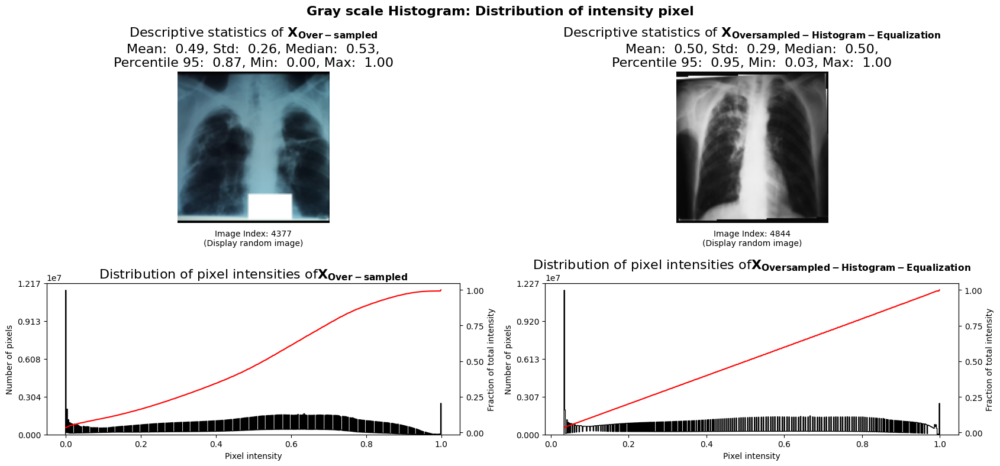

In [155]:
images = [X_over_sampling, X_over_sampling_eq]
subsets = ['X_{Over-sampled}', 'X_{Oversampled-Histogram-Equalization}']
# For visualization
plot_gray_scale_histogram(images=images, titles=subsets, bins=555)

In [156]:
X_train, y_train, X_test, y_test, X_val, y_val = viz_class_distribution(X=X_over_sampling_eq,
                                                                        y=y_over_sampling,
                                                                        title='Class Distribution in Train-Validation-Test Split (Oversampled-With-Histogram-Equalization)',
                                                                        classe_labels=['Normal', 'Tuberculosis'],
                                                                        train_percent=0.8,
                                                                        val_percent=0.1,
                                                                        test_percent=0.1,
                                                                        show_plot=False)

In [157]:
cnn_ba = CNN(unit_multiplier=0.1,
             input_shape=(128,128,3),
             verbose=1)
cnn_ba.summary()

Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_36 (Conv2D)          (None, 128, 128, 3)       84        
                                                                 
 max_pooling2d_36 (MaxPooli  (None, 64, 64, 3)         0         
 ng2D)                                                           
                                                                 
 conv2d_37 (Conv2D)          (None, 64, 64, 6)         168       
                                                                 
 max_pooling2d_37 (MaxPooli  (None, 32, 32, 6)         0         
 ng2D)                                                           
                                                                 
 conv2d_38 (Conv2D)          (None, 32, 32, 12)        660       
                                                                 
 max_pooling2d_38 (MaxPooli  (None, 16, 16, 12)      

In [158]:
history_ba = cnn_ba.train(X_train, 
                          y_train, 
                          X_val, 
                          y_val,
                          epochs=30,
                          batch_size=32)

Epoch 1/30
175/175 [==============================] - 27s 146ms/step - loss: 0.2651 - accuracy: 0.8864 - val_loss: 0.1510 - val_accuracy: 0.9390
Epoch 2/30
175/175 [==============================] - 24s 136ms/step - loss: 0.1313 - accuracy: 0.9514 - val_loss: 0.0853 - val_accuracy: 0.9747
Epoch 3/30
175/175 [==============================] - 25s 145ms/step - loss: 0.1037 - accuracy: 0.9616 - val_loss: 0.0670 - val_accuracy: 0.9717
Epoch 4/30
175/175 [==============================] - 25s 143ms/step - loss: 0.0773 - accuracy: 0.9762 - val_loss: 0.0649 - val_accuracy: 0.9732
Epoch 5/30
175/175 [==============================] - 25s 143ms/step - loss: 0.0802 - accuracy: 0.9730 - val_loss: 0.0563 - val_accuracy: 0.9807
Epoch 6/30
175/175 [==============================] - 24s 140ms/step - loss: 0.0636 - accuracy: 0.9770 - val_loss: 0.0485 - val_accuracy: 0.9836
Epoch 7/30
175/175 [==============================] - 25s 143ms/step - loss: 0.0489 - accuracy: 0.9832 - val_loss: 0.0586 - val_ac

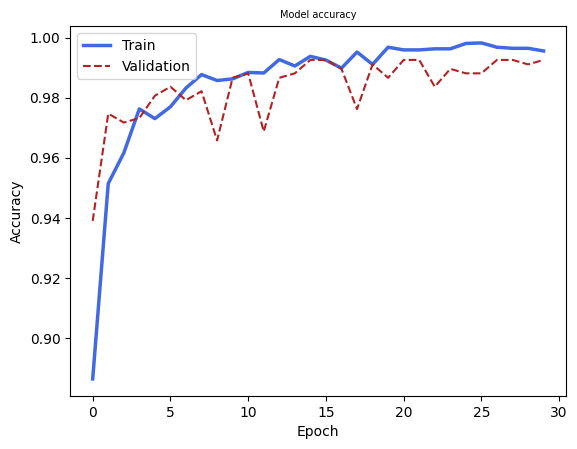

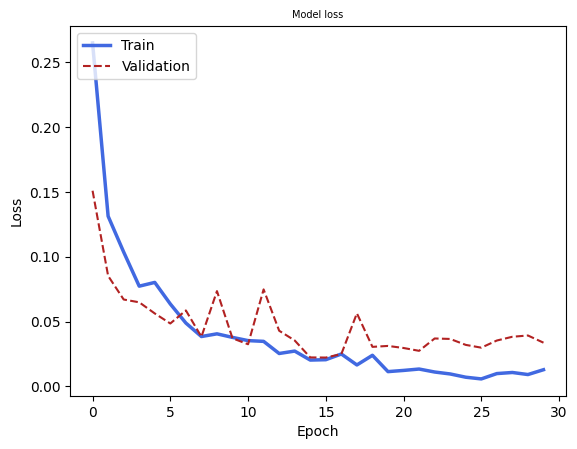

In [159]:
plot_history(history_ba)

## 4.3 Model Evaluation

In [160]:
evaluation_ba = evaluate(cnn_ba,
                    'CNN_best_artifact',
                         'L',
                    X_train,
                    y_train,
                    X_test,
                    y_test,
                    X_val,
                    y_val)

22/22 [==============================] - 1s 51ms/step


In [161]:
evaluation_ba

,Model,Experiment_tag,Subset,FPR,TPR,TP,FP,FN,TN,Precision,Recall,Sensitivity,Specificity,F1 Score,AUC,Accuracy
0,CNN_best_artifact,L,Train,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.5410714285714285, 0.5632142857142857, ...",2799,1,5,2795,0.998930,0.998929,0.998217,0.999642,0.998929,0.999997,0.998929
1,CNN_best_artifact,L,Test,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.5457142857142857, 0.5628571428571428, ...",347,3,0,350,0.995751,0.995714,1.000000,0.991501,0.995714,0.999951,0.995714
2,CNN_best_artifact,L,Validation,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.5657142857142857, 0.6, 0.6057142857142...",348,2,4,346,0.991445,0.991429,0.988636,0.994253,0.991429,0.999176,0.991429


### 4.3.1 Confusion Matrix
<u>Objective</u>: for evaluating the performance of a classification model, understanding the types of errors the model is making, such as misclassifications or false positives/negatives.

|                   | Predicted Negative | Predicted Positive |
|-------------------|--------------------|--------------------|
| Actual Negative   | TN                 | FP                 |
| Actual Positive   | FN                 | TP                 |

In simpler terms:

- **True Positive (TP)**: When the `model` <u>predicts</u> a patient `have disease`, and it is `correct`.
- **True Negative (TN)**: When the `model` <u>predicts</u> a patient `have disease`, But it is `incorrect`. So this is misclassify
- **False Positive (FP)**: When the `model` <u>predicts</u>  a patient `don't have disease`, and it is `correct`.
- **False Negative (FN)**: When the `model` <u>predicts</u> a patient `don't have disease`, But it is `incorrect`. So this is misclassify

22/22 [==============================] - 1s 51ms/step


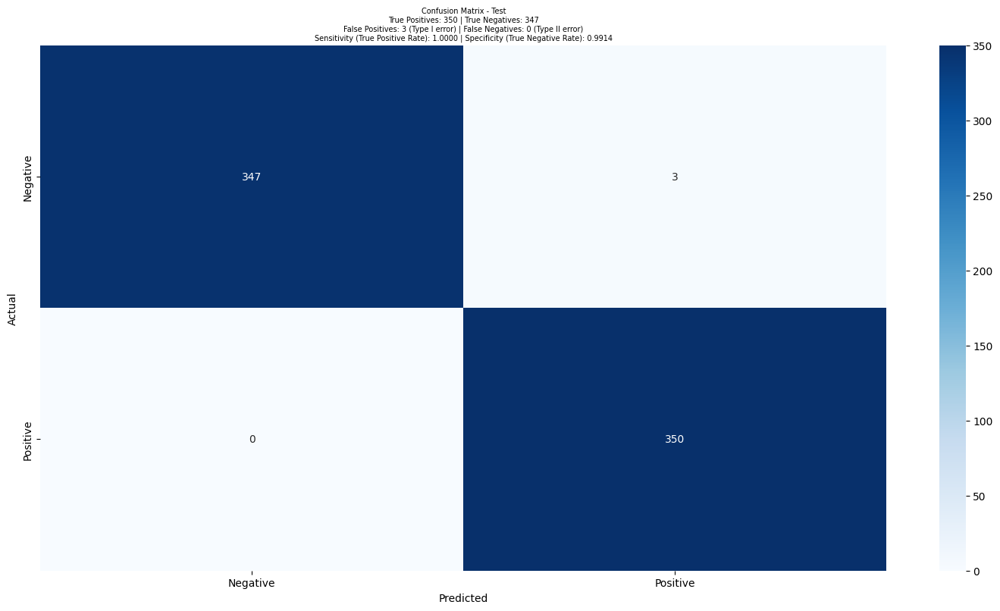

In [162]:
plot_confusion_matrix(estimator=cnn_ba,
                      X=X_test,  
                      y=y_test, 
                      subset_name='Test')

### 4.3.2 ROC Curve
<u>Objective</u>: measures the model's ability to distinguish between positive and negative classes. AUC close to 1 indicates better discrimination ability.

22/22 [==============================] - 1s 49ms/step


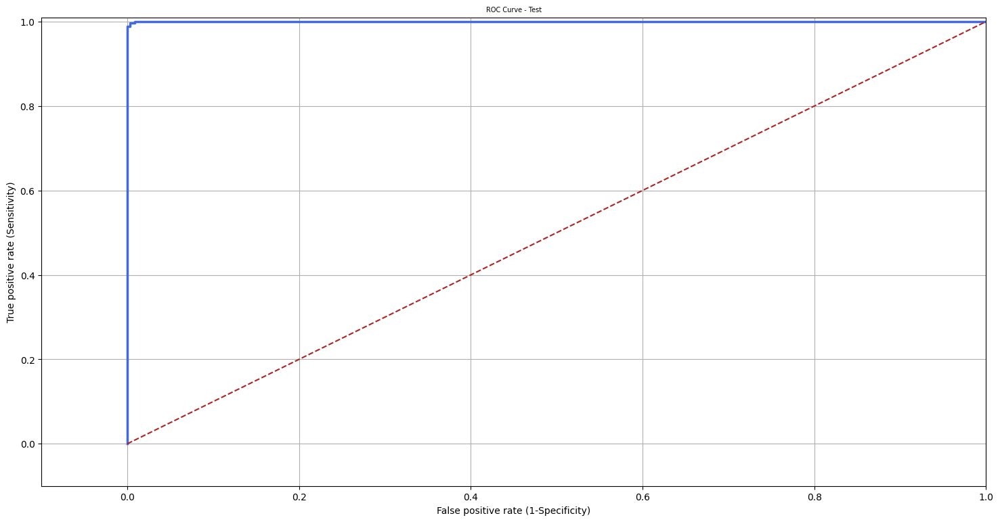

In [163]:
plot_roc(estimator=cnn_ba, 
         X=X_test, 
         y=y_test, 
         subset_name='Test')

### 4.3.3 Cross-validation (Skipped, Because of Memory constraint)
<u>Objective</u>: Ensure model performances are averaged over the iterations across different subsets of data.

In [164]:
# cv_scores = cnn_ba.cv(X=X_over_sampling_eq, y=y_over_sampling, cv=5)

In [165]:
# plt.figure(figsize=(10, 6))
# bars = plt.bar(range(1, len(cv_scores) + 1), cv_scores)
# plt.title('Cross-Validation Scores')
# plt.xlabel('Fold')
# plt.ylabel('Validation Score')
# plt.grid(axis='y')  # Display gridlines only along the y-axis

# # Add text annotations to each bar
# for bar in bars:
#     height = bar.get_height()
#     plt.text(bar.get_x() + bar.get_width() / 2, height, round(height, 2),
#              ha='center', va='bottom')

# plt.show()

## 4.4 Hyperparameter Tuning (Skipped, Because of Memory constraint)

In [166]:
from sklearn.model_selection import GridSearchCV

In [167]:
"""
Only selected parameters are uncommented for tuning:
    unit_multiplier: Controls the size of the model.
    learning_rate: The learning rate for the Adam optimizer.
"""

# param_grid = {
#     'unit_multiplier': [0.05, 0.1, 0.5],
# #     'conv_kernel_size': [(3, 3), (5, 5)],
# #     'conv_stride': [1, 2],
# #     'dropout': [0.2, 0.5],
#     'learning_rate': [0.01,0.001, 0.0001],
# #     'epochs': [20],
# #     'batch_size': [32, 64]
# }

'\nOnly selected parameters are uncommented for tuning:\n    unit_multiplier: Controls the size of the model.\n    learning_rate: The learning rate for the Adam optimizer.\n'

In [168]:
# cnn_tuning = CNN(unit_multiplier=0.05,
#                 input_shape=(128,128,3))

### GridSearchCV
GridSearchCV stands for Grid Search Cross-Validation.  
- It use to automates the process of hyperparameter tuning
- It's a technique for systematically working through multiple combinations of hyperparameters, tuning them to find the best parameters for a given model and dataset.

explain each parameter used in the GridSearchCV function:
- `estimator`: This parameter specifies the estimator object. In this case, `cnn_tuning` is the estimator, which is CNN model that you want to tune.
- `param_grid`: This parameter is a dictionary or a list of dictionaries. It represents the grid of parameters to search over during the grid search. Each `key` in the dictionary <u>corresponds</u> to a `parameter name`, and the values are lists of parameter settings to try.
- `cv`: This parameter is an integer or a cross-validation generator. It determines the cross-validation splitting strategy. In your case, `cv=3` means you're using 3-fold cross-validation.
- `verbose`: This parameter <u>controls</u> the verbosity of the grid search. Higher values mean more information will be printed during the grid search. Here, `verbose=10` means the most detailed information will be printed.
- `n_jobs`: This parameter specifies the number of jobs to run in parallel. 
    - Setting it to `1` <u>means</u> that the grid search will use only one CPU core. 
    - If you set it to -1, it will use all available CPU cores.

In [169]:
# grid_search = GridSearchCV(estimator=cnn_tuning, param_grid=param_grid, cv=3, verbose=10, n_jobs=1)

# # Perform grid search
# grid_search.fit(X_train, y_train)

In [170]:

# # Print the best parameters found
# print("Best parameters found:")
# print(grid_search.best_params_)

# # Get the best model
# best_model = grid_search.best_estimator_

# # Evaluate the best model on the test set
# test_accuracy = best_model.evaluate(X_test, y_test, verbose=1)
# print("Test Accuracy:", test_accuracy)

## 4.5 Compare Actual X-ray Images with Model Predictions.

In [171]:
def compare_actual_and_predicted_xray(estimator, images, target, title, num_display=16, num_cols=4, random_mode=False):
    '''
    Compare Actual X-ray Images with Model Predictions.

    Parameters:
        estimator: Model used for predictions.
        images (ndarray): Input data as a numpy array.
        target (ndarray): Target data as a numpy array.
        title (str): Title of the plot.
        num_display (int, optional): Number of images to display. Default is 16.
        num_cols (int, optional): Number of columns in the plot. Default is 4.
        random_mode (bool, optional): If True, display images randomly. If False, display the first num_display images. Default is False.

    Returns:
        None

    This function generates a visual comparison between actual X-ray images and their corresponding model predictions. It displays a grid of images with labels to show whether the model's predictions match the actual target values. The grid is organized in rows and columns based on the specified parameters.

    The function does not return any values; it displays the comparison plot directly.
    '''

    n_cols = min(num_cols, num_display)
    n_rows = int(np.ceil(num_display / n_cols))

    title = r'$\bf{' + "Actual-Image" + '}$' + " vs " + \
        r'$\bf{' + "Model-Prediction" + '}$'
    y_pred, y_prob = estimator.predict_(images)

    n_images = min(num_display, len(images))
    if random_mode:
        random_indices = np.random.choice(
            len(images), num_display, replace=False)
    else:
        random_indices = np.arange(num_display)

    fig, axes = plt.subplots(
        nrows=n_rows, ncols=n_cols, figsize=(20, 4*n_rows))
    for i, ax in enumerate(axes.flatten()):
        if i >= n_images:  # Check if the index exceeds the available number of images
            break
        # Incase (Did PCA)
        index = random_indices[i]
        if len(images.shape) == 2:
            image = images[index].reshape((128, 128)).astype(int)
        else:
            image = images[index]
        actual_label = int(target[index])
        model_pred_label = int(y_pred[index])
        model_prob = '{:.3f}'.format(float(y_prob[index]))
        ax.imshow(
            image, cmap='gray' if actual_label == model_pred_label else 'OrRd')
        ax.set_title(
            f"Actual: {actual_label},\nModel Prediction: {model_pred_label}\nProbability: {model_prob}")
    plt.suptitle(f"{title} (Displaying {num_display} Images)",
                 fontsize=16, fontweight='bold')

    fig.set_facecolor('white')
    plt.tight_layout()  
    plt.show()

22/22 [==============================] - 1s 49ms/step


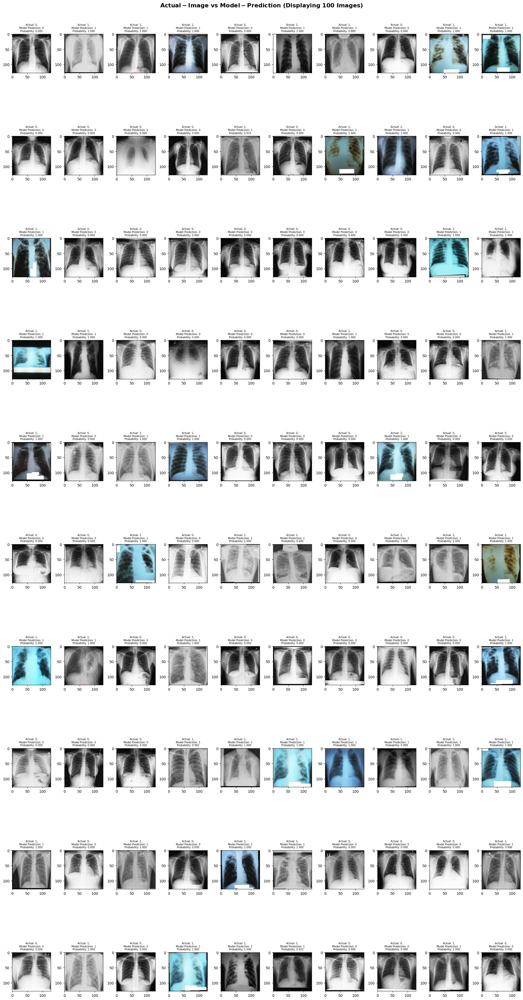

In [172]:
compare_actual_and_predicted_xray(
                estimator=cnn_ba,
                images=X_test,
                target=y_test, 
                title=None,
                num_display=100,
                num_cols=10, 
                random_mode=True)

# 5. Lung segmentation
**Objective**: adapt this Lung segmentation for LIME
steps:
- Equalize the image with CLAHE
- Create a threshold mask to separate tissue by pixel intensity
- Find regions in the threshold
- Remove borders
- Fill small holes
- Extract lung areas

**Reference**: [Lung Segmentation without CNN](https://www.kaggle.com/code/davidbroberts/lung-segmentation-without-cnn/notebook)


In [173]:
import cv2 as cv

from skimage.filters import threshold_otsu
from skimage.color import label2rgb
from skimage.morphology import closing, square
from skimage.measure import label, regionprops
from skimage.segmentation import clear_border

import matplotlib.patches as mpatches

In `segmentize` function

## 5.1 Equalize the Image with CLAHE
```python
X = exposure.equalize_adapthist(
            X, clip_limit=clip_limit, nbins=nbins)
```
The first step enhances the contrast of the input image (`X`) using Contrast Limited Adaptive Histogram Equalization (CLAHE). This process redistributes the intensity values in a way that makes the histogram more uniform. The `exposure.equalize_adapthist` function from the `skimage` library is utilized for this purpose.

## 5.2 Create a Binary Threshold Mask
```python
thresh = threshold_otsu(image=X, nbins=256, hist=None)
```

After equalization, a binary threshold mask is created to separate tissue based on pixel intensity. This is achieved by applying the Otsu method, which automatically calculates the optimal threshold value. Pixels with intensity values greater than the threshold are set to `True`, while those less than or equal to the threshold are set to `False`. The result is stored in the `thresh` variable.

**Read more**: [Skikit-image: Thresholding](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_thresholding.html)

## 5.3 Perform Morphological Operations
Morphological operations are then performed on the binary mask to refine it:

### 5.3.1 Morphological: Closing

```python
closing_image = closing(binary_image, square(1))
```

<u>Objective</u>:Closing operation: Applied to fill small holes and smooth out regions in the mask. 


### 5.3.2 Morphological: Dilation
```python
dilation_image = cv.dilate(binary_image,kernel,iterations = 1)
```

<u>Objective</u>:Dilation operation: Applied to enlarges the circle, adding pixels to its border.

**Read more**: [OpenCV: Morphological Transformations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html)

**Read more**: [Example of Morphological Operations in Image Processing](https://medium.com/@rod_alenton/a-comprehensive-guide-to-morphological-operations-in-image-processing-36ed8361e2b0)

## 5.4 Label Image Regions

```python
# Clean up the borders
cleared = clear_border(bw)

# Label image regions
label_image = label(cleared)
```

- Border clearance: Objects touching the image border, which are likely artifacts, are removed using the `clear_border` function.
- Connected regions in the binary mask are labeled using the `label` function from the `skimage.measure` module. Each connected region is assigned a unique label. This labeled image is useful for identifying and analyzing individual objects or regions within the image.

## 5.5 Create Overlay Image
```python
image_label_overlay = label2rgb(
            label_image,
            image=X,
            bg_label=0,
            bg_color=(0, 0, 0))
```
The labeled image is converted into a color overlay image using the `label2rgb` function from the `skimage.color` module. This overlay image assigns a unique color to each labeled region, making it easier to visualize and analyze.

In [174]:
class ImageSegmentation:
    def __init__(self, input_shape, clip_limit=0.01, sqr_value=1):
        self.input_shape = input_shape
        self.clip_limit = clip_limit
        self.sqr_value = sqr_value

        
    def segmentize(self, X, return_only_overlay=True):
        X = X[:, :, 0]
        # 5.1 Equalize the image with CLAHE
        X = exposure.equalize_adapthist(
            X, clip_limit=self.clip_limit, nbins=256)

        # 5.2 Create a binary threshold mask and apply it to the image
        thresh = threshold_otsu(image=X, nbins=256, hist=None)
        # Invert Binary Image       
        thresh = X > thresh
        # 5.3 Morphological
        # 5.3.1 Closing
        closing_image = closing(X > thresh, square(self.sqr_value))
        
        # 5.4 Clean up the borders
        cleared = clear_border(closing_image)

        # Label image regions
        label_image = label(cleared)
        
        # 5.5 Overlay Image
        image_label_overlay = label2rgb(
            label_image,
            image=X,
            bg_label=0,
            bg_color=(0, 0, 0))
        
        if return_only_overlay:
            return image_label_overlay, label_image
        else:
            return X, thresh, closing_image, cleared, image_label_overlay, label_image
        
    def create_rectangle_box(self, ax, label_image):
        # regionprops finds unique objects in binary/labeled images
        region_sum = 0
        
        for region in regionprops(label_image):
            region_sum += region.area

        region_avg = region_sum/len(label_image)
        regionprops_array = regionprops(label_image)
        region_areas = []
        
        for region in regionprops_array:
            # Only get large regions, 250,000 is a reasonably large enough area for lung fields, but this might take some tweaking
            region_areas.append(region.area)
            if region.area >= region_avg:


                # draw a box around segments
                minr, minc, maxr, maxc = region.bbox
                rect = mpatches.Rectangle((minc, minr), maxc - minc, maxr - minr, fill=False, edgecolor='purple', linewidth=1)
                ax.add_patch(rect)
        return region_sum, region_areas
    def display_how_segmentize_work_steps(self, images, target, title, num_display=16, cmap='gray', random_mode=False):
        '''
        :Parameters
            images (ndarray (n,)): Input data as a numpy array.
            target (ndarray (n,)): Target data as a numpy array.
            title (String): Title of the plot.
            num_display (int): Number of images to display. Default is 16.
            cmap (str): Color map for displaying images. Default is 'gray'.
            random_mode (bool): If True, display images randomly. If False, display the first num_display images. Default is False.
        '''
        # Determine the number of rows and columns for the subplot grid
        n_cols = 7 # Number of steps
        n_rows = min(num_display, len(images))

        # Choose random indices if random_mode is True
        if random_mode:
            random_indices = np.random.choice(
                len(images), n_rows, replace=False)
        else:
            random_indices = np.arange(n_rows)

        # Create the subplot grid
        fig, axes = plt.subplots(
            nrows=n_rows, ncols=n_cols, figsize=(17, 4*n_rows))

        # Iterate over each image
        for i, ax in enumerate(axes.flatten()):
            if i >= n_rows:  # Check if the index exceeds the available number of images
                break
            # Get the index of the current image
            index = random_indices[i]

            # Get the current image
            image = images[index]

            # Segmentize the image and display each step row by row
            X_equalized, thresh,  closing_image, cleared, image_label_overlay, label_image = self.segmentize(
                image, return_only_overlay=False)
            steps = [(image, "Input-Original Image"), (X_equalized, "Equalized Image"), (thresh, "Thresholded Image"),
                     (closing_image, "Closing Image"), (cleared, f"Cleaned Image\nnumber of segments: {len(np.unique(label_image))}"), (image_label_overlay, "Overlay Image"),
                     (label_image, "Output-Segmentized Image")]

            # Plot each step in a row
            for j, (step_img, step_title) in enumerate(steps):
                ax = axes[i, j]  # Use i, j to index axes correctly
                ax.imshow(step_img, cmap=cmap)
                ax.set_title(f"Step {j}: "+ step_title, fontsize=7)

                # Hide axes ticks and labels
                ax.axis("off")

        # Set the overall title of the plot
        plt.suptitle(f"{title} (Displaying {n_rows} Images)",
                     fontsize=12, fontweight='bold')

        fig.set_facecolor('white')
        plt.tight_layout()
        plt.show()
        
    def display(self,images, target, title, num_display=16, num_cols=4, cmap=None, random_mode=False,only_segmented=True):
        '''
        :Parameters
            images (ndarray (n,)): Input data as a numpy array.
            target (ndarray (n,)): Target data as a numpy array.
            title (String): Title of the plot.
            num_display (int): Number of images to display. Default is 16.
            num_cols (int): Number of columns in the plot. Default is 4.
            cmap (str): Color map for displaying images. Default is 'gray'.
            random_mode (bool): If True, display images randomly. If False, display the first num_display images. Default is False.
        '''
        # Determine the number of rows based on the num_cols parameter
        n_cols = min(num_cols, num_display)
        n_rows = int(np.ceil(num_display / n_cols))

        n_images = min(num_display, len(images))
        if random_mode:
            random_indices = np.random.choice(
                len(images), num_display, replace=False)
        else:
            random_indices = np.arange(num_display)

        fig, axes = plt.subplots(
            nrows=n_rows, ncols=n_cols, figsize=(17, 4*n_rows))
        for i, ax in enumerate(axes.flatten()):
            if i >= n_images:  # Check if the index exceeds the available number of images
                break
            image = images[i]

            image_label_overlay, label_image = self.segmentize(
                image)
                
            """
                Display Segmented Lung area on an Image
            """
            
            if cmap:
                ax.imshow(
                    label_image if only_segmented else image_label_overlay, cmap=cmap)
            else:
                ax.imshow(
                label_image if only_segmented else image_label_overlay)
            
            
            """
                
                Create a Rectangle box where large regions area for lung fields 
            """
            # Iterate through the regions
            
            
            region_sum, region_areas = self.create_rectangle_box(ax, label_image)
            
            
            set_title = f"""
                Target: {target[i]}
                number of segments: {len(region_areas)}
                Sum. region: {region_sum}
            """
            ax.set_title(set_title,fontsize=7 )

            # Add image index as text
            ax.text(0.5, -0.25, f'Index: {i}', transform=ax.transAxes,
                    fontsize=7, ha='center')

        plt.suptitle(f"{title} (Displaying {num_display} Images)",
                    fontsize=12, fontweight='bold')
    
        fig.set_facecolor('white')
        plt.tight_layout() 
        return plt.show()

Input parameter explanation:
- `input_shape`: (Input image size) - tuple (height and width) For example, `input_shape=(128, 128)` 
- `clip_limit`: (controls  dark and bright) - parameter controls how constrast or dark and bright on an image (default is`0.01`) for to get region of lung on an image
- `sqr_value`: (smooth of segmentation) - size of the square structuring element used in morphological operations. A larger value results in more aggressive smoothing and filling of regions. (default is`1`).

In [175]:
IST = ImageSegmentation(input_shape=(128,128), 
                        clip_limit=0.015, 
                        sqr_value=1)

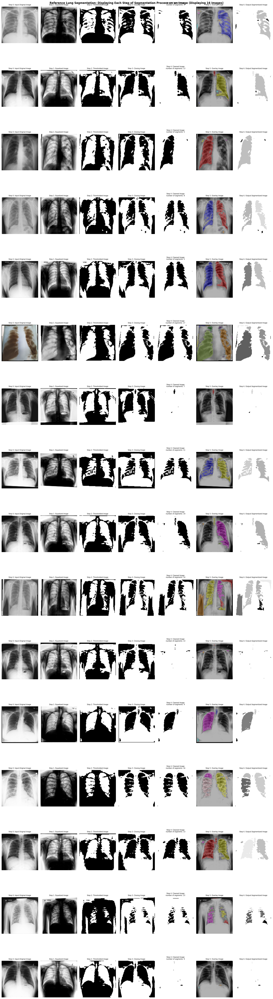

In [176]:
IST.display_how_segmentize_work_steps(images=X_over_sampling_eq,
                                      target=y_over_sampling,
                                      num_display=16, 
                                      title='Reference Lung Segmentation: Displaying Each Step of Segmentation Process on an Image',
                                      cmap='binary',
                                      random_mode= True)

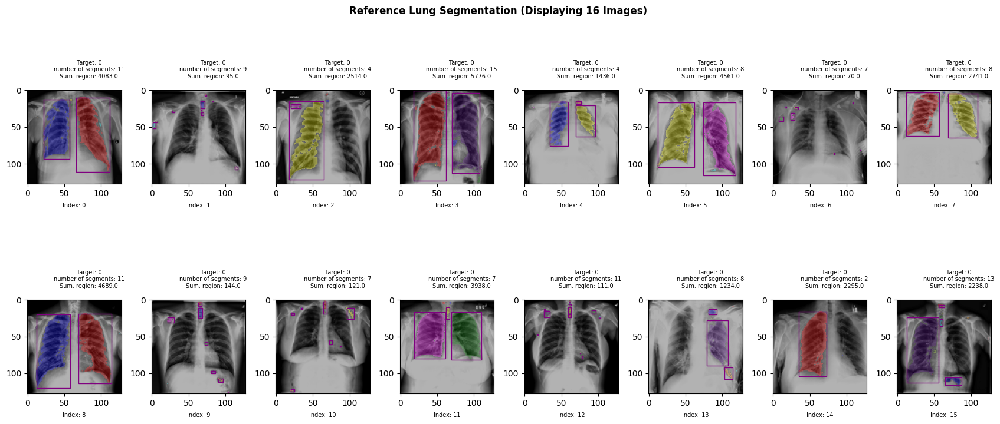

In [177]:
IST.display(images=X_over_sampling_eq,
                       target=y_over_sampling,
                       num_display=16, 
                       num_cols=8,
                       title='Reference Lung Segmentation',
                       cmap='binary',
                       random_mode=False,
                       only_segmented=False)

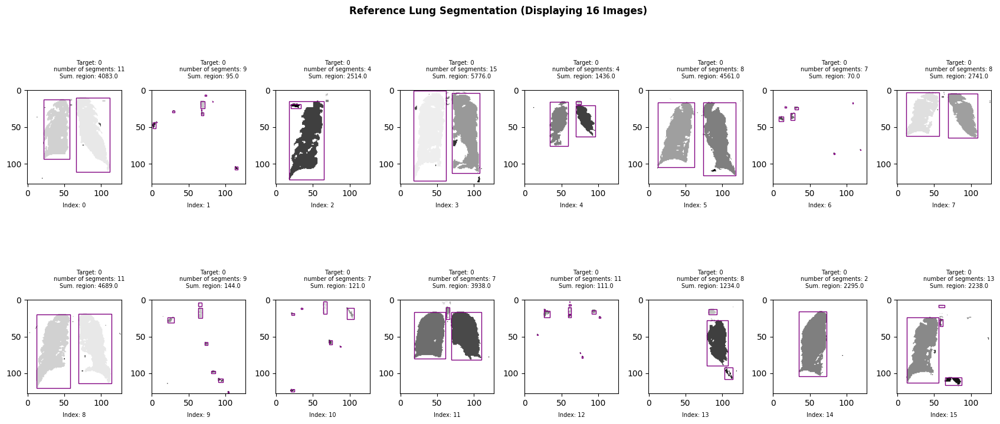

In [178]:
IST.display(images=X_over_sampling_eq,
             target=y_over_sampling,
             num_display=16, num_cols=8,
             title='Reference Lung Segmentation',
             cmap='binary',
             random_mode=False,
             only_segmented=True)

# 6. Explainability
## 6.1 Lime Library

**Local Interpretable Model-Agnostic Explanations (LIME)** 

is a library that explains predictions of machine learning models in an interpretable and understandable way. LIME works by training a local surrogate model around each prediction instance to approximate the behavior of the complex model. The surrogate model is then used to explain the prediction's outcome by highlighting the features that contributed the most to the decision.

**LIME**

is short for "Local Interpretable **Model-agnostic Explanations.**" It deals with explaining predictions made by **image-based** models, highlighting which areas of the input image were most influential in the model's decision-making process.

**Use to**

- **Interpretable** Literally translated, LIME is a method for translating the behavior of models that are difficult to understand so that normal people like us can understand them.

- **Model-Agnostic** This means that the LIME method can be used with any model, whether the model is a model that can read its behavior (such as linear regression, decision trees) or the model is so complex that we don't know its inner behavior (such as a neural network. ), which means we can view the model we use as a black-box.

- used to **explain why** a specific image was classified as it was by identifying the segmented areas (features) that had the most impact on the model's prediction.
- To **visualize** and **understand** Model's predictions

**Objective**: used to explain the cnn model prediction's outcome by highlighting lung region, identifying the segmented areas (features) that had the most impact on the model's prediction. 

**Read more:** 
- [Community](https://notebook.community/marcotcr/lime/doc/notebooks/Tutorial%20-%20Image%20Classification%20Keras)
- [Document](https://lime-ml.readthedocs.io/en/latest/lime.html)
- [How to Use LIME to Interpret Predictions of ML Models?](https://coderzcolumn.com/tutorials/machine-learning/how-to-use-lime-to-understand-sklearn-models-predictions)

In [179]:
# Lime
import lime
from lime.lime_image import LimeImageExplainer
# Ski
from skimage.segmentation import mark_boundaries
from skimage.color import gray2rgb
from skimage.transform import resize

import skimage.segmentation

# common
import numpy as np
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt
import random

import cv2
import matplotlib.patches as mpatches
from skimage.filters import threshold_otsu
from skimage.exposure import equalize_adapthist
from skimage.color import label2rgb
from skimage.segmentation import clear_border
from skimage.measure import label, regionprops
from skimage.morphology import square, closing
from skimage.segmentation import felzenszwalb, slic, quickshift, watershed
from skimage.filters import sobel
from skimage.color import rgb2gray

In [180]:
class Explainer:
    def __init__(self, estimator, input_shape=None):
        """
        Initialize the Explainer object.

        Parameters:
            estimator (object): The machine learning model to be explained.
            input_shape (tuple, optional): The shape of the input images. Default is None.
        """
        self.estimator = estimator
        self.input_shape = input_shape
        self.explainer = LimeImageExplainer()
        self.IST = ImageSegmentation(input_shape=input_shape, 
                        clip_limit=0.015, 
                        sqr_value=1)
        
        
        self.methods = [
            (felzenszwalb, {'scale': 200, 'sigma': 0.5, 'min_size': 50}, "felzenszwalb"),
            (slic, {'n_segments': 50, 'compactness': 10, 'sigma': 1}, 'slic'),
            (quickshift, {'kernel_size': 2, 'max_dist': 50, 'ratio': 0.5}, 'quickshift'),
            (watershed, {'markers': 50, 'compactness': 0.001}, 'watershed'),
            (self.ref_lung_segmentation, {}, 'reference_lung_segmentation')
        ]
        
    def transform(self, image):
        """
        Resize the input image to the specified input shape.

        Parameters:
            image (ndarray): The input image to be resized.

        Returns:
            ndarray: The resized image.
        """
        image_resized = tf.image.resize(image, self.input_shape).numpy()
        return image_resized
    
    def segment_fn(self, seg_method):
        """
        Get the segmentation function based on the segmentation method.

        Parameters:
            seg_method (str): The segmentation method.

        Returns:
            function: The segmentation function corresponding to the method.
        
        Raises:
            ValueError: If the segmentation method is invalid.
        """
        if seg_method == 'felzenszwalb':
            return felzenszwalb
        elif seg_method == 'slic':
            return slic
        elif seg_method == 'quickshift':
            return quickshift
        elif seg_method == 'watershed':
            return watershed
        elif seg_method == 'reference_lung_segmentation':
            return self.ref_lung_segmentation
        else:
            raise ValueError(
                "Invalid segmentation method. Supported methods: 'felzenszwalb', 'slic', 'quickshift', 'watershed', 'reference_lung_segmentation'")
    
    def lime(self, image, a_y_pred, seg_method, top_labels, num_samples, num_features):
        """
        Generate Lime explanations for the input image.

        Parameters:
            image (ndarray): The input image.
            a_y_pred (int): The predicted label for the image.
            seg_method (str): The segmentation method.
            top_labels (int): The top labels to consider.
            num_samples (int): Number of samples for Lime.
            num_features (int): Number of features for Lime explanations.

        Returns:
            tuple: Tuple containing the Lime explanation image and mask.
        """
        explanation = self.explainer.explain_instance(
                image,
                self.estimator.predict,
                top_labels=top_labels,
                hide_color=0,
                num_samples=num_samples,
                segmentation_fn=self.segment_fn(seg_method),
            )
        
        pos_condition = True if a_y_pred == 1 else False
        
        # condition variable: If model's prediction is Disease or 1, then display/reveal positive region on image
        temp, mask = explanation.get_image_and_mask(
            0,
            positive_only=pos_condition,
            num_features=num_features,
            hide_rest=False,
            min_weight=0.0,
            )
        return temp, mask
    
    def display_explanation_plot(self, X, y, y_pred, y_prob , seg_method, top_labels, num_samples, num_features, class_names, num_display, random_mode):
        """
        Display the explanation plot for model predictions using Lime.

        Parameters:
            X (ndarray): Input data as a numpy array.
            y (ndarray): Target data as a numpy array.
            y_pred (ndarray): Predicted labels for the input data.
            y_prob (ndarray): Predicted probabilities for the input data.
            seg_method (str): The segmentation method.
            top_labels (int): The top labels to consider.
            num_samples (int): Number of samples for Lime.
            num_features (int): Number of features for Lime explanations.
            class_names (list): List of class names.
            num_display (int): Number of images to display.
            random_mode (bool): If True, display images randomly.
        """
        prefix_bold = r'$\bf{'
        suffix_bold = '}$'
        """
            Number of rows/columns of the subplot grid.
        """
        n_cols = 4  # Display 4 images in each row
        n_rows = min(num_display, len(X))

        # Choose random indices if random_mode is True
        if random_mode:
            random_indices = np.random.choice(
                len(X), n_rows, replace=False)
        else:
            random_indices = np.arange(n_rows)
            
        # Create the subplot grid
        fig, axes = plt.subplots(
            nrows=n_rows, ncols=n_cols, figsize=(15, n_cols*n_rows))
        fig.subplots_adjust(hspace=0.4)  # Adjust vertical space between rows
        for i, ax in enumerate(axes.flatten()):
            if i >= n_rows:  # Check if the index exceeds the available number of images
                break
            # Get the index of the current image
            index = random_indices[i]
            
            """
                Transform
            """
            X_resized = self.transform(X[index])
            """
                Acutal & Prediction
                - apply int():  to make sure it's integer when checking condition, For example:
                    - 1 == 1 is True
                    - 1.0 == 1 is False
            """
        
            single_y_actual = int(y[index])
            single_y_pred = int(y_pred[index])
            single_y_prob = y_prob[index]
            
            temp, mask = self.lime(X_resized, single_y_pred, seg_method, top_labels, num_samples, num_features)
            """
                Plot Title 
            """
            
            # Title A
            A_actual_class = class_names.get(single_y_actual)  
            A_actual_title = prefix_bold + 'Actual' + suffix_bold + '\nTarget: ' + f"{single_y_actual} ({A_actual_class})"
            # Title B
            B_model_class = class_names.get(single_y_pred)  
            B_model_prob = '{:.5f}'.format(float(single_y_prob))
            B_model_title = prefix_bold + 'Model-Prediction' + suffix_bold + f'\nProbability: ' + B_model_prob + '\nTarget: ' + f"{single_y_pred} ({B_model_class})"
            
            
            # Find the segmentation method kwargs
            kwarg = None
            for (method, kwargs, title) in self.methods:
                if title == seg_method:
                    kwarg = kwargs
                    break  

            if kwarg is None:
                kwargs = {}  
                    
            # Title C
            segmentation_method = self.segment_fn(seg_method)
            segmentized_image = segmentation_method(X_resized, **kwarg)
            
            num_segments = len(np.unique(segmentized_image))
            C_segmentaion_title = prefix_bold + 'Segmentation' + suffix_bold  + f'\nmethod:{seg_method}\nnumber of segments: {num_segments}'
            # Title D
            D_lime_title = prefix_bold + 'LIME-Explanation' + suffix_bold + f'\ndisplay: {num_features} features' + f'\nPositive and Negative regions'

            # Actual 
            """
                Show
            """
            axes[i,0].imshow(X_resized, cmap=cmap) 
            axes[i,0].set_title(A_actual_title)
            
            image_label_overlay = label2rgb(
                segmentation_method(X_resized, **kwarg),
                image=X_resized,
                bg_label=0,
                bg_color=(0, 0, 0))
            
            # Model prediction 
            axes[i,1].imshow(X_resized, cmap=cmap)
            axes[i,1].imshow(image_label_overlay)

            axes[i,1].set_title(B_model_title)
            # Segmentation

            axes[i,2].imshow(segmentized_image,cmap='binary')
            axes[i,2].set_title(C_segmentaion_title)
            # Lime
            boundaried_image = mark_boundaries(temp/2 + 0.5, mask)
            
            axes[i,3].imshow(boundaried_image)
            axes[i,3].set_title(D_lime_title)
            
            # Add the image index text
            image_info = f'Image Index: {index}'
            x_axis = 0.5
            y_axis = -0.15
            plt.text(x_axis, y_axis, image_info, transform=axes[i,0].transAxes,
                     fontsize=10, ha='center')
        
        title = prefix_bold + "Model-Explainability" + suffix_bold + f"\n{prefix_bold}Library{suffix_bold}: Lime"+ f"\n{prefix_bold}Segmentation{suffix_bold}: {seg_method}"
        plt.suptitle(title, fontsize=14)
        plt.tight_layout()
        plt.show()
        

    def explain(self, X, y, top_labels, num_samples, num_features, class_names, num_display, seg_method='slic', random_mode=False, cmap='gray'):
        '''
        Explain and visualize model predictions using LIME (Local Interpretable Model-Agnostic Explanations).

        Parameters:
            X (ndarray): Input data as a numpy array.
            y (ndarray): Target data as a numpy array.
            top_labels (int): Top coefficients to show (e.g., 1 for binary classification).
            num_samples (int): Number of perturbations to generate.
            num_features (int): Number of highlighted features (segmented areas) to extract.
            class_names (dict): List of class names contains key and value. (For examples, {"Normal": 0, "Tuberculosis":1})
            num_display (int): Number of images to display.
            seg_method (str, optional): The segmentation method to use. Default is 'slic'.
            random_mode (bool, optional): If True, display images randomly. Default is False.
            cmap (str, optional): Colormap for displaying images. Default is 'gray'.

        Returns:
            None

        This function explains and visualizes model predictions using LIME. It generates explanations for model predictions and displays them along with various image representations.

        Note:
        - The `X` input should have a shape like (num_images, width, height, channels) (e.g., (100, 128, 128, 1)).
        - The `class_names` list should contain class labels.
        - The function displays the explanations and does not return any values.
        '''

        # Model prediction
        y_pred, y_prob = self.estimator.predict_(X)
        self.display_explanation_plot(X, y, y_pred, y_prob, seg_method, top_labels, num_samples, num_features,class_names, num_display, random_mode)
        
    def diff_segmentation(self, image):
        """
        Display the effect of different segmentation methods on an image.

        Parameters:
            image (ndarray): The input image.
        """
        sample_index = random.randint(0, image.shape[0] - 1)
        image = image[sample_index]
        fig, ax = plt.subplots(1, 5, figsize=(17, 6))

        for i, (method, kwargs, title) in enumerate(self.methods):
            if method == watershed:
                gradient = sobel(rgb2gray(image))
                segments = method(gradient, **kwargs)  # Pass gradient to watershed
            elif method == self.ref_lung_segmentation:
                segments = method(image)  # Just pass image to your custom segmentation
            else:
                segments = method(image, **kwargs)  # For other methods, pass image directly
            ax[i].imshow(mark_boundaries(image, segments))
            ax[i].set_title(title)
            ax[i].text(
                0.5, -0.05, f"number of segments: {len(np.unique(segments))}", transform=ax[i].transAxes, ha='center')
            ax[i].set_axis_off()

        plt.tight_layout()
        plt.show()

    def ref_lung_segmentation(self, image, return_overlay=False):
        """
        Perform lung segmentation on the input image.

        Parameters:
            image (ndarray): The input image.
            return_overlay (bool, optional): Whether to return the segmentation overlay image. Default is False.

        Returns:
            ndarray: The lung segmentation mask.
        """
        image_label_overlay, label_image = IST.segmentize(
                image)
        if return_overlay:
            return image_label_overlay, label_image
        else:
            return label_image

In [181]:
explnr = Explainer(estimator=cnn_ba, input_shape=(128, 128))

## 6.2 Different segmentation methods on an image

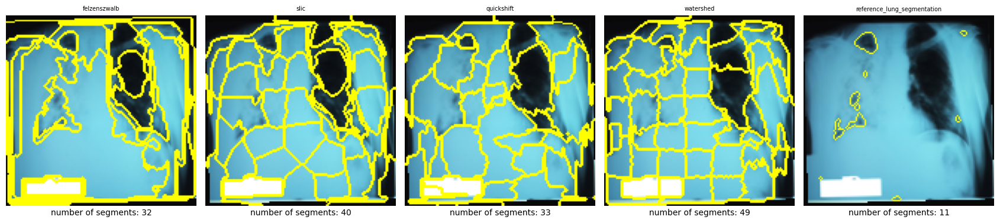

In [182]:
explnr.diff_segmentation(image=X_test)

## 6.3 Lime Image Explainer

**Explanation**:

- **Segmentation Quality**: The segmentation method, reference lung segmentation, accurately identifies lung areas in some images, facilitating precise Lime explanations. However, in certain cases, segmentation may be poor, impacting Lime's interpretability due to difficulties in identifying relevant features. This highlights the importance of enhanced segmentation techniques in medical imaging for more dependable disease detection.
- **LimeImageExplainer**:
    - **Red Color**: Highlights regions where the model fails to detect disease or leans towards a negative diagnosis.
    - **Green Color**: Indicates areas suggestive of disease or a positive diagnosis.

In [183]:
"""
    top_labels:  top_labels set to 1, Lime consider the top class predicted by the model, In this case binary classification tasks where you are interested in explaining the model's prediction for the positive class.
"""
top_labels = 1

num_samples = 100
num_features = 5
"""
    class_names: Class label, 
        0 assigned as Normal class, 
        1 assigned as Tuberculosis class
"""
class_names = {0: "Normal", 1:"Tuberculosis"}
num_display = 20

* This "reference_lung_segmentation" is not suitable with explainer

22/22 [==============================] - 1s 48ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 [==============================] - 0s 40ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 [==============================] - 0s 43ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

... (32 outputs left out)

1/1 [==============================] - 0s 40ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 [==============================] - 0s 39ms/step


/tmp/ipykernel_19/307380149.py:229: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


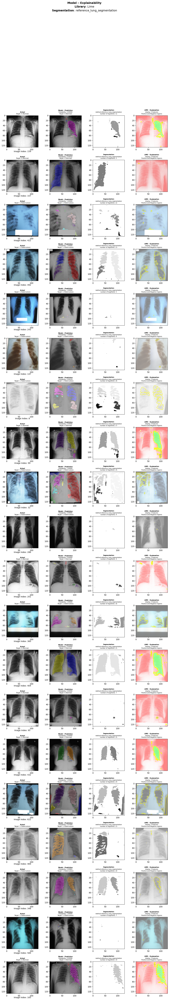

In [184]:
explnr.explain(X=X_test,
            y=y_test,
            top_labels=top_labels,
            num_samples=num_samples,
            num_features=num_features,
            class_names=class_names,
            num_display=num_display,
            seg_method='reference_lung_segmentation',
            random_mode=True,
            cmap='gray'
            )

22/22 [==============================] - 1s 49ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 [==============================] - 0s 39ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 [==============================] - 0s 38ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

... (32 outputs left out)

1/1 [==============================] - 0s 38ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 [==============================] - 0s 39ms/step


/tmp/ipykernel_19/307380149.py:229: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


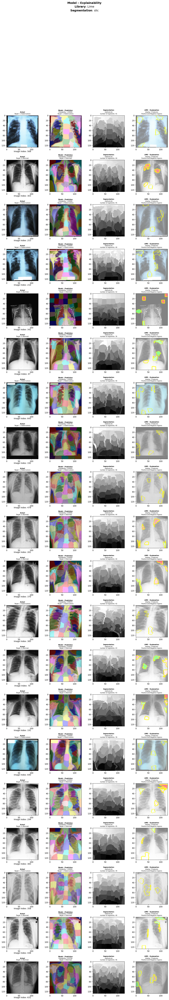

In [185]:
explnr.explain(X=X_test,
            y=y_test,
            top_labels=top_labels,
            num_samples=num_samples,
            num_features=num_features,
            class_names=class_names,
            num_display=num_display,
            seg_method='slic',
            random_mode=True,
            cmap='gray'
            )


22/22 [==============================] - 1s 48ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 [==============================] - 0s 50ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 [==============================] - 0s 39ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

... (32 outputs left out)

1/1 [==============================] - 0s 44ms/step


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 [==============================] - 0s 43ms/step


/tmp/ipykernel_19/307380149.py:229: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


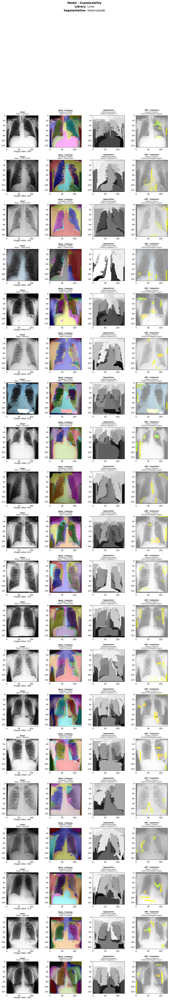

In [186]:
explnr.explain(X=X_test,
            y=y_test,
            top_labels=top_labels,
            num_samples=num_samples,
            num_features=num_features,
            class_names=class_names,
            num_display=num_display,
            seg_method='felzenszwalb',
            random_mode=True,
            cmap='gray'
            )
